# Sell in May, Buy at Halloween? A Historical Test of the Halloween Indicator — v7

**The rule:** Hold US stocks from the final October close to the final April close; hold short-term T-bill exposure from May through October. Compare that calendar rule with continuously owning stocks, cash, and a monthly rebalanced 50/50 stock/cash mix.

**Two linked questions, one investment decision:**

| | Question | Primary test |
|---|---|---|
| **H1 — Seasonality** | Are November–April stock returns higher than May–October returns? | Mean annual winter-minus-summer stock return (`W_minus_S`). Supporting: price-index log-return regression |
| **H2 — The trading decision** | Did selling for the summer actually improve performance compared with holding stocks? | Mean annual Halloween-minus-buy-and-hold return (`HW_minus_BH`). Supporting: May–October stocks minus T-bills (`summer_premium`), which sets its sign each year |

H1 can be true while H2 is false. Stocks can rise less during summer yet still beat T-bills. Both claims belong in the same video **if the story moves quickly from the seasonal pattern to whether the rule pays**.

Useful identities for each complete Halloween year:

- **Halloween minus buy-and-hold** = `(1 + winter stock return) × (summer cash return − summer stock return)`; if winter wealth remains positive, its sign depends exclusively on the relative May–October returns.
- The **50/50 comparison** holds roughly the same *average share of dollars in stocks*, using monthly rebalancing, but does **not** precisely risk-match the calendar strategy. It helps assess exposure versus timing without eliminating risk, path, or rebalancing differences.
- Two **different regressions** below: the traditional Halloween-dummy test uses monthly log *price-index* returns to test seasonality; a separate monthly simple *excess-return* regression asks whether summer stocks exceeded cash. Neither alone settles implementation, fees, or taxes.

**Sections**: 0 setup/self-tests; 1 data and audit; 2 seasonality and executable strategies; 3 dividends/cash; 4 six-month-window and 924-calendar descriptive checks; 4b St Leger's Day; 5 1998/2002 splits and recent periods; 5b cutoff sensitivity, post-publication risk check and growth of $1 since 2003/1999; 5c quant scorecard (Sharpe CIs, alpha t-statistics, information ratio, net of costs, by decade, rolling alpha, resume lines); 6 other markets (price-return caveats); 7 turnover and stylized taxes; 8 robustness; 9 current incomplete season; 10 production figures and recording checklist.

### Before you lock numbers

1. **Clean run.** Set `REFRESH_DOWNLOADS = True`, then **Kernel → Restart & Run All**. Set it back to `False` afterwards. Quote numbers only from one top-to-bottom run.
2. **Sample end.** Run on or before October 31, 2026 and the main sample ends with Halloween year 2025. From November on, Halloween year 2026 is complete and joins every table. To keep the sample the script was written from, set `LAST_HALLOWEEN_YEAR = 2025` in the setup cell.
3. **Section 9 (this year so far).** Rerun that cell right before upload. It downloads fresh prices on its own, so the locked tables don't change. The 2026 summer half ends with the **October 30, 2026** close. If you rerun in November, set `SEASON_VIEW = "summer"` in that cell to show the finished summer.

**Conventions and limitations**

- A *Halloween year* ending in Y is Nov(Y−1) through Oct(Y), based on last-trading-day closes. Only complete calendar months and complete Halloween years enter the main analysis. The ongoing season is a separate descriptive update.
- The historical cash series is a **modeled monthly T-bill carry proxy**, derived from the **prior month's available Yahoo `^IRX` 13-week discount yield**, not observed realized T-bill or ETF total returns. The bill maturity, reinvestment, and execution are simplified; alternate cash conversions and a two-month information lag are robustness checks.
- Before available observed total-return indices, monthly stock returns approximate dividends with Robert Shiller's **annualized, interpolated** dividend data and monthly-average prices. It is **not** a continuous directly observed, investable 1951–present total-return index. Prefer the directly recorded total-return/ETF-era results when discussing what investors could have earned.
- Return inference uses year-level circular-block resampling; the number of historical Halloween years is limited. **The 924 calendar rankings are descriptive, not a randomization p-value** and may be affected by retrospectively selected patterns.
- **CAGR is lower/higher partly because compounding responds to volatility; Sharpe can improve or worsen with changed exposure, and is not mechanically "flattered."** Show return, volatility, drawdown, and comparable-exposure portfolios separately.
- Verify all data vendors' rights before public distribution or commercial use. This notebook shares analysis code and transformed outputs, not raw downloaded market files. Ken French/CRSP-derived files are an **opt-in cross-check** only and should not be redistributed or treated as licensed for commercial publication.

**Run top to bottom.** Since v4 the T-bill yield is downloaded from **Yahoo Finance `^IRX`**, through the same `yfinance` helper as the stock data. There are **no FRED or DBnomics requests**. `^IRX` is the Cboe 13-week Treasury-bill **discount yield** (percent annualized), not the same observation series as FRED `TB3MS`, and not an ETF total return. The main strategy only uses months for which the Yahoo yield is available; **1951 is a requested start, not a guarantee of coverage**. A separate full-history S&P *price-only* seasonality table allows a longer H1 sample without pretending early T-bill yields are known. Review the printed first/last cash-quote dates before citing a historical span. Outputs are in `halloween_work/outputs_v7/`. Never upload vendor raw downloads to public repositories. No numerical results are embedded here.

### v7 changes
- **Quant scorecard (new section 5c).** One table per period with CAGR, volatility, Sharpe ratio with a 95% year-block bootstrap CI, Sortino, max drawdown, Calmar, skewness, excess kurtosis, worst month and, for Halloween, beta, Jensen's alpha with its Newey–West t-statistic, tracking error and information ratio. Periods: full sample, through/after 1998, through/after 2002, and the observed SPY + BIL sample next to the main series on the same years.
- **Risk-adjusted, net of costs.** Halloween's Sharpe and alpha after `SCORECARD_COST_BPS` per switch (section 7 reports CAGR only).
- **By decade and rolling.** Sharpe and alpha per decade, and a rolling `ROLL_YEARS`-year alpha with a 95% band (chart `08d`).
- **Resume and video-description lines** generated from the run (`resume_lines.txt`), with wording that follows the significance tests. Scorecard rows added to `video_numbers.csv`.
- Nothing upstream changed. Section 5c asserts that its alpha and Sharpe match sections 2 and 5b and that its cost math matches section 7's formula. Outputs go to `outputs_v7/`.

### v6 changes
- **Post-publication risk check (new section 5b).** Halloween against a same-beta stock/T-bill mix, plus the Sharpe difference and drawdowns, re-estimated separately for 1999+ and 2003+. The full-sample risk advantage is no longer assumed to hold today.
- **Growth of $1 since 2003 and since 1999** (new charts `08b`, `08c`).
- **Cutoff sensitivity side by side (5b).** The 1999+ and 2003+ answers in one table, plus the 1999–2002 years that separate them.
- **H2 labels fixed.** `HW_minus_BH` is the only H2 endpoint. `summer_premium` is labeled as supporting H2 (it sets the sign of `HW_minus_BH` each year) in the tests table, printouts, split table, outlier regressions and video numbers.
- **Post-period verdicts in plain words**, e.g. "SIGNIFICANT: Halloween did worse than buy-and-hold" instead of "nonzero, but different from the earlier estimate".
- **Sharpe.** Dropped the "Halloween minus 50/50" Sharpe row: the 50/50 mix's Sharpe equals buy-and-hold's by construction, so it repeated the first row. The remaining row says whether its CI includes zero.
- **No "pre-registered" claim.** The primary endpoints are the two standard tests from the literature, fixed in v3 after earlier versions had run.
- **International** printouts and chart are labeled H1-only, with a DAX (total-return) check against the spring-dividend explanation.
- **Run settings.** `LAST_HALLOWEEN_YEAR` pins the sample end; Section 9 has `SEASON_VIEW` and its own fresh download; a stale-cache warning in Section 1; outputs go to `outputs_v6/`.
- Text fixes: title, an error message that pointed to "cell 10", and "average quote" → month-end quote in Section 1.

### v3 changes
- **Primary endpoints:** H1 = mean annual winter-minus-summer stock return (`W_minus_S`). H2 = mean annual Halloween-minus-buy-and-hold (`HW_minus_BH`). These are the two standard tests from the literature. They were fixed in v3, after earlier versions had already run, so they are not pre-registered. Everything else is supporting or exploratory and should be described that way on camera.
- **Beta-matched alpha** (section 2): Halloween against a passive stock/T-bill mix with exactly the same market beta. This is the precise version of the 50/50 comparison.
- **The original saying** (new section 4b): "Sell in May and go away, and come on back on St Leger's Day." The St Leger Stakes is run in mid-September; monthly data bracket it with coming back at the end of August or the end of September.
- **What the post-publication samples can detect** (section 5): minimum detectable effect (MDE80) and a plain-language verdict per metric, so a short, noisy sample is not read as "it stopped working."
- **All-ETF check** (section 8): SPY for stocks and BIL (an actual 1–3 month T-bill ETF) for cash, so both legs are observed after fees.
- **Outliers** (section 8): the Maberly & Pierce (2004) critique tested directly (October 1987 and August 1998 removed), a season-blind check that removes the largest monthly moves whichever half they fall in, and winsorized primary endpoints.
- 1981 cash sanity range updated for the discount-basis conversion (about 1.2–1.25% a month; the v1 shortcut gave about 1.1%).

### v4 source repair
- Completely removed live FRED and DBnomics cash downloads. Uses `yfinance` ticker `^IRX` (Cboe 13-week T-bill **discount yield**), monthly **last available** quote, lagged one month to avoid look-ahead, with the existing approximate discount-carry conversion.
- Validates yield percentages and dates, explicitly reports source/coverage, and avoids filling unavailable historical years or silently imputing yields.
- Keeps an independent S&P 500 *price-only* H1 sample so seasonal-pattern evidence need not be restricted to the cash quote's shorter history.
- Skips 1981 and long-history sensitivity checks when the IRX quote does not extend that far.


## 0. Setup

Everything you might want to change is in the next cell.

In [1]:
from pathlib import Path
import io
import itertools
import math
import time
import warnings
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import requests
import yfinance as yf
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
pd.set_option("display.precision", 4)

# ---------------- Paths ----------------
WORKDIR = Path("halloween_work")
CACHE_DIR = WORKDIR / "cache"          # raw downloads; safe to reuse across notebook versions
OUTPUT_DIR = WORKDIR / "outputs_v7"          # tables (CSV) and charts (PNG) for the slides
for _p in (WORKDIR, CACHE_DIR, OUTPUT_DIR):
    _p.mkdir(parents=True, exist_ok=True)

REFRESH_DOWNLOADS = False   # True = re-download everything. To lock numbers: set True, Kernel > Restart & Run All, then set back to False
# All cash-yield quotes come from Yahoo, via the same yfinance downloader as S&P prices.
# ^IRX is the Cboe 13-week T-bill discount yield (annualized percent), NOT a cash total-return index.
CASH_TICKER = "^IRX"
IRX_FFILL_MONTHS = 0  # 0 = do not fabricate even a single missing quote month


# ---------------- Sample ----------------
# Halloween year Y = last close of Oct Y-1 -> last close of Oct Y
#   winter half: Nov(Y-1)..Apr(Y)  -> in stocks under the Halloween rule
#   summer half: May(Y)..Oct(Y)    -> in T-bills under the Halloween rule
FIRST_YEAR = 1951          # requested earliest Halloween year; actual cash availability determines first usable year
LONG_FIRST_YEAR = 1935     # optional long-history check ONLY IF ^IRX has enough observations; normally unavailable
WORKING_PAPER_YEAR = 1998  # working paper posted by Apr 1998 (1997 manuscript also circulated)
PUBLICATION_YEAR = 2002    # journal paper in AER, Dec 2002; post-journal sample starts 2003
# Last Halloween year in every table. None = every complete year. From November 2026 on, Halloween
# year 2026 is complete; set 2025 to keep the sample the script was written from.
LAST_HALLOWEEN_YEAR = None

# The current calendar month is still trading, so it is dropped unless you set this to True
# (e.g. you run after the final close of October and want this year's summer in the tables).
INCLUDE_CURRENT_MONTH = False

# ---------------- Total return ----------------
# "hybrid":     ^SP500TR from 1988; before that ^GSPC price return + Shiller dividend yield / 12
# "shiller":    ^GSPC price return + Shiller dividend yield / 12 throughout
# "price_only": no dividends (the classic mistake; for comparison only)
TR_METHOD = "hybrid"
SHILLER_URL = "http://www.econ.yale.edu/~shiller/data/ie_data.xls"
SHILLER_LOCAL = CACHE_DIR / "ie_data.xls"    # or save a manually downloaded copy here
RUN_FRENCH_CHECK = False                      # explicit opt-in only: CRSP-derived Ken French series; check rights first
FRENCH_URL = ("https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/"
              "F-F_Research_Data_Factors_CSV.zip")

# ---------------- Cash proxy ----------------
# ^IRX is a 13-week bill DISCOUNT-basis quote, not an observed monthly realized bond return.
# "discount_carry" takes the approximate 91-day bill price and accrues 30.4375 days of carry.
# "legacy_effective" reproduces the simpler v1 annual-yield conversion for sensitivity checks.
CASH_METHOD = "discount_carry"
TBILL_LAG_MONTHS = 1  # use 2 in a conservative source-availability sensitivity check

# ---------------- v3 additions ----------------
CASH_ETF = "BIL"      # SPDR 1-3 Month T-Bill ETF (incepted May 2007): observed cash leg for the all-ETF check
MP_OUTLIER_MONTHS = ["1987-10", "1998-08"]   # months Maberly & Pierce (2004) say drive the US result
N_EXTREME_MONTHS = 10  # season-blind outlier check: drop the N largest absolute monthly price moves
WINSOR_Q = 0.01        # winsorize monthly returns at the 1st/99th percentiles

# ---------------- Statistics ----------------
N_BOOT = 10_000
N_BOOT_SHARPE = 2_000
BLOCK_YEARS = 3       # circular block bootstrap over Halloween years (1 = independent years)
NW_LAGS = 12          # Newey-West lags (months) for the monthly regression
FDR_Q = 0.05
ROLL_YEARS = 15
SEED = 20261031

# ---------------- International (Yahoo) ----------------
INTL_INDICES = {
    "^FTSE":   ("UK - FTSE 100", "price"),
    "^GDAXI":  ("Germany - DAX", "total return"),
    "^FCHI":   ("France - CAC 40", "price"),
    "^SSMI":   ("Switzerland - SMI", "price"),
    "^N225":   ("Japan - Nikkei 225", "price"),
    "^HSI":    ("Hong Kong - Hang Seng", "price"),
    "^GSPTSE": ("Canada - S&P/TSX", "price"),
    "^AXJO":   ("Australia - ASX 200", "price"),
}
MIN_INTL_YEARS = 20

# ---------------- Real-world drag ----------------
COST_BPS_GRID = [0, 5, 10, 25, 50]   # one-way cost per switch (bps); Halloween switches twice a year
TAX = dict(
    ordinary=0.24,        # short-term gains and T-bill interest (federal)
    long_term=0.15,       # buy-and-hold gain, paid once if sold at the end
    qualified_div=0.15,   # dividends, both strategies
)

# ---------------- Chart style ----------------
C_BH, C_HW, C_MIX, C_CASH = "#1f77b4", "#ff7f0e", "#7f7f7f", "#2ca02c"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

TODAY = pd.Timestamp.today().normalize()
print(f"Run date {TODAY.date()} | pandas {pd.__version__} | yfinance {yf.__version__}")

Run date 2026-10-13 | pandas 3.0.2 | yfinance 1.7.0


### Data sources and download helpers

- **Yahoo Finance via `yfinance`:** `^GSPC` for monthly S&P 500 *price* closes; `^SP500TR` for an available published S&P total-return series; `SPY` **Adj Close** for a practical ETF-era check, with distributions and fund expenses reflected in its adjusted price series. Availability and historical adjustments must be verified on your run. Historical quotes are not necessarily free for commercial redistribution.
- **Yahoo Finance `^IRX`:** Cboe 13-week Treasury-bill **discount-yield index** (annualized percent), downloaded by the same `yfinance` helper as stock prices. We take the **last available quote** in each month, lag it one month, and estimate monthly carry with a 91-day-bill price formula. **Not** the FRED `TB3MS` monthly-average secondary-market rate, a money-market ETF total return, or an actual one-month T-bill holding-period return. Yahoo may not have a 1951 history for this ticker. The backtest uses only available matched stock and cash months; it never invents unavailable early cash yields. Source: https://finance.yahoo.com/quote/%5EIRX/history/ .
- **Robert Shiller online data (`ie_data.xls`):** monthly-average index prices and annualized/interpolated dividends. Adding `D/P/12` to **month-end** S&P price returns approximates dividends; it is *not* observed monthly total return. Need `xlrd` for the XLS and a source sanity check. Page: http://www.econ.yale.edu/~shiller/data.htm.
- **Ken French research-data library:** optional licensed-data cross-check of CRSP-value-weighted returns and monthly risk-free returns; **off by default**, because access to public files does not itself authorize commercial use or republication.

Raw downloads stay in `halloween_work/cache`. They are **not** packaged with the shareable notebook. Charts/tables are derived analysis outputs. Always review providers' applicable permissions and source attribution.

**Yahoo cash update (v4):** Use daily `^IRX` **Close** quotes; retain the last observed quote of each month. These are **annualized percentage-point discount yields**, not the index close price of a total-return security. They are not a perfect substitute for FRED `TB3MS` monthly-average secondary-market yields. Missing early `^IRX` months are never backfilled, so the investing backtest may begin much later than the stock price series.


In [2]:
HTTP_HEADERS = {"User-Agent": "Mozilla/5.0 (research notebook)"}


def _flatten_yf(df):
    if df is None:
        return pd.DataFrame()
    if isinstance(df.columns, pd.MultiIndex):
        df = df.copy()
        df.columns = df.columns.get_level_values(0)
    return df


def yahoo_daily(ticker, start="1920-01-01"):
    """Daily prices from Yahoo with auto_adjust=False (Close = price only; Adj Close adds dividends)."""
    safe = ticker.replace("^", "IDX_").replace("/", "_").replace("=", "_")
    path = CACHE_DIR / f"yahoo_{safe}.csv"
    if path.exists() and not REFRESH_DOWNLOADS:
        return pd.read_csv(path, index_col=0, parse_dates=True)
    last_err = None
    for attempt in range(3):
        try:
            df = _flatten_yf(yf.download(ticker, start=start, auto_adjust=False, actions=False,
                                         progress=False, threads=False))
            if not df.empty:
                break
        except Exception as e:   # network or rate-limit errors
            last_err = e
        time.sleep(3 * (attempt + 1))
    else:
        raise RuntimeError(f"Yahoo returned no data for {ticker}: {last_err}")
    df.index = pd.to_datetime(df.index)
    if df.index.tz is not None:
        df.index = df.index.tz_localize(None)
    df = df[~df.index.duplicated(keep="last")].sort_index()
    df.to_csv(path)
    time.sleep(1)
    return df


def month_end_close(daily, col="Close"):
    """Last valid close in each calendar month (PeriodIndex)."""
    s = pd.to_numeric(daily[col], errors="coerce").dropna()
    s = s[s > 0]
    return s.groupby(s.index.to_period("M")).last()


def drop_incomplete_months(obj):
    """Drop the current calendar month (still trading) unless INCLUDE_CURRENT_MONTH is True."""
    cur = TODAY.to_period("M")
    keep = (obj.index <= cur) if INCLUDE_CURRENT_MONTH else (obj.index < cur)
    return obj[keep]


def tbill_monthly_carry(annual_discount_quote_pct, accrual_days=365.25 / 12):
    """Approximate 1-month T-bill carry from a discount-basis 3-month bill quote.

    Assume a 91-day zero-coupon bill, 360-day bank-discount convention,
    constant yield/carry, and fractional holding/rollover. This is not an
    observed realized T-bill holding-period return.
    """
    discount = np.asarray(annual_discount_quote_pct, dtype=float) / 100.0
    bill_price = 1.0 - discount * (91.0 / 360.0)
    if np.any(bill_price <= 0):
        raise ValueError("A 3-month discount quote implies a nonpositive bill price")
    res = bill_price ** (-np.asarray(accrual_days, dtype=float) / 91.0) - 1.0
    return float(res) if np.ndim(res) == 0 else res


def tbill_monthly_legacy(annual_quote_pct):
    """v1 sensitivity only: incorrectly treats the discount quote as a bond-equivalent yield."""
    return (1.0 + np.asarray(annual_quote_pct, dtype=float) / 100.0) ** (1.0 / 12.0) - 1.0


def monthly_returns(px):
    """Month-end to month-end returns. A missing month makes that month and the next NaN,
    so a gap never turns into a silent two-month return."""
    px = drop_incomplete_months(px)
    full = pd.period_range(px.index.min(), px.index.max(), freq="M")
    px = px.reindex(full)
    return px / px.shift(1) - 1


def monthly_discount_quotes_from_daily(daily):
    """Monthly last-available annual percentage yield; allows zeros and small negative yields."""
    q = pd.to_numeric(daily["Close"], errors="coerce").dropna()
    if q.empty:
        raise ValueError("No valid numeric annualized T-bill yield quotes")
    bad = ~q.between(-2.0, 40.0)
    if bad.any():
        raise ValueError(f"T-bill quotes do not resemble annual percentage yields: "
                         f"{q[bad].head(8).to_dict()}")
    return q.groupby(q.index.to_period("M")).last().sort_index()


def yahoo_tbill_yields(ticker=CASH_TICKER):
    """Last quoted monthly 13-week Treasury-bill discount yield from Yahoo ^IRX.

    ^IRX is quoted as percentage points (e.g. 4.1 means 4.1%/year),
    not a one-month tradeable total return. Never fabricate earlier quotes.
    """
    daily = yahoo_daily(ticker)
    quotes = monthly_discount_quotes_from_daily(daily)
    quotes.name = ticker
    if len(quotes) < 36:
        raise RuntimeError(f"Yahoo {ticker} provides only {len(quotes)} monthly yields; "
                           "too little for a seasonal strategy backtest")
    first, last = quotes.index.min(), quotes.index.max()
    print(f"Yahoo {ticker}: {len(quotes)} month-end 13-week T-bill discount yields, "
          f"{first} through {last} (annualized %, NOT monthly cash returns)")
    if last < TODAY.to_period("M") - 5:
        print("WARNING: Yahoo's T-bill yield history ends more than five months ago; "
              "cached quotes may be stale. Set REFRESH_DOWNLOADS=True and rerun.")
    missing = pd.period_range(first, last, freq="M").difference(quotes.index)
    if len(missing):
        print(f"WARNING: {len(missing)} internal months with no ^IRX quote; "
              f"first missing: {list(missing[:12])}")
    return quotes


def shiller_monthly():
    """Shiller monthly S&P composite: P = monthly average price, D = annualized dividends per share."""
    if REFRESH_DOWNLOADS or not SHILLER_LOCAL.exists():
        try:
            resp = requests.get(SHILLER_URL, timeout=120, headers=HTTP_HEADERS)
            resp.raise_for_status()
            SHILLER_LOCAL.write_bytes(resp.content)
        except Exception as e:
            if not SHILLER_LOCAL.exists():
                raise RuntimeError(
                    f"Could not download Shiller data ({e}). Download ie_data.xls from Robert Shiller's "
                    f"'Online Data' page (https://shillerdata.com/) and save it as {SHILLER_LOCAL}") from e
            print("Shiller download failed; using the cached copy.")
    raw = pd.read_excel(SHILLER_LOCAL, sheet_name="Data", header=None)
    first_col = raw.iloc[:, 0].astype(str).str.strip()
    hits = np.flatnonzero(first_col.eq("Date").to_numpy())
    if len(hits) == 0:
        raise RuntimeError("Could not find the 'Date' header row in Shiller's Data sheet; check the file layout.")
    df = raw.iloc[hits[0] + 1:, :3].copy()
    df.columns = ["date", "P", "D"]
    x = pd.to_numeric(df["date"], errors="coerce")
    df, x = df[x.notna()], x[x.notna()]
    year = np.floor(x.to_numpy()).astype(int)
    month = np.rint((x.to_numpy() - year) * 100).astype(int)   # 1871.01 = Jan, 1871.1 = Oct
    ok = (month >= 1) & (month <= 12)
    idx = pd.PeriodIndex([f"{y}-{m:02d}" for y, m in zip(year[ok], month[ok])], freq="M")
    out = pd.DataFrame({"P": pd.to_numeric(df["P"], errors="coerce").to_numpy()[ok],
                        "D": pd.to_numeric(df["D"], errors="coerce").to_numpy()[ok]}, index=idx)
    return out[~out.index.duplicated(keep="first")].sort_index()


def french_monthly():
    """Ken French: CRSP value-weighted market total return (Mkt-RF + RF) and RF, monthly, decimals."""
    path = CACHE_DIR / "F-F_Research_Data_Factors_CSV.zip"
    if REFRESH_DOWNLOADS or not path.exists():
        resp = requests.get(FRENCH_URL, timeout=120, headers=HTTP_HEADERS)
        resp.raise_for_status()
        path.write_bytes(resp.content)
    with zipfile.ZipFile(path) as z:
        name = [n for n in z.namelist() if n.lower().endswith(".csv")][0]
        text = z.read(name).decode("latin-1")
    rows = []
    for line in text.splitlines():
        parts = [p.strip() for p in line.split(",")]
        if len(parts) >= 5 and len(parts[0]) == 6 and parts[0].isdigit():
            rows.append(parts[:5])
        elif rows and "Annual" in line:
            break   # monthly block ends where the annual block begins
    df = pd.DataFrame(rows, columns=["yyyymm", "MktRF", "SMB", "HML", "RF"])
    idx = pd.PeriodIndex([f"{s[:4]}-{s[4:]}" for s in df["yyyymm"]], freq="M")
    mkt = (df["MktRF"].astype(float) + df["RF"].astype(float)).to_numpy() / 100
    out = pd.DataFrame({"r_stock": mkt, "r_cash": df["RF"].astype(float).to_numpy() / 100}, index=idx)
    return drop_incomplete_months(out)

### Strategy, statistics and display helpers

In [3]:
HY_ORDER = [11, 12, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]   # calendar months in Halloween-year order
WINTER = (11, 12, 1, 2, 3, 4)
MONTH_ABBR = {m: pd.Timestamp(2000, m, 1).strftime("%b") for m in range(1, 13)}


def window_months(start_month, length=6):
    return [((start_month - 1 + k) % 12) + 1 for k in range(length)]


def window_label(start_month, length=6):
    ms = window_months(start_month, length)
    return f"{MONTH_ABBR[ms[0]]}–{MONTH_ABBR[ms[-1]]}"


def add_calendar(df):
    """Add calendar month, Halloween year (Nov/Dec belong to the next year) and winter/summer half."""
    out = df.copy()
    month = np.asarray(out.index.month)
    out["month"] = month
    out["hyear"] = np.asarray(out.index.year) + (month >= 11).astype(int)
    out["winter"] = np.isin(month, WINTER)
    out["half"] = np.where(out["winter"], "W", "S")
    return out


def comp(x):
    """Compound simple returns."""
    return float(np.prod(1.0 + np.asarray(x, dtype=float)) - 1.0)


def geo(annual):
    """Geometric average (CAGR) of annual returns."""
    a = np.asarray(annual, dtype=float)
    return float(np.prod(1.0 + a) ** (1.0 / len(a)) - 1.0)


def strategy_returns(monthly, stock_col="r_stock", cash_col="r_cash", in_months=WINTER):
    """Monthly returns of buy-and-hold, the calendar rule, and a 50/50 stocks/T-bills mix."""
    d = add_calendar(monthly[[stock_col, cash_col]].dropna())
    in_mkt = np.isin(d["month"], in_months)
    out = d[["month", "hyear", "winter", "half"]].copy()
    out["stock"] = d[stock_col]
    out["cash"] = d[cash_col]
    out["bh"] = d[stock_col]
    out["hw"] = np.where(in_mkt, d[stock_col], d[cash_col])
    out["mix"] = 0.5 * d[stock_col] + 0.5 * d[cash_col]
    return out


def annualize(strat, first_year=FIRST_YEAR, last_year=None):
    """One row per complete Halloween year (all 12 months present).
    Capped at LAST_HALLOWEEN_YEAR unless last_year is given."""
    if last_year is None:
        last_year = LAST_HALLOWEEN_YEAR
    s = strat[strat["hyear"] >= first_year]
    if last_year is not None:
        s = s[s["hyear"] <= last_year]
    g = s.groupby("hyear")
    ann = pd.DataFrame({
        "n_months": g.size(),
        "BH": g["bh"].apply(comp), "HW": g["hw"].apply(comp),
        "MIX": g["mix"].apply(comp), "CASH": g["cash"].apply(comp),
    })
    halves = s.groupby(["hyear", "half"])
    stock_h = halves["stock"].apply(comp).unstack()
    cash_h = halves["cash"].apply(comp).unstack()
    ann["W"], ann["S"] = stock_h["W"], stock_h["S"]
    ann["Cw"], ann["Cs"] = cash_h["W"], cash_h["S"]
    ann = ann[ann["n_months"] == 12].copy()
    ann["HW_minus_BH"] = ann["HW"] - ann["BH"]
    ann["HW_minus_MIX"] = ann["HW"] - ann["MIX"]
    ann["W_minus_S"] = ann["W"] - ann["S"]
    ann["summer_premium"] = ann["S"] - ann["Cs"]     # > 0: staying in stocks May-Oct beat T-bills
    ann["winter_premium"] = ann["W"] - ann["Cw"]
    ann["premium_gap"] = ann["winter_premium"] - ann["summer_premium"]
    return ann


def halves_table(r, first_year=None, last_year=None):
    """Winter and summer compounded returns from one monthly return series (complete halves only).
    Capped at LAST_HALLOWEEN_YEAR unless last_year is given."""
    d = add_calendar(r.dropna().to_frame("r"))
    g = d.groupby(["hyear", "half"])["r"]
    ret, cnt = g.apply(comp).unstack(), g.size().unstack()
    t = pd.DataFrame({"W": ret["W"], "S": ret["S"], "nW": cnt["W"], "nS": cnt["S"]})
    t = t[(t["nW"] == 6) & (t["nS"] == 6)].copy()
    if first_year is not None:
        t = t[t.index >= first_year].copy()
    last_year = LAST_HALLOWEEN_YEAR if last_year is None else last_year
    if last_year is not None:
        t = t[t.index <= last_year].copy()
    t["W_minus_S"] = t["W"] - t["S"]
    return t


# ---------------- statistics ----------------
def boot_index_matrix(n, n_boot=None, block=None, seed=None):
    """Circular block bootstrap indices over n consecutive years: shape (n_boot, n)."""
    n_boot = N_BOOT if n_boot is None else n_boot
    block = BLOCK_YEARS if block is None else block
    rng = np.random.default_rng(SEED if seed is None else seed)
    block = max(1, min(int(block), n))
    n_blocks = int(np.ceil(n / block))
    starts = rng.integers(0, n, size=(n_boot, n_blocks))
    idx = (starts[:, :, None] + np.arange(block)[None, None, :]) % n
    return idx.reshape(n_boot, -1)[:, :n]


def boot(x, stat="mean", n_boot=None, block=None, seed=None, return_draws=False):
    """Bootstrap estimate, 95% percentile CI and recentred two-sided p-value for H0: stat = 0.
    x must be in year order (blocks preserve runs of neighbouring years)."""
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    n = len(x)
    if n < 3:
        return dict(est=np.nan, lo=np.nan, hi=np.nan, p=np.nan, n=n)
    f = {"mean": np.mean, "median": np.median}[stat]
    est = float(f(x))
    draws = f(x[boot_index_matrix(n, n_boot, block, seed)], axis=1)
    lo, hi = np.percentile(draws, [2.5, 97.5])
    p = (np.sum(np.abs(draws - est) >= abs(est)) + 1) / (len(draws) + 1)
    out = dict(est=est, lo=float(lo), hi=float(hi), p=float(p), n=n)
    if return_draws:
        out["draws"] = draws
    return out


def sign_test(x):
    """Exact two-sided binomial sign test (zeros dropped)."""
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x) & (x != 0)]
    n, k = len(x), int((x > 0).sum())
    if n == 0:
        return dict(n=0, k_pos=0, share_pos=np.nan, p=np.nan)
    pmf = [math.comb(n, i) for i in range(n + 1)]
    p = sum(v for v in pmf if v <= pmf[k]) / 2 ** n
    return dict(n=n, k_pos=k, share_pos=k / n, p=min(1.0, p))


def ols_nw(y, X, lags=None):
    """OLS with Newey-West (Bartlett) standard errors; normal-approximation p-values."""
    lags = NW_LAGS if lags is None else lags
    y, X = np.asarray(y, dtype=float), np.asarray(X, dtype=float)
    XtX_inv = np.linalg.inv(X.T @ X)
    beta = XtX_inv @ X.T @ y
    u = y - X @ beta
    Xu = X * u[:, None]
    S = Xu.T @ Xu
    for L in range(1, lags + 1):
        G = Xu[L:].T @ Xu[:-L]
        S += (1 - L / (lags + 1)) * (G + G.T)
    se = np.sqrt(np.diag(XtX_inv @ S @ XtX_inv))
    t = beta / se
    p = np.array([math.erfc(abs(v) / math.sqrt(2)) for v in t])
    return beta, se, t, p


def bh_adjust(p):
    """Benjamini-Hochberg adjusted p-values (q-values)."""
    p = np.asarray(p, dtype=float)
    n = len(p)
    order = np.argsort(p)
    ranked = p[order] * n / np.arange(1, n + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    out = np.empty(n)
    out[order] = np.minimum(ranked, 1.0)
    return out


def describe_diff(x, key, description):
    """Mean (bootstrap CI, p), median (bootstrap CI) and sign test for one yearly series."""
    x = pd.Series(x).dropna()
    m, md_, st = boot(x, "mean"), boot(x, "median"), sign_test(x)
    return {"key": key, "description": description, "n_years": m["n"],
            "mean": m["est"], "mean_lo": m["lo"], "mean_hi": m["hi"], "p_boot": m["p"],
            "median": md_["est"], "median_lo": md_["lo"], "median_hi": md_["hi"],
            "share_positive": st["share_pos"], "p_sign": st["p"]}


def perf(r, rf):
    """Descriptive performance from monthly returns."""
    r = pd.Series(r).dropna()
    rf = pd.Series(rf).reindex(r.index)
    wealth = np.cumprod(1.0 + r.to_numpy())
    path = np.concatenate([[1.0], wealth])
    dd = path / np.maximum.accumulate(path) - 1.0
    ex = (r - rf).to_numpy()
    sd = ex.std(ddof=1)
    return {"final_$1": wealth[-1], "CAGR": wealth[-1] ** (12 / len(r)) - 1,
            "ann_vol": r.std(ddof=1) * np.sqrt(12),
            "sharpe": ex.mean() / sd * np.sqrt(12) if sd > 1e-12 else np.nan,
            "max_drawdown": dd.min()}


# ---------------- display ----------------
def pct_table(df, pct_cols, digits=2):
    out = df.copy()
    cols = [c for c in pct_cols if c in out.columns]
    for c in cols:
        out[c] = (out[c].astype(float) * 100).round(digits)
    return out.rename(columns={c: f"{c} %" for c in cols})


def fmt_ci(est, lo, hi, p=None):
    s = f"{est:+.1%} [{lo:+.1%}, {hi:+.1%}]"
    return s + (f", p={p:.3f}" if p is not None else "")


def savefig(fig, name):
    path = OUTPUT_DIR / f"{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print("saved", path)

### Self-tests (no downloads)

These check the season bookkeeping and the statistics helpers against hand-computed answers. If an assertion fails, stop: everything downstream depends on these functions.

In [4]:
# Toy market: +1%/month in winter, -1%/month in summer, T-bills 0.2%/month, three Halloween years
toy_idx = pd.period_range("2000-11", "2003-10", freq="M")
toy = pd.DataFrame(index=toy_idx)
toy["r_stock"] = np.where(np.isin(np.asarray(toy_idx.month), WINTER), 0.01, -0.01)
toy["r_cash"] = 0.002
toy_ann = annualize(strategy_returns(toy), first_year=2001)

assert list(toy_ann.index) == [2001, 2002, 2003], toy_ann.index
exp = dict(W=1.01**6 - 1, S=0.99**6 - 1, Cw=1.002**6 - 1, Cs=1.002**6 - 1)
exp["BH"] = (1 + exp["W"]) * (1 + exp["S"]) - 1
exp["HW"] = (1 + exp["W"]) * (1 + exp["Cs"]) - 1
exp["MIX"] = 1.006**6 * 0.996**6 - 1
for k_, v_ in exp.items():
    assert np.allclose(toy_ann[k_], v_), (k_, toy_ann[k_].iloc[0], v_)
# Identity: Halloween - buy-and-hold = (1 + W) * (summer T-bills - summer stocks)
assert np.allclose(toy_ann["HW_minus_BH"], (1 + toy_ann["W"]) * (toy_ann["Cs"] - toy_ann["S"]))

# Calendar labels: Nov 2000, Dec 2000, Jan 2001 are winter of 2001; May 2001 is summer of 2001
cal = add_calendar(toy.iloc[[0, 1, 2, 6]])
assert list(cal["hyear"]) == [2001] * 4 and list(cal["winter"]) == [True, True, True, False]
assert window_months(11) == [11, 12, 1, 2, 3, 4] and window_months(5) == [5, 6, 7, 8, 9, 10]
assert window_label(11) == "Nov–Apr"

# An incomplete final year is dropped
assert list(annualize(strategy_returns(toy.iloc[:-1]), first_year=2001).index) == [2001, 2002]

# Price-only halves agree with the strategy bookkeeping
ht = halves_table(toy["r_stock"], 2001)
assert np.allclose(ht["W"], exp["W"]) and np.allclose(ht["S"], exp["S"])

# Discount quote conversion: P = 1 - d*91/360 and monthly fractional carry.
assert abs(tbill_monthly_carry(0.0)) < 1e-14
assert np.isclose(tbill_monthly_carry(12.0, accrual_days=91),
                  1 / (1 - 0.12 * 91 / 360) - 1)
assert tbill_monthly_carry(12.0) > tbill_monthly_carry(6.0) > 0
assert np.isclose(tbill_monthly_legacy(12.0), 1.12 ** (1 / 12) - 1)

# Statistics helpers
assert np.allclose(bh_adjust([0.01, 0.04, 0.03]), [0.03, 0.04, 0.04])
assert abs(sign_test(np.ones(10))["p"] - 2 / 1024) < 1e-12
assert boot_index_matrix(10, 50, 3).shape == (50, 10)
_rng = np.random.default_rng(0)
_X = np.column_stack([np.ones(200), _rng.integers(0, 2, 200)])
_y = _X @ np.array([0.5, -0.3]) + _rng.normal(0, 0.1, 200)
_b, _se, _t, _p = ols_nw(_y, _X)
assert np.allclose(_b, np.linalg.lstsq(_X, _y, rcond=None)[0]) and np.all(_se > 0)


# ^IRX yield-month parser: important zero/negative-rate months must not be discarded.
_ix = pd.to_datetime(["2000-01-28", "2000-02-25", "2000-02-29", "2000-03-31"])
_month_y = monthly_discount_quotes_from_daily(
    pd.DataFrame({"Close": [4.25, 1.0, 0.0, -0.05]}, index=_ix))
assert list(_month_y.index.astype(str)) == ["2000-01", "2000-02", "2000-03"]
assert _month_y.iloc[0] == 4.25 and _month_y.iloc[1] == 0 and _month_y.iloc[2] == -0.05
try:
    monthly_discount_quotes_from_daily(pd.DataFrame(
        {"Close": [525.0]}, index=pd.DatetimeIndex(["2000-01-31"])))
    raise AssertionError("Implausible ^IRX quoted percentage was incorrectly accepted")
except ValueError:
    pass
print("Self-tests passed, including ^IRX annual-yield parsing and month-end selection.")


Self-tests passed, including ^IRX annual-yield parsing and month-end selection.


## 1. Data — distinguish a historical estimate from a directly observed investable return

**S&P stock returns:** use `^SP500TR` where available; before that, approximate S&P total returns by adding one-twelfth of Shiller's annualized dividend yield to monthly **month-end** `^GSPC` price changes. Shiller's dividends and monthly *average* price denominator are interpolated/estimated, so pre-total-return-era figures are **historical approximations**. The later `SPY` adjusted-close test accounts for ETF expenses and distributions (but not tax or execution slippage).

**Cash returns:** `^IRX` is a discount-basis yield quote, not a monthly realized return. Convert the previous month's last (month-end) quote to synthetic T-bill carry using the 91-day discount formula. `r_cash_legacy` preserves the v1 effective-annual-yield shortcut for comparison. Both are proxies, and source availability on the actual trade date is approximated.

**Important:** Don't describe these as *net fund returns* across the full historical sample. Use the overlap tests, SPY era, and separately identified data provenance before reading video numbers.


In [5]:
# --- S&P 500 price index ---
gspc_daily = yahoo_daily("^GSPC")
us = pd.DataFrame({"r_price": monthly_returns(month_end_close(gspc_daily))})

# --- T-bill yields from Yahoo ^IRX (NOT FRED) ---
# Yahoo's ^IRX is a Cboe 13-week T-bill DISCOUNT-YIELD index, in annual percent.
# It is not identical to FRED's TB3MS monthly AVERAGE of secondary-market quotes.
# Use the LAST observed quote in each month; a prior-month quote funds next month's cash return.
raw_tb = yahoo_tbill_yields(CASH_TICKER)
full_months = pd.period_range(raw_tb.index.min(), max(raw_tb.index.max(), us.index.max()), freq="M")
tb = raw_tb.reindex(full_months)
if IRX_FFILL_MONTHS:
    tb = tb.ffill(limit=IRX_FFILL_MONTHS)
    print(f"WARNING: filled at most {IRX_FFILL_MONTHS} missing months of Yahoo ^IRX yields")
# Crucially, no rate is supplied before the first Yahoo quote.
us["tbill_rate_prev"] = tb.shift(TBILL_LAG_MONTHS).reindex(us.index)
us["r_cash"] = tbill_monthly_carry(us["tbill_rate_prev"])
us["r_cash_legacy"] = tbill_monthly_legacy(us["tbill_rate_prev"])
us["r_cash_two_month_lag"] = tbill_monthly_carry(tb.shift(2).reindex(us.index))
CASH_SOURCE = f"Yahoo Finance {CASH_TICKER}: month-end Cboe 13-week discount yield"
print(f"Cash proxy: {CASH_SOURCE}; {CASH_METHOD}; "
      f"quote lag {TBILL_LAG_MONTHS} month(s), not realized T-bill returns.")
print(f"First modeled cash-return month: {us['r_cash'].first_valid_index()} "
      f"(requested main sample starts Halloween year {FIRST_YEAR}; usable years may start later).")
if CASH_METHOD == "legacy_effective":
    us["r_cash"] = us["r_cash_legacy"]
elif CASH_METHOD != "discount_carry":
    raise ValueError(f"Unrecognized CASH_METHOD: {CASH_METHOD}")

# --- Dividends before 1988: Shiller ---
last_div = None
if TR_METHOD in ("hybrid", "shiller"):
    try:
        import xlrd  # noqa: F401  (pandas needs it to read .xls)
    except ImportError as e:
        raise ImportError("Reading Shiller's .xls needs xlrd: pip install xlrd") from e
    sh = shiller_monthly()
    sh_yield = (sh["D"] / sh["P"]).reindex(us.index)
    last_div = sh_yield.last_valid_index()
    us["div_yield_shiller"] = sh_yield.ffill(limit=12)
    us["r_tr_shiller"] = us["r_price"] + us["div_yield_shiller"] / 12
    print(f"Shiller annualized/interpolated dividend data run through {last_div}; "
          "forward-filled at most 12 months; month-end index pricing is an approximation.")

# --- Total return from 1988: ^SP500TR ---
tr_daily = yahoo_daily("^SP500TR")
us["r_tr_yahoo"] = monthly_returns(month_end_close(tr_daily)).reindex(us.index)

if TR_METHOD == "hybrid":
    first_yahoo_tr = us["r_tr_yahoo"].first_valid_index()
    if first_yahoo_tr is None:
        raise RuntimeError("^SP500TR returned no monthly total-return data; do not silently call Shiller the observed TR series.")
    # Missing quotes after the total-return data begins must not silently switch methodology.
    missing_observed = us.loc[us.index >= first_yahoo_tr, "r_tr_yahoo"].isna()
    if missing_observed.any():
        print("CHECK: ^SP500TR unavailable after its first valid month:",
              list(missing_observed[missing_observed].index))
    us["r_stock"] = us["r_tr_yahoo"].combine_first(us["r_tr_shiller"])
    us["tr_source"] = np.where(us["r_tr_yahoo"].notna(), "SP500TR", "Shiller")
elif TR_METHOD == "shiller":
    us["r_stock"] = us["r_tr_shiller"]
    us["tr_source"] = "Shiller"
elif TR_METHOD == "price_only":
    us["r_stock"] = us["r_price"]
    us["tr_source"] = "price only"
else:
    raise ValueError(f"Unknown TR_METHOD {TR_METHOD!r}")
us["r_div"] = us["r_stock"] - us["r_price"]
us["r_zero"] = 0.0

# --- SPY (Adj Close includes dividends, net of fund fees) ---
spy_daily = yahoo_daily("SPY")
us["r_spy"] = monthly_returns(month_end_close(spy_daily, "Adj Close")).reindex(us.index)

# --- BIL: an actual T-bill ETF (from mid-2007), used as the observed cash leg in section 8 ---
try:
    bil_daily = yahoo_daily(CASH_ETF)
    us["r_bil"] = monthly_returns(month_end_close(bil_daily, "Adj Close")).reindex(us.index)
except Exception as e:
    print(f"{CASH_ETF} unavailable ({e}); the all-ETF check in section 8 will be skipped.")

# Stale-cache check: a cached download that stops mid-month would quietly turn that month's
# partial close into its "month-end" close.
for _name, _daily, _col in [("^GSPC", gspc_daily, "r_price"), ("^SP500TR", tr_daily, "r_tr_yahoo"),
                            ("SPY", spy_daily, "r_spy")]:
    _last_m = us[_col].last_valid_index()
    if _last_m is not None and _daily.index.max() < _last_m.end_time.normalize() - pd.Timedelta(days=4):
        print(f"WARNING: cached {_name} prices end {_daily.index.max().date()}, before the end of {_last_m}, "
              "so that month's close is stale. Set REFRESH_DOWNLOADS=True and Restart & Run All.")

coverage = pd.DataFrame({c: {"first": us[c].first_valid_index(), "last": us[c].last_valid_index(),
                             "months": int(us[c].notna().sum())}
                         for c in ["r_price", "r_stock", "r_cash", "r_cash_legacy", "r_tr_shiller", "r_tr_yahoo", "r_spy", "r_bil"]
                         if c in us}).T
display(coverage)
print(us.loc[us["r_stock"].notna(), "tr_source"].value_counts().to_string())

Yahoo ^IRX: 802 month-end 13-week T-bill discount yields, 1960-01 through 2026-10 (annualized %, NOT monthly cash returns)
Cash proxy: Yahoo Finance ^IRX: month-end Cboe 13-week discount yield; discount_carry; quote lag 1 month(s), not realized T-bill returns.
First modeled cash-return month: 1960-02 (requested main sample starts Halloween year 1951; usable years may start later).
Shiller annualized/interpolated dividend data run through 2023-06; forward-filled at most 12 months; month-end index pricing is an approximation.


,first,last,months
r_price,1928-01,2026-09,1185
r_stock,1928-01,2026-09,1185
r_cash,1960-02,2026-09,800
r_cash_legacy,1960-02,2026-09,800
r_tr_shiller,1928-01,2024-06,1158
r_tr_yahoo,1988-02,2026-09,464
r_spy,1993-02,2026-09,404
r_bil,2007-06,2026-09,232


tr_source
Shiller    721
SP500TR    464


### Sanity checks — stop or flag likely source errors

1. **1987 crash:** S&P price returns should be approximately −21.8% for October 1987 using month-end-to-month-end data.
2. **High-rate era (only when Yahoo data include 1981):** modeled cash in 1981 should be about 1.2–1.25% per month with the discount-basis conversion (the v1 annual-yield shortcut gave about 1.1%). This tests *plausibility*, not accuracy of realized T-bill returns.
3. **Shiller reconstruction:** compare reconstructed versus observed `^SP500TR` monthly returns **in overlapping months**; display annual dividend contribution, typical difference, and correlation. An approximate match doesn't validate distant historical data.
4. **Gaps and switches:** warn about missing observed total-return months, implausible price/TR differences, missing cash months, and stale sources. Do **not** quietly interpret a mixed-source history as one directly observed index.
5. **Audit the date/version of Yahoo and Shiller sources** before publishing the results. The latest unfinished calendar month is deliberately excluded.


In [6]:
# 1) Month-end convention
oct87 = us.loc[pd.Period("1987-10", "M"), "r_price"]
print(f"S&P 500 price return, Oct 1987: {oct87:.2%} (expect about -21.8%)")
assert -0.25 < oct87 < -0.18, "Month-end mapping looks wrong"

# 2) T-bill proxy plausibility, only when Yahoo ^IRX covers 1981.
quotes81 = us.loc[np.asarray(us.index.year) == 1981, "r_cash"].dropna()
if len(quotes81) >= 9:
    cash81 = quotes81.mean()
    print(f"Average modeled monthly Yahoo ^IRX cash carry in 1981: {cash81:.2%}")
    assert 0.009 < cash81 < 0.014, "1981 T-bill conversion looks wrong"
else:
    print("1981 yield sanity check SKIPPED: Yahoo ^IRX does not cover enough of 1981; "
          "no historical interest rates have been invented.")

# 3) Shiller reconstruction vs ^SP500TR
if "r_tr_shiller" in us:
    yld50s = us.loc[(np.asarray(us.index.year) >= 1951) & (np.asarray(us.index.year) <= 1960), "div_yield_shiller"].mean()
    print(f"Average Shiller dividend yield, 1951-1960: {yld50s:.2%} per year (expect roughly 3-6%)")
    if not 0.02 < yld50s < 0.08:
        print("  CHECK: dividend yield looks off; inspect shiller_monthly() parsing.")
    ov = us[["r_tr_shiller", "r_tr_yahoo", "r_price"]].dropna()
    ov = ov[ov.index <= last_div]
    gap = (ov["r_tr_shiller"] - ov["r_tr_yahoo"]).mean() * 12
    corr = ov["r_tr_shiller"].corr(ov["r_tr_yahoo"])
    div_y = (ov["r_tr_yahoo"] - ov["r_price"]).mean() * 12
    div_s = (ov["r_tr_shiller"] - ov["r_price"]).mean() * 12
    print(f"Overlap {ov.index.min()} to {ov.index.max()} ({len(ov)} months):")
    print(f"  dividends add {div_y:.2%}/yr in ^SP500TR vs {div_s:.2%}/yr in the Shiller reconstruction")
    print(f"  mean gap (Shiller - Yahoo) {gap:+.2%}/yr; monthly correlation {corr:.4f}")
    print(f"  5th/95th percentile monthly TR estimate gap: "
          f"{(ov['r_tr_shiller'] - ov['r_tr_yahoo']).quantile(0.05):+.2%} / "
          f"{(ov['r_tr_shiller'] - ov['r_tr_yahoo']).quantile(0.95):+.2%}")
    if abs(gap) > 0.005 or corr < 0.995:
        print("  CHECK: reconstruction differs more than expected; pre-1988 dividends may be off.")

# 4) Implausible TR-minus-price months
impl = (us["r_tr_yahoo"] - us["r_price"]).dropna()
odd = impl[(impl < -0.002) | (impl > 0.01)]
print(f"Months where ^SP500TR - ^GSPC is outside [-0.2%, +1.0%]: {len(odd)}")
if len(odd):
    display(odd.to_frame("TR minus price").head(20))

# 5) Gaps in the long sample and disclosure of total-return source switches
source_counts = us.loc[us.index >= pd.Period(f"{FIRST_YEAR - 1}-11", "M"), "tr_source"].value_counts()
print("Total-return source counts (1950+):", source_counts.to_dict())
if TR_METHOD == "hybrid" and "r_tr_yahoo" in us:
    observed_start = us["r_tr_yahoo"].first_valid_index()
    if observed_start is not None:
        missing_later = us.loc[us.index >= observed_start, "r_tr_yahoo"].isna()
        if missing_later.any():
            print("CHECK: some later months are Shiller fallbacks, not observed total returns:",
                  list(missing_later[missing_later].index))

# 6) Gaps in the long sample
need = us.loc[us.index >= pd.Period(f"{LONG_FIRST_YEAR - 1}-11", "M"), ["r_stock", "r_cash"]]
gaps = need[need.isna().any(axis=1)]
print(f"Months since Nov {LONG_FIRST_YEAR - 1} missing stock or cash: {len(gaps)} "
      "(pre-^IRX coverage is expected to be missing)")
if len(gaps):
    display(gaps)

S&P 500 price return, Oct 1987: -21.76% (expect about -21.8%)
Average modeled monthly Yahoo ^IRX cash carry in 1981: 1.21%
Average Shiller dividend yield, 1951-1960: 4.55% per year (expect roughly 3-6%)
Overlap 1988-02 to 2023-06 (425 months):
  dividends add 2.17%/yr in ^SP500TR vs 2.10%/yr in the Shiller reconstruction
  mean gap (Shiller - Yahoo) -0.08%/yr; monthly correlation 0.9999
  5th/95th percentile monthly TR estimate gap: -0.11% / +0.08%
Months where ^SP500TR - ^GSPC is outside [-0.2%, +1.0%]: 0
Total-return source counts (1950+): {'SP500TR': 464, 'Shiller': 447}
Months since Nov 1934 missing stock or cash: 303 (pre-^IRX coverage is expected to be missing)


### Build the Halloween years

`ann` has one row per complete Halloween year: winter (`W`) and summer (`S`) stock returns, T-bill returns for each half (`Cw`, `Cs`), the three strategies' annual returns (`BH`, `HW`, `MIX`) and the differences tested below. It is saved as `us_halloween_years.csv`, which is also the easiest file for building native PowerPoint charts.

In [7]:
# Price-only seasonal H1 can be tested on the full S&P history, independently of cash yields.
# This does NOT make the cash/trading backtest a 1951-present comparison.
h1_full = halves_table(us["r_price"], FIRST_YEAR)
h1_full.to_csv(OUTPUT_DIR / "full_history_PRICE_ONLY_seasonality.csv")
if len(h1_full):
    print(f"Independent PRICE-ONLY S&P seasonality: {h1_full.index.min()}-{h1_full.index.max()} "
          f"({len(h1_full)} complete Halloween years); "
          f"mean winter {h1_full['W'].mean():+.1%}, summer {h1_full['S'].mean():+.1%}, "
          f"winter-minus-summer {h1_full['W_minus_S'].mean():+.1%}.")

strat = strategy_returns(us)
ann = annualize(strat, FIRST_YEAR)
YEARS = ann.index
if len(YEARS) < 6:
    raise RuntimeError("Fewer than six complete Halloween years with BOTH stock and Yahoo ^IRX cash "
                       "data. Check the ^IRX first/last dates printed by the Section 1 data cell.")
if YEARS.min() > FIRST_YEAR:
    print(f"IMPORTANT: strategy backtest begins {YEARS.min()}, not {FIRST_YEAR}, "
          "because Yahoo ^IRX does not provide cash yields for earlier months. "
          "Do not claim a 1951-present tradable-strategy backtest.")
strat_c = strat[strat["hyear"].isin(YEARS)]

print(f"Main sample: Halloween years {YEARS.min()}-{YEARS.max()} = {len(YEARS)} complete years "
      f"({strat_c.index.min()} to {strat_c.index.max()}).")
dropped = sorted(set(range(YEARS.min(), YEARS.max() + 1)) - set(YEARS))
if dropped:
    print("Years dropped as incomplete:", dropped)
partial = strat[strat["hyear"] > YEARS.max()]
if len(partial):
    print(f"Year in progress (not in the statistics): Halloween year {int(partial['hyear'].iloc[0])}, "
          f"{len(partial)} complete months so far (section 9).")

ann.to_csv(OUTPUT_DIR / "us_halloween_years.csv")
display(pct_table(ann[["W", "S", "Cs", "BH", "HW", "MIX", "HW_minus_BH"]].tail(10),
                  ["W", "S", "Cs", "BH", "HW", "MIX", "HW_minus_BH"]))

Independent PRICE-ONLY S&P seasonality: 1951-2025 (75 complete Halloween years); mean winter +7.0%, summer +2.0%, winter-minus-summer +5.0%.
IMPORTANT: strategy backtest begins 1961, not 1951, because Yahoo ^IRX does not provide cash yields for earlier months. Do not claim a 1951-present tradable-strategy backtest.
Main sample: Halloween years 1961-2025 = 65 complete years (1960-11 to 2025-10).
Year in progress (not in the statistics): Halloween year 2026, 11 complete months so far (section 9).


,W %,S %,Cs %,BH %,HW %,MIX %,HW_minus_BH %
hyear,,,,,,,
2016,0.43,4.06,0.13,4.51,0.57,2.46,-3.94
2017,13.32,9.10,0.49,23.63,13.88,11.67,-9.76
2018,3.82,3.40,1.00,7.35,4.85,4.68,-2.49
2019,9.76,4.16,1.06,14.33,10.93,8.50,-3.40
2020,-3.16,13.29,0.05,9.71,-3.11,5.81,-12.82
2021,28.85,10.91,0.01,42.91,28.87,19.97,-14.04
2022,-9.65,-5.50,1.00,-14.61,-8.74,-6.53,5.87
2023,8.63,1.39,2.69,10.14,11.56,7.82,1.41
2024,20.98,14.08,2.61,38.02,24.14,20.87,-13.87


## 2. Main analysis: is the seasonality real, and does trading it help?

Read the evidence in this order:

1. **H1 (calendar pattern), primary:** mean annual Nov–Apr (`W`) minus May–Oct (`S`) stock return (`W_minus_S`). Supporting: a price-index log-return seasonal regression.
2. **H2 (the trading decision), primary:** the annual **Halloween minus buy-and-hold** difference (`HW_minus_BH`). Supporting: May–Oct **stock total return minus modeled cash** (`summer_premium`). By the identity above, Halloween minus buy-and-hold equals −(1 + winter return) × `summer_premium`, so in any year when summer stocks beat T-bills, Halloween trails buy-and-hold. Only `HW_minus_BH` is the H2 endpoint.
3. **Comparisons:** buy-and-hold versus Halloween versus cash versus 50/50. A monthly rebalanced 50/50 mix partly controls average equity exposure, **but is not precisely matched for volatility, beta, calendar risk, or trading costs.** Compare return *and* downside risk; a higher Sharpe ratio is not guaranteed by less exposure. The 50/50 mix's monthly excess return is exactly half of buy-and-hold's, so **its Sharpe ratio equals buy-and-hold's by construction**: it is a return comparison, not a second Sharpe comparison. The beta-matched alpha below is the precise same-risk comparison; section 5b repeats it after 1998 and after 2002.
4. **Statistical caution:** a positive average seasonal gap is not proof that selling in May increases expected wealth, and a better historical CAGR is not a clean independent test of expected return.

**Primary endpoints:** H1 = mean annual `W_minus_S`; H2 = mean annual `HW_minus_BH`. These are the two standard tests from the literature. They were fixed in v3, after earlier versions of this notebook had already run, so they are **not pre-registered**; don't describe them that way. They are marked `PRIMARY` in the tests table. Every other number in the notebook is supporting or exploratory; the extra tables are there to stress-test these two.

In [8]:
NAMES = {"bh": "Buy and hold", "hw": "Halloween (Nov-Apr stocks, May-Oct T-bills)",
         "mix": "50/50 stocks/T-bills (same average exposure)", "cash": "T-bills only"}
ANN_COL = {"bh": "BH", "hw": "HW", "mix": "MIX", "cash": "CASH"}

rows = {}
for col in ["bh", "hw", "mix", "cash"]:
    p_ = perf(strat_c[col], strat_c["cash"])
    a_ = ann[ANN_COL[col]]
    p_.update({"mean_annual": a_.mean(), "median_annual": a_.median(),
               "worst_year": a_.min(), "share_years_up": (a_ > 0).mean()})
    rows[col] = p_
summary = pd.DataFrame(rows).T
summary.insert(0, "strategy", [NAMES[c] for c in summary.index])
summary.to_csv(OUTPUT_DIR / "summary_strategies.csv")
print(f"Halloween years {YEARS.min()}-{YEARS.max()} ({len(YEARS)} years)")
display(pct_table(summary, ["CAGR", "ann_vol", "max_drawdown", "mean_annual", "median_annual",
                            "worst_year", "share_years_up"]))

tests = pd.DataFrame([
    describe_diff(ann["W_minus_S"], "W_minus_S", "H1: winter minus summer stock return"),
    describe_diff(ann["HW_minus_BH"], "HW_minus_BH", "H2: Halloween minus buy-and-hold (annual)"),
    describe_diff(ann["summer_premium"], "summer_premium",
                  "Supports H2: May-Oct stocks minus May-Oct T-bills (the cost of going away)"),
    describe_diff(ann["premium_gap"], "premium_gap", "Supports H1: winter excess return minus summer excess return"),
    describe_diff(ann["HW_minus_MIX"], "HW_minus_MIX", "Halloween minus 50/50 (annual)"),
    describe_diff(ann["winter_premium"], "winter_premium", "Nov-Apr stocks minus Nov-Apr T-bills"),
]).set_index("key")
PRIMARY_ENDPOINTS = {"W_minus_S": "PRIMARY (H1)", "HW_minus_BH": "PRIMARY (H2)"}
tests.insert(0, "role", [PRIMARY_ENDPOINTS.get(k, "supporting") for k in tests.index])
tests.to_csv(OUTPUT_DIR / "tests_main.csv")
display(pct_table(tests, ["mean", "mean_lo", "mean_hi", "median", "median_lo", "median_hi", "share_positive"]))

# Two distinct regressions; do not call the cash-excess specification an exact paper replication.
X_ = np.column_stack([np.ones(len(strat_c)), strat_c["winter"].astype(float).to_numpy()])

# Approximate classic Halloween dummy: log monthly S&P price-index returns (no T-bill subtraction).
# Uses the same complete Halloween years as the practical strategy comparison.
price_monthly = us["r_price"].reindex(strat_c.index)
assert price_monthly.notna().all(), "Price-index data are needed for the classic seasonality regression."
log_price = np.log1p(price_monthly.to_numpy())
bp, sep, tp, pp = ols_nw(log_price, X_, NW_LAGS)
reg_price = pd.DataFrame({"coef_log_month": bp, "se_newey_west": sep, "z": tp, "p": pp,
                          "approx_6month_log_gap": bp * 6},
                         index=["a: May-Oct average log price return", "b: Nov-Apr minus May-Oct log price return"])
reg_price.to_csv(OUTPUT_DIR / "regression_seasonality_log_price.csv")
print("H1 regression: monthly S&P PRICE log returns, Halloween dummy (paper-style seasonal test)")
display(reg_price)

# Separate regression supporting H2: monthly SIMPLE STOCK EXCESS over modeled cash proxy.
y_ = (strat_c["stock"] - strat_c["cash"]).to_numpy()
b_, se_, t_, p_ = ols_nw(y_, X_, NW_LAGS)
reg = pd.DataFrame({"coef_per_month": b_, "se_newey_west": se_, "z": t_, "p": p_,
                    "coef_per_6_months_approx": b_ * 6},
                   index=["a: May-Oct simple stock excess over cash", "b: Nov-Apr minus May-Oct monthly excess"])
reg.to_csv(OUTPUT_DIR / "regression_excess_vs_cash.csv")
print("Summer-excess regression (supports H2): monthly stock total returns MINUS synthetic T-bill carry "
      "(NOT the exact published regression)")
display(reg)

# Beta-matched comparison (Jensen's alpha): Halloween excess = alpha + beta * buy-and-hold excess + e.
# beta is the share of market exposure Halloween actually carries; alpha is the return left over
# against a passive stock/T-bill mix with exactly that beta (rebalanced monthly). This is the
# precise version of the 50/50 comparison, which only matches average dollars in stocks.
y_t = (strat_c["hw"] - strat_c["cash"]).to_numpy()
X_t = np.column_stack([np.ones(len(strat_c)), (strat_c["bh"] - strat_c["cash"]).to_numpy()])
ba_, sea_, ta_, pa_ = ols_nw(y_t, X_t, NW_LAGS)
timing = pd.DataFrame({"coef": ba_, "se_newey_west": sea_, "z": ta_, "p": pa_,
                       "annualized_simple": [ba_[0] * 12, np.nan]},
                      index=["alpha per month (beta-matched)", "beta to buy-and-hold"])
timing.to_csv(OUTPUT_DIR / "timing_alpha.csv")
print("Beta-matched comparison: Halloween vs a same-beta passive mix (Newey-West SEs)")
display(timing)


# Sharpe ratios can rise or fall with reduced exposure; these resampled differences
# are DESCRIPTIVE under the historical strategies and not beta/risk matched.
# Sharpe ratios with a joint year-block bootstrap
def year_matrix(col):
    """(years x 12) matrix in Halloween-year month order for the main sample."""
    return strat_c.pivot(index="hyear", columns="month", values=col)[HY_ORDER].to_numpy()


EX = {k: year_matrix(k) - year_matrix("cash") for k in ["bh", "hw", "mix"]}
_idx = boot_index_matrix(len(YEARS), N_BOOT_SHARPE, BLOCK_YEARS, SEED)


def _sharpe(m):
    return m.mean(axis=-1) / m.std(axis=-1, ddof=1) * np.sqrt(12)


sh_point = {k: float(_sharpe(v.ravel())) for k, v in EX.items()}
sh_draws = {k: _sharpe(v[_idx].reshape(len(_idx), -1)) for k, v in EX.items()}
# The 50/50 mix's monthly excess return is exactly half of buy-and-hold's, so the two Sharpe ratios are
# identical by construction. A "Halloween minus 50/50" Sharpe row would repeat the row below, so it is not shown.
assert np.isclose(sh_point["mix"], sh_point["bh"]), "50/50 Sharpe should equal buy-and-hold Sharpe by construction"
sharpe_tbl = pd.DataFrame({
    "Halloween minus buy-and-hold (same as minus 50/50)": [
        sh_point["hw"] - sh_point["bh"], *np.percentile(sh_draws["hw"] - sh_draws["bh"], [2.5, 97.5])],
}, index=["Sharpe difference", "lo", "hi"]).T
sharpe_tbl.to_csv(OUTPUT_DIR / "sharpe_difference.csv")
display(sharpe_tbl)
_sh_lo, _sh_hi = sharpe_tbl.iloc[0]["lo"], sharpe_tbl.iloc[0]["hi"]
if _sh_lo <= 0 <= _sh_hi:
    print("Sharpe difference CI includes zero: say 'lower risk', not 'higher Sharpe'.")
else:
    print(f"Sharpe difference CI excludes zero: {'higher' if _sh_lo > 0 else 'lower'} Sharpe for Halloween.")

n_win = int((ann["HW_minus_BH"] > 0).sum())
print(f"\nHalloween beat buy-and-hold in {n_win} of {len(ann)} years "
      f"(= years when May-Oct stocks returned less than T-bills).")
for k_, lab_ in [("W_minus_S", "PRIMARY H1, winter minus summer"),
                 ("HW_minus_BH", "PRIMARY H2, Halloween minus buy-and-hold per year"),
                 ("summer_premium", "Supports H2, cost of going away (May-Oct stocks minus T-bills)")]:
    print(f"{lab_}:", fmt_ci(tests.loc[k_, "mean"], tests.loc[k_, "mean_lo"],
                             tests.loc[k_, "mean_hi"], tests.loc[k_, "p_boot"]))

Halloween years 1961-2025 (65 years)


,strategy,final_$1,CAGR %,ann_vol %,sharpe,max_drawdown %,mean_annual %,median_annual %,worst_year %,share_years_up %
bh,Buy and hold,800.7984,10.83,14.87,0.4662,-50.95,12.11,14.93,-36.10,81.54
hw,"Halloween (Nov-Apr stocks, May-Oct T-bills)",567.8838,10.25,10.27,0.5671,-30.10,10.80,10.93,-11.64,86.15
mix,50/50 stocks/T-bills (same average exposure),145.7319,7.97,7.44,0.4662,-28.44,8.29,8.50,-18.62,86.15
cash,T-bills only,18.3609,4.58,0.93,NaN,0.00,4.63,4.70,0.01,100.00


,role,description,n_years,mean %,mean_lo %,mean_hi %,p_boot,median %,median_lo %,median_hi %,share_positive %,p_sign
key,,,,,,,,,,,,
W_minus_S,PRIMARY (H1),H1: winter minus summer stock return,65,5.06,2.62,7.57,1.9998e-04,4.22,2.88,8.22,72.31,0.0004
HW_minus_BH,PRIMARY (H2),H2: Halloween minus buy-and-hold (annual),65,-1.31,-3.55,0.82,2.3588e-01,-2.49,-3.98,-0.71,33.85,0.0125
summer_premium,supporting,Supports H2: May-Oct stocks minus May-Oct T-bi...,65,1.00,-1.08,3.14,3.5536e-01,2.37,0.66,3.64,66.15,0.0125
premium_gap,supporting,Supports H1: winter excess return minus summer...,65,5.07,2.61,7.57,1.9998e-04,4.41,2.27,8.33,72.31,0.0004
HW_minus_MIX,supporting,Halloween minus 50/50 (annual),65,2.51,1.25,3.80,2.9997e-04,2.04,1.01,3.98,69.23,0.0026
winter_premium,supporting,Nov-Apr stocks minus Nov-Apr T-bills,65,6.06,3.84,8.32,9.9990e-05,5.81,3.86,8.34,72.31,0.0004


H1 regression: monthly S&P PRICE log returns, Halloween dummy (paper-style seasonal test)


,coef_log_month,se_newey_west,z,p,approx_6month_log_gap
a: May-Oct average log price return,0.0023,0.0020,1.1328,0.2573,0.0135
b: Nov-Apr minus May-Oct log price return,0.0079,0.0025,3.2015,0.0014,0.0476


...

,coef_per_month,se_newey_west,z,p,coef_per_6_months_approx
a: May-Oct simple stock excess over cash,0.0019,0.0019,0.9618,0.3361,0.0112
b: Nov-Apr minus May-Oct monthly excess,0.0078,0.0025,3.1964,0.0014,0.0471


Beta-matched comparison: Halloween vs a same-beta passive mix (Newey-West SEs)


,coef,se_newey_west,z,p,annualized_simple
alpha per month (beta-matched),0.0021,0.0007,3.015,2.5695e-03,0.0254
beta to buy-and-hold,0.4727,0.0311,15.202,3.4277e-52,NaN


,Sharpe difference,lo,hi
Halloween minus buy-and-hold (same as minus 50/50),0.1009,-0.0449,0.2398


Sharpe difference CI includes zero: say 'lower risk', not 'higher Sharpe'.

Halloween beat buy-and-hold in 22 of 65 years (= years when May-Oct stocks returned less than T-bills).
PRIMARY H1, winter minus summer: +5.1% [+2.6%, +7.6%], p=0.000
PRIMARY H2, Halloween minus buy-and-hold per year: -1.3% [-3.5%, +0.8%], p=0.236
Supports H2, cost of going away (May-Oct stocks minus T-bills): +1.0% [-1.1%, +3.1%], p=0.355


saved halloween_work/outputs_v7/01_growth_of_1.png


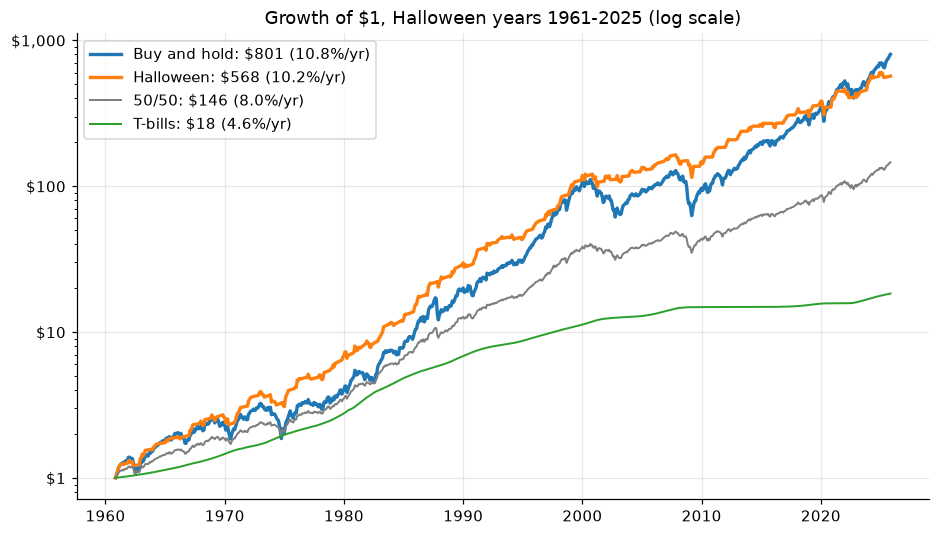

saved halloween_work/outputs_v7/02_average_six_month_returns.png


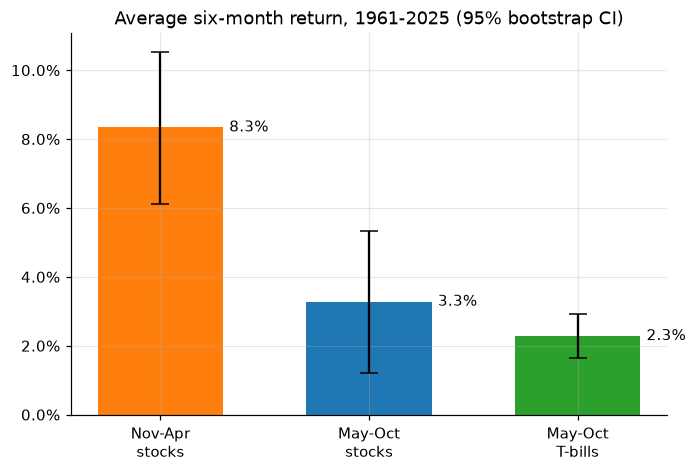

saved halloween_work/outputs_v7/03_summer_stocks_minus_tbills_by_year.png


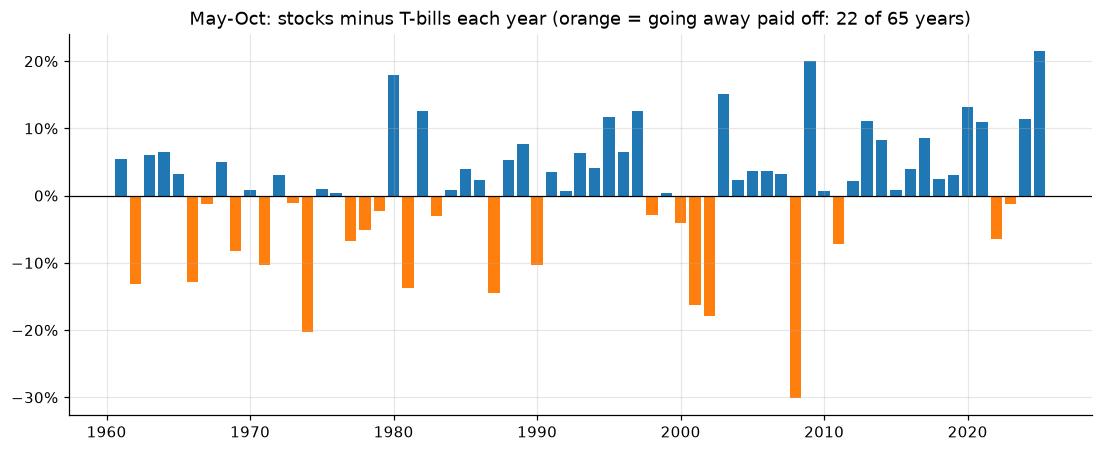

In [9]:
# --- Chart 1: growth of $1 ---
w = (1 + strat_c[["bh", "hw", "mix", "cash"]]).cumprod()
w.loc[strat_c.index[0] - 1] = 1.0
w = w.sort_index()
w.to_csv(OUTPUT_DIR / "growth_of_1.csv")

fig, ax = plt.subplots(figsize=(10, 5.5))
x = w.index.to_timestamp(how="end")
for col, colr, name in [("bh", C_BH, "Buy and hold"), ("hw", C_HW, "Halloween"),
                        ("mix", C_MIX, "50/50"), ("cash", C_CASH, "T-bills")]:
    ax.plot(x, w[col], color=colr, lw=2.2 if col in ("bh", "hw") else 1.3,
            label=f"{name}: ${w[col].iloc[-1]:,.0f} ({summary.loc[col, 'CAGR']:.1%}/yr)")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v:,.0f}" if v >= 1 else f"${v:.2f}"))
ax.set_title(f"Growth of $1, Halloween years {YEARS.min()}-{YEARS.max()} (log scale)")
ax.legend(loc="upper left")
savefig(fig, "01_growth_of_1")
plt.show()

# --- Chart 2: average six-month returns ---
parts = [("W", "Nov-Apr\nstocks", C_HW), ("S", "May-Oct\nstocks", C_BH), ("Cs", "May-Oct\nT-bills", C_CASH)]
fig, ax = plt.subplots(figsize=(7, 4.5))
for i, (col, lab, colr) in enumerate(parts):
    bb = boot(ann[col])
    ax.bar(i, bb["est"], color=colr, width=0.6)
    ax.errorbar(i, bb["est"], yerr=[[bb["est"] - bb["lo"]], [bb["hi"] - bb["est"]]], color="k", capsize=6)
    ax.text(i + 0.33, bb["est"], f"{bb['est']:.1%}", va="center")
ax.set_xticks(range(len(parts)))
ax.set_xticklabels([p[1] for p in parts])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title(f"Average six-month return, {YEARS.min()}-{YEARS.max()} (95% bootstrap CI)")
savefig(fig, "02_average_six_month_returns")
plt.show()

# --- Chart 3: each summer, stocks minus T-bills ---
v = ann["summer_premium"]
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(v.index, v, color=np.where(v < 0, C_HW, C_BH), width=0.8)
ax.axhline(0, color="k", lw=0.8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title(f"May-Oct: stocks minus T-bills each year (orange = going away paid off: "
             f"{int((v < 0).sum())} of {len(v)} years)")
savefig(fig, "03_summer_stocks_minus_tbills_by_year")
plt.show()

## 3. What you earn while you're out

Two common shortcuts are using **price-only** index performance and **zero return in cash**. Those omit dividends (which buy-and-hold can earn year-round and Halloween only in winter) and modeled cash interest (which Halloween earns while out). We show each specification on the **same set of complete Halloween years**. Historical dividend/cash data are themselves approximations; this does not make one synthetic series the literal realized portfolio.

,BH_CAGR %,HW_CAGR %,HW_minus_BH_CAGR %,mean_HW_minus_BH %,share_years_HW_wins %,BH_final_$1,HW_final_$1
variant,,,,,,,
"Price only, 0% while out",7.75,6.30,-1.45,-2.18,32.31,128.1176,53.1811
"Price only, T-bills while out",7.75,8.71,0.96,0.25,46.15,128.1176,228.3202
"Total return, 0% while out",10.83,7.80,-3.03,-3.78,26.15,800.7984,132.2733
"Total return, modeled T-bill carry (main)",10.83,10.25,-0.58,-1.31,33.85,800.7984,567.8838


saved halloween_work/outputs_v7/04_dividends_and_cash_variants.png


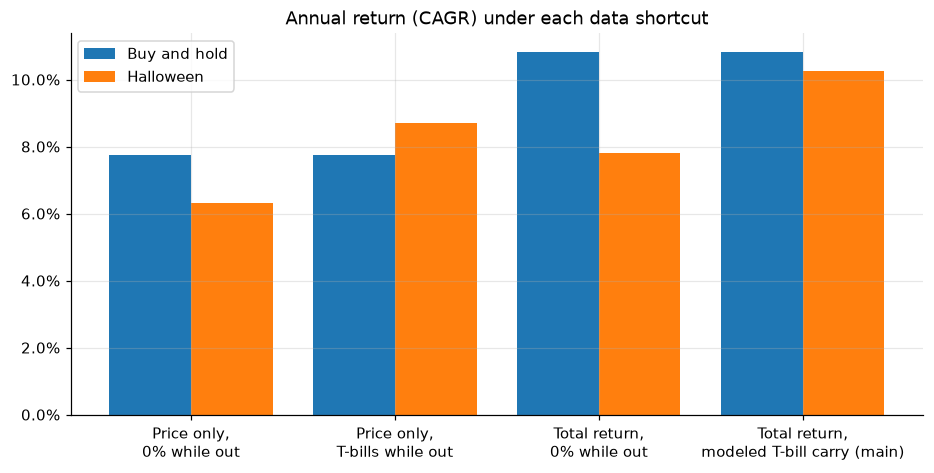

In [10]:
variants = [("Price only, 0% while out", "r_price", "r_zero"),
            ("Price only, T-bills while out", "r_price", "r_cash"),
            ("Total return, 0% while out", "r_stock", "r_zero"),
            ("Total return, modeled T-bill carry (main)", "r_stock", "r_cash")]
rows = []
for name, sc, cc in variants:
    a_ = annualize(strategy_returns(us, sc, cc), FIRST_YEAR)
    a_ = a_.reindex(YEARS)
    assert a_["BH"].notna().all(), f"Variant {name} missing some main sample years"
    rows.append({"variant": name, "BH_CAGR": geo(a_["BH"]), "HW_CAGR": geo(a_["HW"]),
                 "HW_minus_BH_CAGR": geo(a_["HW"]) - geo(a_["BH"]),
                 "mean_HW_minus_BH": a_["HW_minus_BH"].mean(),
                 "share_years_HW_wins": (a_["HW_minus_BH"] > 0).mean(),
                 "BH_final_$1": float(np.prod(1 + a_["BH"])), "HW_final_$1": float(np.prod(1 + a_["HW"]))})
var_tbl = pd.DataFrame(rows).set_index("variant")
var_tbl.to_csv(OUTPUT_DIR / "variants_dividends_cash.csv")
display(pct_table(var_tbl, ["BH_CAGR", "HW_CAGR", "HW_minus_BH_CAGR", "mean_HW_minus_BH", "share_years_HW_wins"]))

fig, ax = plt.subplots(figsize=(10, 4.5))
xs = np.arange(len(var_tbl))
ax.bar(xs - 0.2, var_tbl["BH_CAGR"], width=0.4, color=C_BH, label="Buy and hold")
ax.bar(xs + 0.2, var_tbl["HW_CAGR"], width=0.4, color=C_HW, label="Halloween")
ax.set_xticks(xs)
ax.set_xticklabels([t.replace(", ", ",\n") for t in var_tbl.index])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Annual return (CAGR) under each data shortcut")
ax.legend()
savefig(fig, "04_dividends_and_cash_variants")
plt.show()

## 4. Descriptive placebos — is November–April a particularly strong six-month selection?

- **Individual months:** mean stock return above cash for each month, with year-block confidence intervals and Benjamini–Hochberg adjustment across the 12 exploratory checks.
- **All 12 *consecutive* six-month trading windows:** stock exposure for that window and cash for its complement, compared with buy-and-hold. The gap between the two season-specific stock-minus-cash premiums is computed by **compounding each half**, consistent with H1/H2 statistics. Six unique gaps have complementary sign reversals; we adjust across those six distinct splits.
- **All 924 combinations of any six calendar months:** rank November–April by return versus buy-and-hold *and* difference in compounded equity premiums. All 924 are highly dependent, and these ranks/histograms are **NOT p-values**, evidence of luck with a specific probability, or a valid standalone data-mining correction.

The preselected November–April comparison is the main hypothesis; the alternative calendars are an exploratory descriptive challenge to claims that these exact dates are uniquely special.


,winter,mean_excess %,lo %,hi %,p_boot,share_positive %,p_fdr
month,,,,,,,
Nov,True,1.70,0.57,2.80,0.0038,70.77,0.0228
Dec,True,1.14,0.39,1.93,0.0034,70.77,0.0228
Jan,True,1.01,-0.19,2.19,0.0925,58.46,0.2220
Feb,True,-0.07,-1.03,0.89,0.8895,52.31,0.8895
Mar,True,0.84,0.10,1.60,0.0283,66.15,0.0849
Apr,True,1.21,0.30,2.16,0.0110,66.15,0.0440
May,False,0.22,-0.74,1.18,0.6575,61.54,0.8767
Jun,False,-0.08,-1.04,0.88,0.8713,52.31,0.8895
Jul,False,0.82,-0.21,1.81,0.1115,55.38,0.2230


saved halloween_work/outputs_v7/05_by_month.png


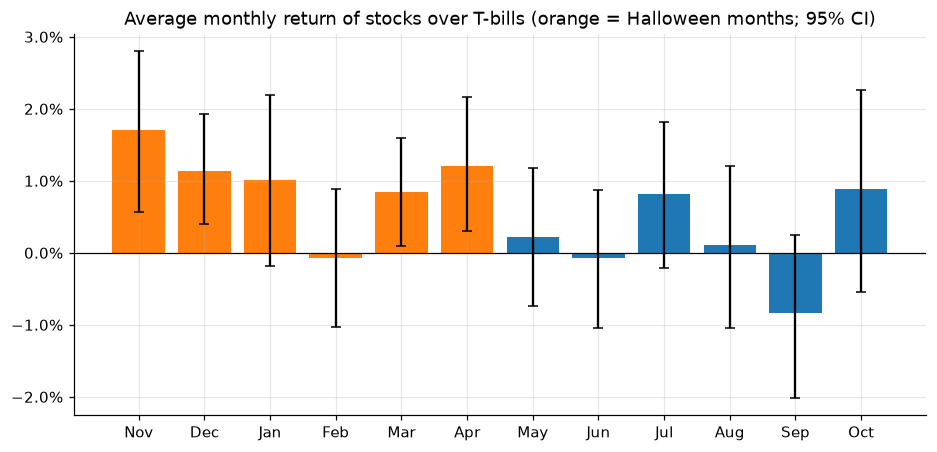

In [11]:
R_, C_ = year_matrix("stock"), year_matrix("cash")
E_ = R_ - C_                                   # monthly excess returns, (years x 12), Nov..Oct order
bh_year = np.prod(1 + R_, axis=1) - 1

month_rows = []
for j, m in enumerate(HY_ORDER):
    bb = boot(E_[:, j])
    month_rows.append({"month": MONTH_ABBR[m], "winter": m in WINTER, "mean_excess": bb["est"],
                       "lo": bb["lo"], "hi": bb["hi"], "p_boot": bb["p"],
                       "share_positive": float(np.mean(E_[:, j] > 0))})
by_month = pd.DataFrame(month_rows).set_index("month")
by_month["p_fdr"] = bh_adjust(by_month["p_boot"].to_numpy())
by_month.to_csv(OUTPUT_DIR / "placebo_by_month.csv")
display(pct_table(by_month, ["mean_excess", "lo", "hi", "share_positive"]))

fig, ax = plt.subplots(figsize=(10, 4.5))
xs = np.arange(12)
mu_ = by_month["mean_excess"].to_numpy()
ax.bar(xs, mu_, color=[C_HW if wv else C_BH for wv in by_month["winter"]])
ax.errorbar(xs, mu_, yerr=[mu_ - by_month["lo"].to_numpy(), by_month["hi"].to_numpy() - mu_],
            fmt="none", color="k", capsize=3)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(xs)
ax.set_xticklabels(by_month.index)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Average monthly return of stocks over T-bills (orange = Halloween months; 95% CI)")
savefig(fig, "05_by_month")
plt.show()

,rule_CAGR %,mean_adv_vs_BH %,adv_lo %,adv_hi %,p_adv,share_years_beat_BH %,mean_premium_gap %,gap_lo %,gap_hi %,p_gap,p_adv_fdr,p_gap_fdr
window,,,,,,,,,,,,
Nov–Apr,10.25,-1.31,-3.55,0.82,2.3588e-01,33.85,5.07,2.61,7.57,0.0002,0.2573,0.0012
Dec–May,8.67,-2.93,-5.69,-0.10,4.0996e-02,29.23,1.88,-1.58,5.55,0.2944,0.0492,0.5887
Jan–Jun,7.37,-4.05,-6.74,-1.21,4.1996e-03,27.69,-0.45,-4.23,3.73,0.8254,0.0084,0.8254
Feb–Jul,7.20,-4.46,-6.87,-1.93,4.9995e-04,26.15,-1.07,-4.25,2.18,0.5103,0.0018,0.7655
Mar–Aug,7.35,-4.19,-7.18,-0.97,1.0799e-02,36.92,-0.78,-4.45,3.27,0.6981,0.0144,0.8254
Apr–Sep,5.55,-5.76,-8.64,-2.71,5.9994e-04,30.77,-4.12,-8.37,0.26,0.0628,0.0018,0.1884
May–Oct,5.13,-6.48,-8.76,-4.26,9.9990e-05,27.69,-5.07,-7.57,-2.61,0.0002,0.0006,0.0012
Jun–Nov,6.66,-4.84,-7.28,-2.43,9.9990e-05,27.69,-1.88,-5.55,1.58,0.2944,0.0006,0.5887
Jul–Dec,7.96,-3.60,-6.43,-0.88,1.0299e-02,35.38,0.45,-3.73,4.23,0.8254,0.0144,0.8254


saved halloween_work/outputs_v7/06_placebo_12_windows.png


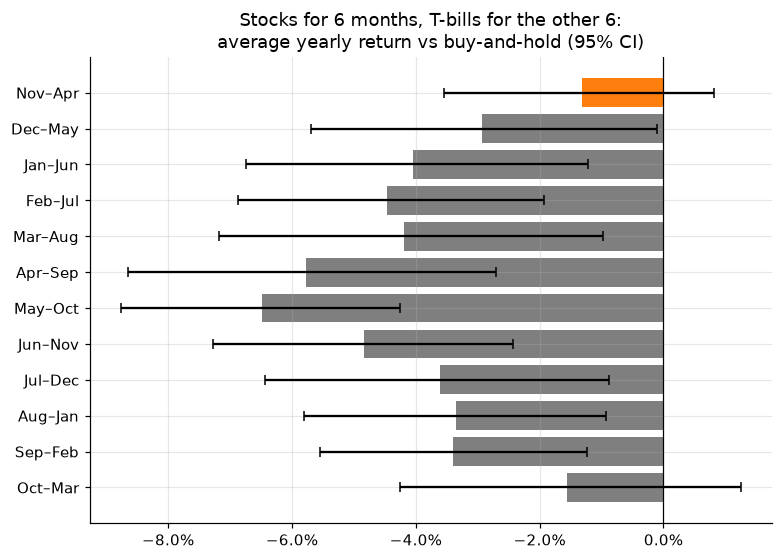

In [12]:
def window_stats(months):
    """Per-year: rule return, advantage vs buy-and-hold, and premium gap (in-window minus out-of-window)."""
    mask = np.isin(HY_ORDER, months)
    rule_year = np.prod(np.where(mask, 1 + R_, 1 + C_), axis=1) - 1
    adv = rule_year - bh_year
    premium_in = (np.prod(1 + R_[:, mask], axis=1) - 1) - (np.prod(1 + C_[:, mask], axis=1) - 1)
    premium_out = (np.prod(1 + R_[:, ~mask], axis=1) - 1) - (np.prod(1 + C_[:, ~mask], axis=1) - 1)
    gap = premium_in - premium_out
    return rule_year, adv, gap


# Internal consistency: the Nov-Apr window must reproduce the main table exactly
assert np.allclose(window_stats(list(WINTER))[1], ann["HW_minus_BH"].to_numpy(), atol=1e-12)
assert np.allclose(window_stats(list(WINTER))[2], ann["premium_gap"].to_numpy(), atol=1e-12)

win_rows = []
for sm in HY_ORDER:
    rule_year, adv, gap = window_stats(window_months(sm))
    ba, bg = boot(adv), boot(gap)
    win_rows.append({"window": window_label(sm), "rule_CAGR": geo(rule_year),
                     "mean_adv_vs_BH": ba["est"], "adv_lo": ba["lo"], "adv_hi": ba["hi"], "p_adv": ba["p"],
                     "share_years_beat_BH": float(np.mean(adv > 0)),
                     "mean_premium_gap": bg["est"], "gap_lo": bg["lo"], "gap_hi": bg["hi"], "p_gap": bg["p"]})
windows = pd.DataFrame(win_rows).set_index("window")
windows["p_adv_fdr"] = bh_adjust(windows["p_adv"].to_numpy())
q6 = bh_adjust(windows["p_gap"].to_numpy()[:6])     # rows 6..11 are the complements of rows 0..5
windows["p_gap_fdr"] = np.concatenate([q6, q6])
windows.to_csv(OUTPUT_DIR / "placebo_12_windows.csv")
display(pct_table(windows, ["rule_CAGR", "mean_adv_vs_BH", "adv_lo", "adv_hi", "share_years_beat_BH",
                            "mean_premium_gap", "gap_lo", "gap_hi"]))

fig, ax = plt.subplots(figsize=(8, 5.5))
ys = np.arange(len(windows))[::-1]
mv = windows["mean_adv_vs_BH"].to_numpy()
ax.barh(ys, mv, color=[C_HW if lab == window_label(11) else C_MIX for lab in windows.index])
ax.errorbar(mv, ys, xerr=[mv - windows["adv_lo"].to_numpy(), windows["adv_hi"].to_numpy() - mv],
            fmt="none", color="k", capsize=3)
ax.set_yticks(ys)
ax.set_yticklabels(windows.index)
ax.axvline(0, color="k", lw=0.8)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Stocks for 6 months, T-bills for the other 6:\naverage yearly return vs buy-and-hold (95% CI)")
savefig(fig, "06_placebo_12_windows")
plt.show()

Descriptive ranks only, NOT randomization p-values; these 924 calendars are highly dependent.
Nov-Apr ranks #14 of 924 six-month calendars by premium gap (top 1.5%).
Nov-Apr ranks #21 of 924 by average advantage over buy-and-hold; 0 of 924 calendars beat buy-and-hold on average.


,months,mean_premium_gap %,mean_adv_vs_BH %
30,"Nov,Dec,Jan,Mar,Apr,Jul",6.77,-0.44
33,"Nov,Dec,Jan,Mar,Apr,Oct",6.75,-0.36
60,"Nov,Dec,Jan,Apr,Jul,Oct",6.66,-0.47
151,"Nov,Dec,Mar,Apr,Jul,Oct",6.13,-0.67
277,"Nov,Jan,Mar,Apr,Jul,Oct",6.04,-0.78
45,"Nov,Dec,Jan,Mar,Jul,Oct",5.84,-0.87
28,"Nov,Dec,Jan,Mar,Apr,May",5.63,-1.02
50,"Nov,Dec,Jan,Apr,May,Jul",5.56,-0.99
53,"Nov,Dec,Jan,Apr,May,Oct",5.52,-0.97
31,"Nov,Dec,Jan,Mar,Apr,Aug",5.35,-1.08


saved halloween_work/outputs_v7/07_placebo_924_calendars.png


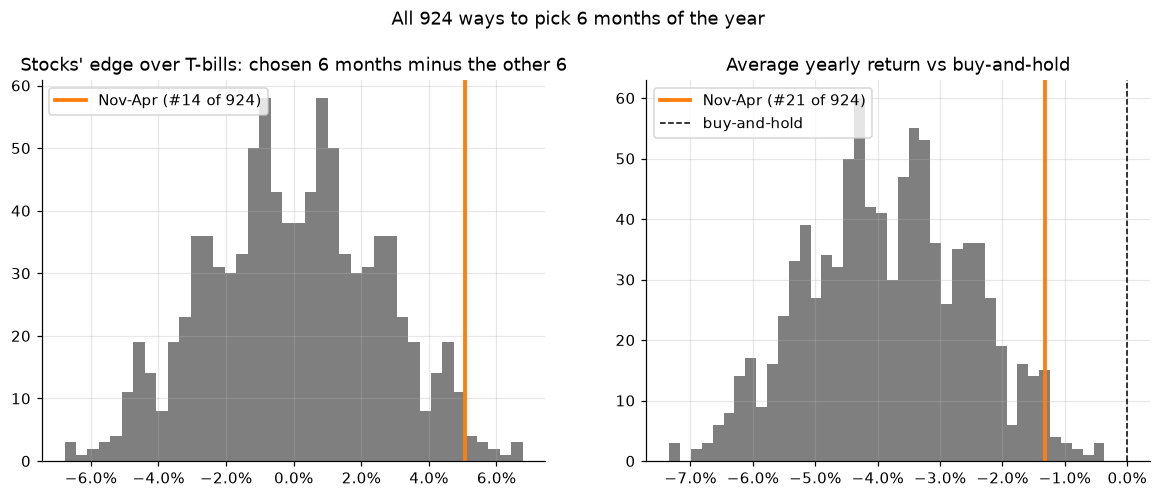

In [13]:
combos = np.array(list(itertools.combinations(range(12), 6)))      # positions in HY_ORDER
masks = np.zeros((len(combos), 12), dtype=bool)
masks[np.arange(len(combos))[:, None], combos] = True

# Per-year COMPOUNDED six-month risk premiums, consistent with window_stats() and ann.
# Shape: (924 selections, number of complete Halloween years).
stock_in = np.prod(np.where(masks[:, None, :], 1 + R_[None, :, :], 1.0), axis=2) - 1
cash_in = np.prod(np.where(masks[:, None, :], 1 + C_[None, :, :], 1.0), axis=2) - 1
stock_out = np.prod(np.where(~masks[:, None, :], 1 + R_[None, :, :], 1.0), axis=2) - 1
cash_out = np.prod(np.where(~masks[:, None, :], 1 + C_[None, :, :], 1.0), axis=2) - 1
gap_all = ((stock_in - cash_in) - (stock_out - cash_out)).mean(axis=1)
rule_all = np.prod(np.where(masks[:, None, :], 1 + R_[None], 1 + C_[None]), axis=2) - 1   # (924, years)
adv_all = (rule_all - bh_year[None, :]).mean(axis=1)

hw_pos = int(np.flatnonzero((masks == np.isin(HY_ORDER, WINTER)).all(axis=1))[0])
assert np.isclose(gap_all[hw_pos], ann["premium_gap"].mean(), atol=1e-12)
assert np.isclose(adv_all[hw_pos], ann["HW_minus_BH"].mean(), atol=1e-12)
# Each selection has an opposite complement; their premium gaps must sum to zero.
comp_lookup = {tuple(c): k for k, c in enumerate(combos)}
for i, c in enumerate(combos):
    j = comp_lookup[tuple(k for k in range(12) if k not in c)]
    assert np.isclose(gap_all[i] + gap_all[j], 0.0, atol=1e-12)
rank_gap = int((gap_all > gap_all[hw_pos]).sum()) + 1
rank_adv = int((adv_all > adv_all[hw_pos]).sum()) + 1
n_beat_bh = int((adv_all > 0).sum())
print("Descriptive ranks only, NOT randomization p-values; these 924 calendars are highly dependent.")
print(f"Nov-Apr ranks #{rank_gap} of {len(combos)} six-month calendars by premium gap "
      f"(top {rank_gap / len(combos):.1%}).")
print(f"Nov-Apr ranks #{rank_adv} of {len(combos)} by average advantage over buy-and-hold; "
      f"{n_beat_bh} of {len(combos)} calendars beat buy-and-hold on average.")

subsets = pd.DataFrame({
    "months": [",".join(MONTH_ABBR[HY_ORDER[j]] for j in c) for c in combos],
    "mean_premium_gap": gap_all, "mean_adv_vs_BH": adv_all,
}).sort_values("mean_premium_gap", ascending=False)
subsets.to_csv(OUTPUT_DIR / "placebo_924_calendars.csv", index=False)
display(pct_table(subsets.head(10), ["mean_premium_gap", "mean_adv_vs_BH"]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(gap_all, bins=40, color=C_MIX)
axes[0].axvline(gap_all[hw_pos], color=C_HW, lw=2.5, label=f"Nov-Apr (#{rank_gap} of {len(combos)})")
axes[0].set_title("Stocks' edge over T-bills: chosen 6 months minus the other 6")
axes[1].hist(adv_all, bins=40, color=C_MIX)
axes[1].axvline(adv_all[hw_pos], color=C_HW, lw=2.5, label=f"Nov-Apr (#{rank_adv} of {len(combos)})")
axes[1].axvline(0, color="k", lw=1, ls="--", label="buy-and-hold")
axes[1].set_title("Average yearly return vs buy-and-hold")
for a in axes:
    a.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    a.legend()
fig.suptitle(f"All {len(combos)} ways to pick 6 months of the year", y=1.02)
savefig(fig, "07_placebo_924_calendars")
plt.show()

## 4b. The original saying: "come on back on St Leger's Day"

The full British saying is *"Sell in May and go away, and come on back on St Leger's Day."* The St Leger Stakes is a horse race run in mid-September, so the original rule came back to stocks about six weeks **before** Halloween. Monthly data bracket mid-September:

- **Back at the end of August:** T-bills May–Aug, stocks Sep–Apr (8 months in stocks).
- **Back at the end of September:** T-bills May–Sep, stocks Oct–Apr (7 months in stocks).
- **Halloween:** T-bills May–Oct, stocks Nov–Apr (6 months in stocks).

Same years, same cash proxy, same year-block bootstrap. This is a supporting comparison for the story, not a new primary test. September's and October's rows in the month-by-month table above explain most of whatever difference appears.

,months_in_stocks,CAGR %,final_$1,mean_vs_BH %,lo %,hi %,p_boot,share_years_beat_BH %,mean_vs_Halloween %,vs_HW_lo %,vs_HW_hi %,vs_HW_p
rule,,,,,,,,,,,,
Halloween (back at end of Oct),6,10.25,567.8838,-1.31,-3.55,0.82,0.2359,33.85,NaN,NaN,NaN,NaN
"St Leger, back at end of Aug",8,10.01,492.9206,-1.22,-3.42,0.94,0.2667,46.15,0.09,-1.68,1.76,0.9227
"St Leger, back at end of Sep",7,11.04,901.7229,-0.35,-2.74,2.15,0.7774,35.38,0.96,-0.61,2.43,0.2145


Sep: stocks minus T-bills -0.83% per month on average [-2.01%, +0.25%], positive in 45% of years
Oct: stocks minus T-bills +0.89% per month on average [-0.54%, +2.26%], positive in 62% of years
saved halloween_work/outputs_v7/06b_st_leger_vs_halloween.png


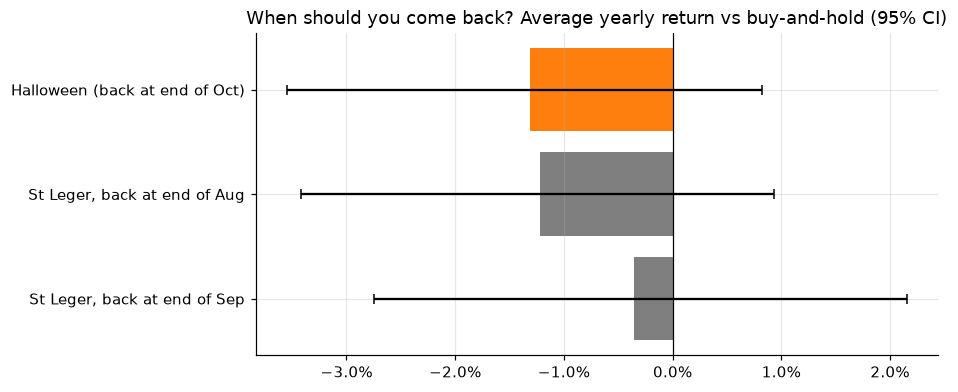

In [14]:
ST_LEGER_RULES = {
    "Halloween (back at end of Oct)": list(WINTER),
    "St Leger, back at end of Aug": [9, 10, 11, 12, 1, 2, 3, 4],
    "St Leger, back at end of Sep": [10, 11, 12, 1, 2, 3, 4],
}
leger_rows, leger_years = [], {}
for name, months_in in ST_LEGER_RULES.items():
    mask = np.isin(HY_ORDER, months_in)
    rule_year = np.prod(np.where(mask, 1 + R_, 1 + C_), axis=1) - 1
    leger_years[name] = rule_year
    adv = boot(rule_year - bh_year)
    leger_rows.append({"rule": name, "months_in_stocks": int(mask.sum()), "CAGR": geo(rule_year),
                       "final_$1": float(np.prod(1 + rule_year)),
                       "mean_vs_BH": adv["est"], "lo": adv["lo"], "hi": adv["hi"], "p_boot": adv["p"],
                       "share_years_beat_BH": float(np.mean(rule_year > bh_year))})
leger = pd.DataFrame(leger_rows).set_index("rule")

hw_key = "Halloween (back at end of Oct)"
assert np.allclose(leger_years[hw_key], ann["HW"].to_numpy(), atol=1e-12)
for name in ST_LEGER_RULES:
    if name == hw_key:
        continue
    dd_ = boot(leger_years[name] - leger_years[hw_key])
    leger.loc[name, "mean_vs_Halloween"] = dd_["est"]
    leger.loc[name, "vs_HW_lo"] = dd_["lo"]
    leger.loc[name, "vs_HW_hi"] = dd_["hi"]
    leger.loc[name, "vs_HW_p"] = dd_["p"]
leger.to_csv(OUTPUT_DIR / "st_leger_vs_halloween.csv")
display(pct_table(leger, ["CAGR", "mean_vs_BH", "lo", "hi", "share_years_beat_BH",
                          "mean_vs_Halloween", "vs_HW_lo", "vs_HW_hi"]))
for m_ in ["Sep", "Oct"]:
    r_ = by_month.loc[m_]
    print(f"{m_}: stocks minus T-bills {r_['mean_excess']:+.2%} per month on average "
          f"[{r_['lo']:+.2%}, {r_['hi']:+.2%}], positive in {r_['share_positive']:.0%} of years")

fig, ax = plt.subplots(figsize=(8, 3.8))
ys = np.arange(len(leger))[::-1]
mv = leger["mean_vs_BH"].to_numpy()
err = [np.clip(mv - leger["lo"].to_numpy(), 0, None), np.clip(leger["hi"].to_numpy() - mv, 0, None)]
ax.barh(ys, mv, color=[C_HW if n == hw_key else C_MIX for n in leger.index])
ax.errorbar(mv, ys, xerr=err, fmt="none", color="k", capsize=3)
ax.set_yticks(ys)
ax.set_yticklabels(leger.index)
ax.axvline(0, color="k", lw=0.8)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("When should you come back? Average yearly return vs buy-and-hold (95% CI)")
savefig(fig, "06b_st_leger_vs_halloween")
plt.show()

## 5. How has the pattern performed since the research circulated?

**Important dates:** Bouman & Jacobsen's paper was circulated as a working paper in the late 1990s (a 1997 manuscript and April 1998 SSRN posting); it appeared in the *American Economic Review* in **December 2002**. The 2002 journal date **is not the first public discovery** of the seasonal idea, which is older still.

We report **two transparent splits**: Halloween years through 1998 versus 1999 onward (after the 1998 working-paper posting), and years through 2002 versus 2003 onward (after journal publication). These are **post-document samples, not pristine out-of-sample prospective tests**: the original seasonal saying predates both papers, and data series/method choices are retrospective.

Also show **the overlapping 2003+ and SPY-era subperiods** in robustness, plus decades and rolling windows. Shorter samples are noisier, but they are more relevant for an investor today. **Section 5b** puts the two cutoffs side by side, shows the 1999–2002 years that separate them, and repeats the beta-matched comparison inside each period.

Sources: https://papers.ssrn.com/sol3/papers.cfm?abstract_id=76248 and https://pubs.aeaweb.org/doi/10.1257/000282802762024683


After 1998 working-paper posting: 1961-1998 (38 years) versus 1999-2025 (27 years)
After December 2002 journal publication: 1961-2002 (42 years) versus 2003-2025 (23 years)


cutoff period_pre period_post        endpoint  mean_pre %  lo_pre %  hi_pre %  \
split                                   metric                                                                                                                          
After 1998 working-paper posting        PRIMARY H1: winter minus summer stock return      1998  1961-1998   1999-2025       W_minus_S        6.38      2.98      9.66   
                                        PRIMARY H2: Halloween minus buy-and-hold          1998  1961-1998   1999-2025     HW_minus_BH       -0.26     -2.78      2.02   
                                        Supports H2: May-Oct stocks minus modeled cash    1998  1961-1998   1999-2025  summer_premium        0.05     -2.15      2.41   
                                        Halloween minus monthly 50/50                     1998  1961-1998   1999-2025    HW_minus_MIX        3.20      1.44      4.91   
After December 2002 journal publication PRIMARY H1: winter minus summer stock return      2002  1961-2002   2003-2025       W_minus_S        6.96      3.61     10.03   
                                        PRIMARY H2: Halloween minus buy-and-hold          2002  1961-2002   2003-2025     HW_minus_BH        0.64     -2.04      3.15   
                                        Supports H2: May-Oct stocks minus modeled cash    2002  1961-2002   2003-2025  summer_premium       -0.86     -3.38      1.70   
                                        Halloween minus monthly 50/50                     2002  1961-2002   2003-2025    HW_minus_MIX        3.48      1.73      5.08   

                                                                                        share_pos_pre %  mean_post %  lo_post %  hi_post %  share_pos_post %  change %  \
split                                   metric                                                                                                                           
After 1998 working-paper posting        PRIMARY H1: winter minus summer stock return              71.05         3.20       0.34       6.60             74.07     -3.18   
                                        PRIMARY H2: Halloween minus buy-and-hold                  39.47        -2.79      -6.29       1.15             25.93     -2.54   
                                        Supports H2: May-Oct stocks minus modeled cash            60.53         2.33      -1.61       5.76             74.07      2.29   
                                        Halloween minus monthly 50/50                             68.42         1.53       0.10       3.25             70.37     -1.67   
After December 2002 journal publication PRIMARY H1: winter minus summer stock return              73.81         1.60      -2.70       5.97             69.57     -5.36   
                                        PRIMARY H2: Halloween minus buy-and-hold                  42.86        -4.87      -8.54      -1.15             17.39     -5.51   
                                        Supports H2: May-Oct stocks minus modeled cash            57.14         4.39       0.67       8.00             82.61      5.25   
                                        Halloween minus monthly 50/50                             71.43         0.73      -1.41       2.94             65.22     -2.75   

                                                                                        change_lo %  change_hi %  p_change  se_post %  mde80_post %  \
split                                   metric                                                                                                        
After 1998 working-paper posting        PRIMARY H1: winter minus summer stock return          -7.58         1.56    0.1723       1.60          4.48   
                                        PRIMARY H2: Halloween minus buy-and-hold              -6.68         2.06    0.2579       1.89          5.31   
                                        Supports H2: May-Oct stocks minus modeled cash      


What the post-period samples can and cannot say (MDE80 = smallest true effect that sample would detect 80% of the time):
  [After 1998 working-paper posting] PRIMARY H1: winter minus summer stock return: post mean +3.2% vs earlier +6.4%, MDE80 4.5% -> SIGNIFICANT: Nov-Apr stocks beat May-Oct stocks, in line with the earlier +6.4%
  [After 1998 working-paper posting] PRIMARY H2: Halloween minus buy-and-hold: post mean -2.8% vs earlier -0.3%, MDE80 5.3% -> TOO SHORT TO TELL: on average Halloween did worse than buy-and-hold, but the CI includes both zero and the earlier -0.3%
  [After 1998 working-paper posting] Supports H2: May-Oct stocks minus modeled cash: post mean +2.3% vs earlier +0.0%, MDE80 5.3% -> TOO SHORT TO TELL: on average May-Oct stocks beat T-bills (going away cost money), but the CI includes both zero and the earlier +0.0%
  [After 1998 working-paper posting] Halloween minus monthly 50/50: post mean +1.5% vs earlier +3.2%, MDE80 2.3% -> SIGNIFICANT: Halloween beat the 50/

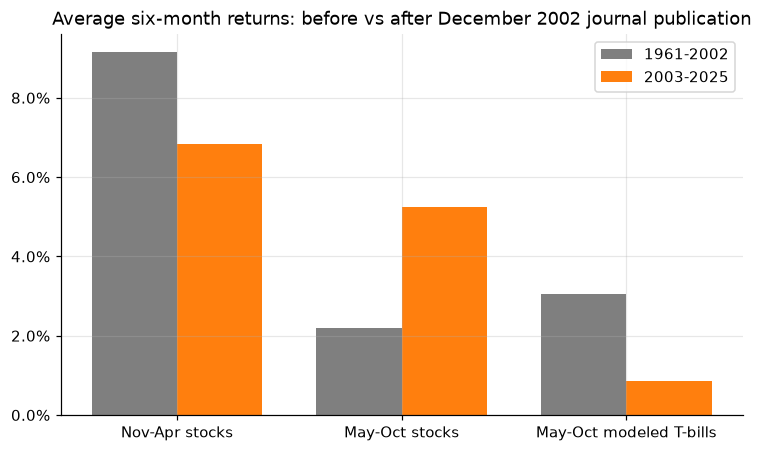

In [15]:
# Both prior-art cutoffs, with year-block resampling performed separately in each side.
# What a positive / negative value means for each metric, in plain words.
VERDICT_WORDS = {
    "summer_premium": ("May-Oct stocks beat T-bills (going away cost money)",
                       "May-Oct stocks trailed T-bills (going away paid)"),
    "W_minus_S": ("Nov-Apr stocks beat May-Oct stocks", "May-Oct stocks beat Nov-Apr stocks"),
    "HW_minus_BH": ("Halloween beat buy-and-hold", "Halloween did worse than buy-and-hold"),
    "HW_minus_MIX": ("Halloween beat the 50/50 mix", "Halloween did worse than the 50/50 mix"),
}


def post_verdict(col, pre_est, post_boot):
    """Plain-language reading of the post-period 95% CI: direction, significance, and the earlier estimate."""
    est, lo, hi = post_boot["est"], post_boot["lo"], post_boot["hi"]
    pos, neg = VERDICT_WORDS[col]
    direction = pos if est > 0 else neg
    has_zero, has_pre = lo <= 0 <= hi, lo <= pre_est <= hi
    if has_zero and has_pre:
        return (f"TOO SHORT TO TELL: on average {direction}, but the CI includes both zero "
                f"and the earlier {pre_est:+.1%}")
    if has_zero:
        return (f"NOT SIGNIFICANT: on average {direction}, but the CI includes zero "
                f"(and excludes the earlier {pre_est:+.1%})")
    if has_pre:
        return f"SIGNIFICANT: {direction}, in line with the earlier {pre_est:+.1%}"
    flipped = " (the sign reversed)" if np.sign(est) != np.sign(pre_est) else ""
    return f"SIGNIFICANT: {direction}, and different from the earlier {pre_est:+.1%}{flipped}"


# Guards: a significantly negative Halloween-minus-buy-and-hold must read as "worse".
assert post_verdict("HW_minus_BH", 0.007, dict(est=-0.05, lo=-0.08, hi=-0.02)).startswith(
    "SIGNIFICANT: Halloween did worse than buy-and-hold")
assert post_verdict("W_minus_S", 0.06, dict(est=0.02, lo=-0.01, hi=0.07)).startswith("TOO SHORT TO TELL")


def calculate_split(split_name, cutoff):
    pre = ann[ann.index <= cutoff]
    post = ann[ann.index > cutoff]
    if len(pre) < 3 or len(post) < 3:
        raise ValueError(f"Not enough complete Halloween years either side of {cutoff}")
    lab_pre = f"{pre.index.min()}-{pre.index.max()}"
    lab_post = f"{post.index.min()}-{post.index.max()}"
    rows = []
    for col, label in [("W_minus_S", "PRIMARY H1: winter minus summer stock return"),
                       ("HW_minus_BH", "PRIMARY H2: Halloween minus buy-and-hold"),
                       ("summer_premium", "Supports H2: May-Oct stocks minus modeled cash"),
                       ("HW_minus_MIX", "Halloween minus monthly 50/50")]:
        a = boot(pre[col], return_draws=True, seed=SEED)
        b = boot(post[col], return_draws=True, seed=SEED + 1)
        diffs = b["draws"] - a["draws"]
        est = b["est"] - a["est"]
        rows.append({"split": split_name, "cutoff": cutoff, "period_pre": lab_pre, "period_post": lab_post,
                     "metric": label, "endpoint": col,
                     "mean_pre": a["est"], "lo_pre": a["lo"], "hi_pre": a["hi"],
                     "share_pos_pre": (pre[col] > 0).mean(),
                     "mean_post": b["est"], "lo_post": b["lo"], "hi_post": b["hi"],
                     "share_pos_post": (post[col] > 0).mean(),
                     "change": est, "change_lo": np.percentile(diffs, 2.5),
                     "change_hi": np.percentile(diffs, 97.5),
                     "p_change": (np.sum(np.abs(diffs - est) >= abs(est)) + 1) / (len(diffs) + 1),
                     # Smallest true post-period mean detectable with 80% power at two-sided 5%: (1.96 + 0.84) x SE
                     "se_post": float(np.std(b["draws"], ddof=1)),
                     "mde80_post": 2.80 * float(np.std(b["draws"], ddof=1)),
                     "verdict_post": post_verdict(col, a["est"], b)})
    return rows, pre, post

all_split_rows = []
for _label, _cutoff in [("After 1998 working-paper posting", WORKING_PAPER_YEAR),
                        ("After December 2002 journal publication", PUBLICATION_YEAR)]:
    try:
        _rows, _pre, _post = calculate_split(_label, _cutoff)
    except ValueError as exc:
        print(f"SKIP {_label}: {exc}; available Yahoo cash history begins {YEARS.min()}.")
        continue
    print(f"{_label}: {_pre.index.min()}-{_pre.index.max()} ({len(_pre)} years) "
          f"versus {_post.index.min()}-{_post.index.max()} ({len(_post)} years)")
    all_split_rows.extend(_rows)

prepost = (pd.DataFrame(all_split_rows).set_index(["split", "metric"])
           if all_split_rows else pd.DataFrame(columns=["split", "metric"]).set_index(["split", "metric"]))
prepost.to_csv(OUTPUT_DIR / "pre_post_working_paper_and_journal.csv")
if not prepost.empty:
    display(pct_table(prepost, ["mean_pre", "lo_pre", "hi_pre", "share_pos_pre", "mean_post", "lo_post", "hi_post",
                                "share_pos_post", "change", "change_lo", "change_hi", "se_post", "mde80_post"]))
print("\nWhat the post-period samples can and cannot say "
      "(MDE80 = smallest true effect that sample would detect 80% of the time):")
for (split_, metric_), r_ in prepost.iterrows():
    print(f"  [{split_}] {metric_}: post mean {r_['mean_post']:+.1%} vs earlier {r_['mean_pre']:+.1%}, "
          f"MDE80 {r_['mde80_post']:.1%} -> {r_['verdict_post']}")

# Journal-date panel is meaningful only if Yahoo has observations on both sides.
pre = ann[ann.index <= PUBLICATION_YEAR]
post = ann[ann.index > PUBLICATION_YEAR]
if len(pre) >= 3 and len(post) >= 3:
    LAB_PRE = f"{pre.index.min()}-{pre.index.max()}"
    LAB_POST = f"{post.index.min()}-{post.index.max()}"
    fig, ax = plt.subplots(figsize=(8, 4.5))
    xs = np.arange(3)
    for k_, (frame, lab, colr) in enumerate([(pre, LAB_PRE, C_MIX), (post, LAB_POST, C_HW)]):
        vals = [frame["W"].mean(), frame["S"].mean(), frame["Cs"].mean()]
        ax.bar(xs + (k_ - 0.5) * 0.38, vals, width=0.38, color=colr, label=lab)
    ax.set_xticks(xs)
    ax.set_xticklabels(["Nov-Apr stocks", "May-Oct stocks", "May-Oct modeled T-bills"])
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set_title("Average six-month returns: before vs after December 2002 journal publication")
    ax.legend()
    savefig(fig, "08_pre_post_journal_publication")
    plt.show()
else:
    print("Pre/post 2002 plot skipped: too few complete pre-publication Halloween years with ^IRX.")


Note: the first and last decades are partial; see the 'years' column.


,years,mean_W %,mean_S %,mean_Cs %,BH_CAGR %,HW_CAGR %,MIX_CAGR %,share_years_HW_wins %
1960s,9,9.87,1.05,2.08,10.25,11.70,7.35,44.44
1970s,10,6.50,-0.75,3.30,4.54,9.05,5.87,60.00
1980s,10,11.35,6.54,4.60,17.72,16.05,13.96,30.00
1990s,10,11.98,5.76,2.51,17.82,14.40,11.56,20.00
2000s,10,1.15,-0.64,1.40,-0.95,2.26,1.29,40.00
2010s,10,9.93,3.66,0.28,13.70,10.12,7.13,10.00
2020s,6,7.32,9.63,1.42,16.28,7.96,9.72,33.33


saved halloween_work/outputs_v7/09_rolling_window.png


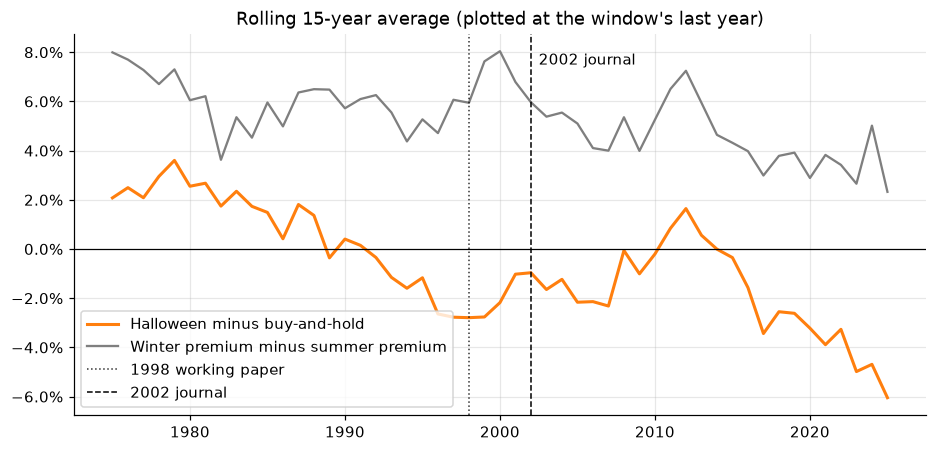

In [16]:
dec = ann.groupby((ann.index // 10) * 10)
decades = pd.DataFrame({
    "years": dec.size(),
    "mean_W": dec["W"].mean(), "mean_S": dec["S"].mean(), "mean_Cs": dec["Cs"].mean(),
    "BH_CAGR": dec["BH"].apply(geo), "HW_CAGR": dec["HW"].apply(geo), "MIX_CAGR": dec["MIX"].apply(geo),
    "share_years_HW_wins": dec["HW_minus_BH"].apply(lambda s: (s > 0).mean()),
})
decades.index = [f"{d}s" for d in decades.index]
decades.to_csv(OUTPUT_DIR / "by_decade.csv")
print("Note: the first and last decades are partial; see the 'years' column.")
display(pct_table(decades, ["mean_W", "mean_S", "mean_Cs", "BH_CAGR", "HW_CAGR", "MIX_CAGR", "share_years_HW_wins"]))

roll = pd.DataFrame({
    "Halloween minus buy-and-hold": ann["HW_minus_BH"].rolling(ROLL_YEARS).mean(),
    "Winter premium minus summer premium": ann["premium_gap"].rolling(ROLL_YEARS).mean(),
}).dropna()
roll.to_csv(OUTPUT_DIR / f"rolling_{ROLL_YEARS}y.csv")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(roll.index, roll.iloc[:, 0], color=C_HW, lw=2, label=roll.columns[0])
ax.plot(roll.index, roll.iloc[:, 1], color=C_MIX, lw=1.5, label=roll.columns[1])
ax.axhline(0, color="k", lw=0.8)
ax.axvline(WORKING_PAPER_YEAR, color="k", ls=":", lw=1, alpha=0.8, label="1998 working paper")
ax.axvline(PUBLICATION_YEAR, color="k", ls="--", lw=1, label="2002 journal")
ax.text(PUBLICATION_YEAR + 0.5, 0.95, "2002 journal", transform=ax.get_xaxis_transform(), va="top")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title(f"Rolling {ROLL_YEARS}-year average (plotted at the window's last year)")
ax.legend()
savefig(fig, "09_rolling_window")
plt.show()

## 5b. Cutoff sensitivity and the post-publication risk check

**Which cutoff?** Section 5 splits the sample twice: after the 1998 working paper (1999+) and after the December 2002 journal article (2003+). The Halloween years 1999–2002 include the 2000–2002 bear market, when being out of stocks for the summer helped. Whether those years count as "after" can decide whether the post-period result is significant. The first cell puts both answers side by side and shows those years. If the two cutoffs disagree, say so on camera rather than picking one.

**Is the lower risk still a good deal?** Section 2's beta-matched alpha uses the full sample. Halloween holds stocks only half the year, so lower risk and lower return are expected; the question is whether it beats a passive stock/T-bill mix with the **same beta**. The second cell re-estimates that comparison inside each period (beta estimated within the period), with:

- the monthly Jensen's-alpha regression (Newey–West p-value), as in section 2;
- Halloween minus the same-beta mix, compounded by Halloween year, with the same year-block bootstrap CI used everywhere else;
- the Sharpe difference with its bootstrap CI, and maximum drawdowns.

If the 2003+ same-beta CI includes zero, the accurate line is "lower risk, but after 2002 no better than simply holding less stock."

**Growth of $1 since 2003 (and since 1999):** the third cell draws the chart for the post-publication finding.

In [17]:
# --- Cutoff sensitivity: the same metrics after 1998 and after 2002, side by side ---
if prepost.empty:
    print("Cutoff comparison skipped: no split could be computed.")
else:
    pp_split = prepost.reset_index()
    pp_split["post_mean_CI"] = [f"{m:+.1%} [{l:+.1%}, {h:+.1%}]"
                                for m, l, h in zip(pp_split["mean_post"], pp_split["lo_post"], pp_split["hi_post"])]
    metric_order = pp_split["metric"].drop_duplicates()
    cutoff_tbl = pp_split.pivot(index="metric", columns="period_post", values="post_mean_CI").reindex(metric_order)
    verdict_tbl = pp_split.pivot(index="metric", columns="period_post", values="verdict_post").reindex(metric_order)
    pd.concat({"post mean [95% CI]": cutoff_tbl, "verdict": verdict_tbl}, axis=1).to_csv(
        OUTPUT_DIR / "cutoff_sensitivity.csv")
    print("Post-period mean per year [95% bootstrap CI]; columns = where the 'after' period starts")
    with pd.option_context("display.max_colwidth", 140):
        display(cutoff_tbl)
        display(verdict_tbl)

    hb_ = pp_split[pp_split["endpoint"] == "HW_minus_BH"]
    sig_ = {r["period_post"]: not (r["lo_post"] <= 0 <= r["hi_post"]) for _, r in hb_.iterrows()}
    if len(set(sig_.values())) > 1:
        print("NOTE: the two cutoffs disagree on whether Halloween's post-period result vs buy-and-hold "
              "is significant. Report both, and explain the years below.")

bridge_years = [y for y in range(WORKING_PAPER_YEAR + 1, PUBLICATION_YEAR + 1) if y in ann.index]
if bridge_years:
    bridge = ann.loc[bridge_years, ["W", "S", "Cs", "BH", "HW", "HW_minus_BH"]]
    bridge.to_csv(OUTPUT_DIR / "cutoff_bridge_years.csv")
    print(f"\nHalloween years {bridge_years[0]}-{bridge_years[-1]}: 'after' for the 1998 cutoff, "
          "'before' for the 2002 cutoff")
    display(pct_table(bridge, list(bridge.columns)))
    print(f"Halloween minus buy-and-hold in these years: mean {bridge['HW_minus_BH'].mean():+.1%}; "
          f"Halloween ahead in {int((bridge['HW_minus_BH'] > 0).sum())} of {len(bridge)}.")

Post-period mean per year [95% bootstrap CI]; columns = where the 'after' period starts


period_post,1999-2025,2003-2025
metric,,
PRIMARY H1: winter minus summer stock return,"+3.2% [+0.3%, +6.6%]","+1.6% [-2.7%, +6.0%]"
PRIMARY H2: Halloween minus buy-and-hold,"-2.8% [-6.3%, +1.2%]","-4.9% [-8.5%, -1.1%]"
Supports H2: May-Oct stocks minus modeled cash,"+2.3% [-1.6%, +5.8%]","+4.4% [+0.7%, +8.0%]"
Halloween minus monthly 50/50,"+1.5% [+0.1%, +3.2%]","+0.7% [-1.4%, +2.9%]"


period_post,1999-2025,2003-2025
metric,,
PRIMARY H1: winter minus summer stock return,"SIGNIFICANT: Nov-Apr stocks beat May-Oct stocks, in line with the earlier +6.4%","NOT SIGNIFICANT: on average Nov-Apr stocks beat May-Oct stocks, but the CI includes zero (and excludes the earlier +7.0%)"
PRIMARY H2: Halloween minus buy-and-hold,"TOO SHORT TO TELL: on average Halloween did worse than buy-and-hold, but the CI includes both zero and the earlier -0.3%","SIGNIFICANT: Halloween did worse than buy-and-hold, and different from the earlier +0.6% (the sign reversed)"
Supports H2: May-Oct stocks minus modeled cash,"TOO SHORT TO TELL: on average May-Oct stocks beat T-bills (going away cost money), but the CI includes both zero and the earlier +0.0%","SIGNIFICANT: May-Oct stocks beat T-bills (going away cost money), and different from the earlier -0.9% (the sign reversed)"
Halloween minus monthly 50/50,"SIGNIFICANT: Halloween beat the 50/50 mix, in line with the earlier +3.2%","NOT SIGNIFICANT: on average Halloween beat the 50/50 mix, but the CI includes zero (and excludes the earlier +3.5%)"


NOTE: the two cutoffs disagree on whether Halloween's post-period result vs buy-and-hold is significant. Report both, and explain the years below.

Halloween years 1999-2002: 'after' for the 1998 cutoff, 'before' for the 2002 cutoff


,W %,S %,Cs %,BH %,HW %,HW_minus_BH %
hyear,,,,,,
1999,22.32,2.74,2.39,25.67,25.25,-0.42
2000,7.19,-1.03,3.03,6.09,10.44,4.35
2001,-12.07,-14.60,1.71,-24.90,-10.56,14.34
2002,2.31,-17.02,0.84,-15.11,3.17,18.28


Halloween minus buy-and-hold in these years: mean +9.1%; Halloween ahead in 3 of 4.


In [18]:
# --- Post-publication risk check: Halloween vs a same-beta passive stock/T-bill mix, period by period ---
# Check the same-beta construction first: with beta = 0.5 it must reproduce the 50/50 comparison exactly.
_half = (strat_c["cash"] + 0.5 * (strat_c["bh"] - strat_c["cash"])).groupby(strat_c["hyear"]).apply(comp)
assert np.allclose(ann["HW"] - _half.reindex(ann.index), ann["HW_minus_MIX"], atol=1e-12)


def period_risk(first_year=None, last_year=None):
    """Risk-adjusted comparison inside one period; None if fewer than 5 complete years."""
    yrs = [y for y in YEARS if (first_year is None or y >= first_year) and (last_year is None or y <= last_year)]
    if len(yrs) < 5:
        return None
    s = strat_c[strat_c["hyear"].isin(yrs)]
    a = ann.loc[yrs]
    # Jensen's alpha with Newey-West SEs; beta estimated inside this period
    Xp = np.column_stack([np.ones(len(s)), (s["bh"] - s["cash"]).to_numpy()])
    b_p, _, _, p_p = ols_nw((s["hw"] - s["cash"]).to_numpy(), Xp, NW_LAGS)
    beta = float(b_p[1])
    # Same comparison by Halloween year: Halloween minus a monthly rebalanced mix with that beta.
    # Beta is held fixed inside the bootstrap, which slightly understates the uncertainty.
    same_beta = (s["cash"] + beta * (s["bh"] - s["cash"])).groupby(s["hyear"]).apply(comp).reindex(a.index)
    sb, mx, hb = boot(a["HW"] - same_beta), boot(a["HW_minus_MIX"]), boot(a["HW_minus_BH"])
    # Sharpe difference with the joint year-block bootstrap, as in section 2
    def piv(c):
        return s.pivot(index="hyear", columns="month", values=c)[HY_ORDER].to_numpy()
    ex_bh, ex_hw = piv("bh") - piv("cash"), piv("hw") - piv("cash")
    ix = boot_index_matrix(len(yrs), N_BOOT_SHARPE, BLOCK_YEARS, SEED)
    sd = _sharpe(ex_hw[ix].reshape(len(ix), -1)) - _sharpe(ex_bh[ix].reshape(len(ix), -1))
    pb, ph, pm = perf(s["bh"], s["cash"]), perf(s["hw"], s["cash"]), perf(s["mix"], s["cash"])
    return {"years": f"{min(yrs)}-{max(yrs)}", "n_years": len(yrs),
            "BH_CAGR": pb["CAGR"], "HW_CAGR": ph["CAGR"], "MIX_CAGR": pm["CAGR"],
            "BH_vol": pb["ann_vol"], "HW_vol": ph["ann_vol"],
            "BH_maxDD": pb["max_drawdown"], "HW_maxDD": ph["max_drawdown"],
            "BH_sharpe": pb["sharpe"], "HW_sharpe": ph["sharpe"], "sharpe_diff": ph["sharpe"] - pb["sharpe"],
            "sharpe_lo": float(np.percentile(sd, 2.5)), "sharpe_hi": float(np.percentile(sd, 97.5)),
            "beta": beta, "alpha_annual": float(b_p[0] * 12), "alpha_p": float(p_p[0]),
            "HW_minus_same_beta": sb["est"], "sb_lo": sb["lo"], "sb_hi": sb["hi"], "sb_p": sb["p"],
            "HW_minus_MIX": mx["est"], "mix_lo": mx["lo"], "mix_hi": mx["hi"], "mix_p": mx["p"],
            "HW_minus_BH": hb["est"], "hb_lo": hb["lo"], "hb_hi": hb["hi"], "hb_p": hb["p"]}


POST_JOURNAL = f"After journal ({PUBLICATION_YEAR + 1}+)"
RISK_PERIODS = [("Full sample", None, None),
                (f"Through {WORKING_PAPER_YEAR}", None, WORKING_PAPER_YEAR),
                (f"After working paper ({WORKING_PAPER_YEAR + 1}+)", WORKING_PAPER_YEAR + 1, None),
                (f"Through {PUBLICATION_YEAR}", None, PUBLICATION_YEAR),
                (POST_JOURNAL, PUBLICATION_YEAR + 1, None)]
risk_rows = {}
for name_, fy_, ly_ in RISK_PERIODS:
    r_ = period_risk(fy_, ly_)
    if r_ is None:
        print(f"{name_}: skipped (fewer than 5 complete Halloween years)")
    else:
        risk_rows[name_] = r_
risk_tbl = pd.DataFrame.from_dict(risk_rows, orient="index")

# The full-sample row must match section 2
full_ = risk_tbl.loc["Full sample"]
assert np.isclose(full_["alpha_annual"], timing.iloc[0]["annualized_simple"])
assert np.isclose(full_["HW_minus_MIX"], tests.loc["HW_minus_MIX", "mean"])
assert np.isclose(full_["sharpe_diff"], sh_point["hw"] - sh_point["bh"])

risk_tbl.to_csv(OUTPUT_DIR / "risk_by_period.csv")
display(pct_table(risk_tbl[["years", "n_years", "BH_CAGR", "HW_CAGR", "MIX_CAGR", "BH_maxDD", "HW_maxDD",
                            "BH_sharpe", "HW_sharpe", "beta", "alpha_annual", "alpha_p",
                            "HW_minus_same_beta", "sb_lo", "sb_hi", "sb_p"]],
                  ["BH_CAGR", "HW_CAGR", "MIX_CAGR", "BH_maxDD", "HW_maxDD", "alpha_annual",
                   "HW_minus_same_beta", "sb_lo", "sb_hi"]))


def vs_same_beta_words(lo, hi):
    if lo > 0:
        return "SIGNIFICANTLY BETTER than a same-risk stock/T-bill mix"
    if hi < 0:
        return "SIGNIFICANTLY WORSE than a same-risk stock/T-bill mix"
    return "NOT DISTINGUISHABLE from a same-risk stock/T-bill mix"


for name_, r_ in risk_tbl.iterrows():
    print(f"\n{name_} ({r_['years']}, {int(r_['n_years'])} years)")
    print(f"  Halloween minus same-beta mix (beta {r_['beta']:.2f}): "
          f"{fmt_ci(r_['HW_minus_same_beta'], r_['sb_lo'], r_['sb_hi'], r_['sb_p'])} per year -> "
          f"{vs_same_beta_words(r_['sb_lo'], r_['sb_hi'])}")
    print(f"  Monthly alpha regression: {r_['alpha_annual']:+.2%}/yr, Newey-West p={r_['alpha_p']:.3f}")
    print(f"  Sharpe: Halloween {r_['HW_sharpe']:.2f} vs buy-and-hold {r_['BH_sharpe']:.2f}; difference "
          f"{r_['sharpe_diff']:+.2f} [{r_['sharpe_lo']:+.2f}, {r_['sharpe_hi']:+.2f}]"
          + (" (CI includes zero)" if r_["sharpe_lo"] <= 0 <= r_["sharpe_hi"] else ""))
    print(f"  Max drawdown: Halloween {r_['HW_maxDD']:.0%} vs buy-and-hold {r_['BH_maxDD']:.0%}; "
          f"CAGR {r_['HW_CAGR']:.1%} vs {r_['BH_CAGR']:.1%}")

if POST_JOURNAL in risk_tbl.index:
    r_ = risk_tbl.loc[POST_JOURNAL]
    print("\nOn camera, for today's investor:")
    if r_["sb_lo"] <= 0 <= r_["sb_hi"]:
        print(f"  After {PUBLICATION_YEAR}, Halloween's lower risk was no better than simply holding less stock "
              "(a same-beta stock/T-bill mix). Don't claim a risk-adjusted edge for today.")
    elif r_["HW_minus_same_beta"] > 0:
        print(f"  Even after {PUBLICATION_YEAR}, Halloween beat a same-risk stock/T-bill mix.")
    else:
        print(f"  After {PUBLICATION_YEAR}, Halloween did significantly worse than a same-risk stock/T-bill mix.")

,years,n_years,BH_CAGR %,HW_CAGR %,MIX_CAGR %,BH_maxDD %,HW_maxDD %,BH_sharpe,HW_sharpe,beta,alpha_annual %,alpha_p,HW_minus_same_beta %,sb_lo %,sb_hi %,sb_p
Full sample,1961-2025,65,10.83,10.25,7.97,-50.95,-30.10,0.4662,0.5671,0.4727,2.54,0.0026,2.71,1.45,4.01,9.9990e-05
Through 1998,1961-1998,38,12.17,12.48,9.56,-42.68,-21.35,0.4328,0.6153,0.4448,3.21,0.0030,3.58,1.73,5.40,1.9998e-04
After working paper (1999+),1999-2025,27,8.98,7.18,5.76,-50.95,-30.10,0.5113,0.5066,0.5100,1.56,0.2427,1.45,-0.00,3.14,7.1093e-02
Through 2002,1961-2002,42,10.52,11.88,8.65,-44.73,-21.35,0.3408,0.5648,0.4554,3.40,0.0010,3.73,1.96,5.37,9.9990e-05
After journal (2003+),2003-2025,23,11.41,7.33,6.72,-50.95,-30.10,0.7044,0.5702,0.5096,0.76,0.6146,0.63,-1.50,2.82,5.6164e-01



Full sample (1961-2025, 65 years)
  Halloween minus same-beta mix (beta 0.47): +2.7% [+1.4%, +4.0%], p=0.000 per year -> SIGNIFICANTLY BETTER than a same-risk stock/T-bill mix
  Monthly alpha regression: +2.54%/yr, Newey-West p=0.003
  Sharpe: Halloween 0.57 vs buy-and-hold 0.47; difference +0.10 [-0.04, +0.24] (CI includes zero)
  Max drawdown: Halloween -30% vs buy-and-hold -51%; CAGR 10.2% vs 10.8%

Through 1998 (1961-1998, 38 years)
  Halloween minus same-beta mix (beta 0.44): +3.6% [+1.7%, +5.4%], p=0.000 per year -> SIGNIFICANTLY BETTER than a same-risk stock/T-bill mix
  Monthly alpha regression: +3.21%/yr, Newey-West p=0.003
  Sharpe: Halloween 0.62 vs buy-and-hold 0.43; difference +0.18 [+0.01, +0.33]
  Max drawdown: Halloween -21% vs buy-and-hold -43%; CAGR 12.5% vs 12.2%

After working paper (1999+) (1999-2025, 27 years)
  Halloween minus same-beta mix (beta 0.51): +1.4% [-0.0%, +3.1%], p=0.071 per year -> NOT DISTINGUISHABLE from a same-risk stock/T-bill mix
  Monthly alph

saved halloween_work/outputs_v7/08b_growth_of_1_since_2003.png


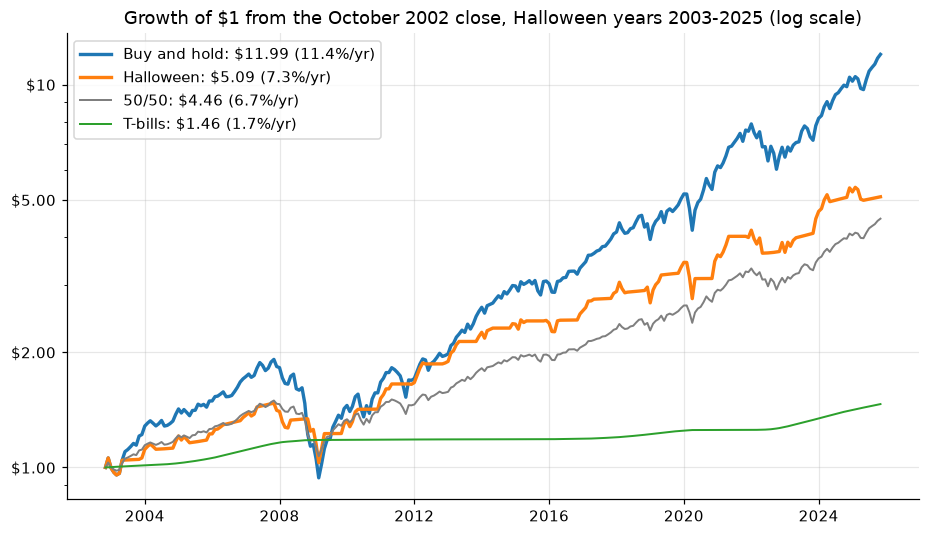

saved halloween_work/outputs_v7/08c_growth_of_1_since_1999.png


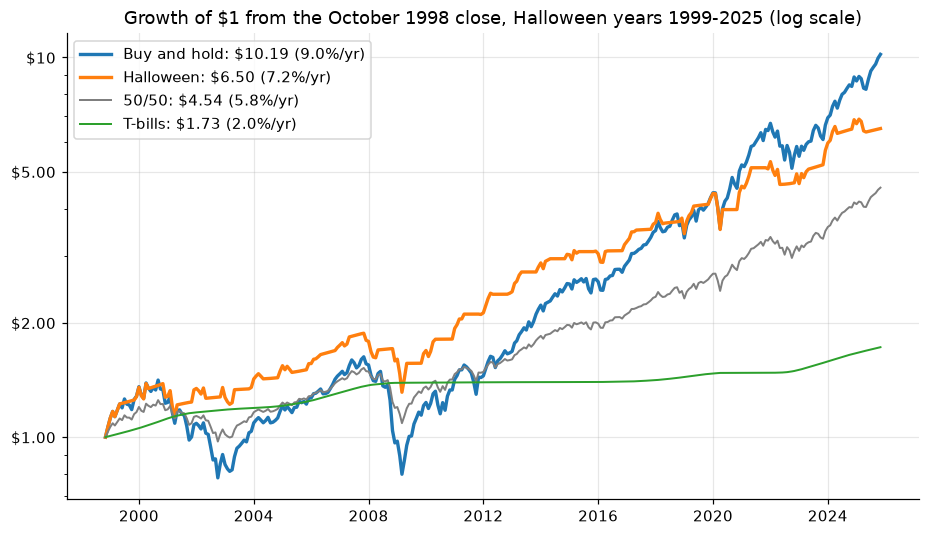

In [19]:
# --- Charts: growth of $1 since each cutoff (the post-publication finding) ---
growth_post = {}
for fy_ in [PUBLICATION_YEAR + 1, WORKING_PAPER_YEAR + 1]:
    tag_ = f"08{'b' if fy_ == PUBLICATION_YEAR + 1 else 'c'}_growth_of_1_since_{fy_}"
    s_ = strat_c[strat_c["hyear"] >= fy_]
    if s_["hyear"].nunique() < 3:
        print(f"Growth chart from {fy_} skipped: fewer than 3 complete Halloween years.")
        continue
    w_ = (1 + s_[["bh", "hw", "mix", "cash"]]).cumprod()
    w_.loc[s_.index[0] - 1] = 1.0
    w_ = w_.sort_index()
    w_.to_csv(OUTPUT_DIR / f"{tag_}.csv")
    growth_post[fy_] = w_

    fig, ax = plt.subplots(figsize=(10, 5.5))
    x_ = w_.index.to_timestamp(how="end")
    for col, colr, name in [("bh", C_BH, "Buy and hold"), ("hw", C_HW, "Halloween"),
                            ("mix", C_MIX, "50/50"), ("cash", C_CASH, "T-bills")]:
        cagr_ = w_[col].iloc[-1] ** (12 / len(s_)) - 1
        ax.plot(x_, w_[col], color=colr, lw=2.2 if col in ("bh", "hw") else 1.3,
                label=f"{name}: ${w_[col].iloc[-1]:,.2f} ({cagr_:.1%}/yr)")
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(mtick.LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v:,.0f}" if v >= 10 else f"${v:.2f}"))
    ax.yaxis.set_minor_formatter(mtick.NullFormatter())
    ax.set_title(f"Growth of $1 from the October {fy_ - 1} close, Halloween years {fy_}-{YEARS.max()} (log scale)")
    ax.legend(loc="upper left")
    savefig(fig, tag_)
    plt.show()

## 5c. Quant scorecard: the risk-adjusted numbers in one place

Sections 2 and 5b already estimate the Sharpe ratio, Jensen's alpha and drawdowns. This section puts them in one table per period, next to the other statistics a quant researcher expects, so the video, the GitHub write-up and a resume line all quote the same run.

**Per strategy and period** (buy-and-hold, Halloween, Halloween net of costs, 50/50):

- CAGR, volatility, **Sharpe ratio with a 95% year-block bootstrap CI**, Sortino ratio (downside deviation below the cash return), maximum drawdown, Calmar ratio (CAGR ÷ |max drawdown|), skewness, excess kurtosis, worst month, share of months up.

**Halloween against the market** (buy-and-hold, both legs in excess of the cash return):

- beta, **Jensen's alpha** per year with its **Newey–West t-statistic**, tracking error against the same-beta stock/T-bill mix, and the **information (appraisal) ratio** = alpha ÷ tracking error;
- the Sharpe difference (Halloween minus buy-and-hold) with the joint bootstrap CI from sections 2 and 5b.

**Periods:** full sample, through/after 1998 and through/after 2002 (as in 5b), plus the **observed all-ETF sample** (SPY for stocks, BIL for cash, both after fund fees), shown next to the main series on the same years.

**Net of costs:** `SCORECARD_COST_BPS` one way per switch, charged in November's return (bought at the October close) and May's (sold at the April close). Each year compounds to exactly section 7's `(1 + HW)(1 − c)² − 1`; the cell asserts this.

**Also:** Sharpe and alpha by decade (10-year samples, descriptive only), and a rolling `ROLL_YEARS`-year alpha with a 95% band (chart `08d`).

**Why only the market as benchmark?** The strategy holds the S&P 500 or T-bills and nothing else, so the market is the relevant benchmark. Size, value and momentum regressions are for stock-selection strategies; here they would mostly describe the index's own tilts. (Ken French factor data is also opt-in in this notebook for licensing reasons.)

**Reading it:** the 50/50 mix's Sharpe equals buy-and-hold's by construction. Say "higher Sharpe" only when the difference CI excludes zero, and quote alpha only with its t-statistic and years. The last cell of this section writes `resume_lines.txt`: one resume bullet and one video-description paragraph built from these numbers, with wording that follows the significance tests.

In [20]:
# ---- Settings for this section ----
SCORECARD_COST_BPS = 10   # one-way cost per switch for the net-of-costs rows (Halloween switches twice a year)
SWITCH_MONTHS = (11, 5)   # November's return carries the October-close purchase; May's carries the April-close sale


# ---- Helpers ----
def complete_years(s, years=None):
    """Halloween years with all 12 months in strategy frame s (optionally limited to `years`),
    never later than the main sample's last year."""
    n = s.groupby("hyear").size()
    yrs = n.index[n == 12]
    if years is not None:
        yrs = yrs.intersection(pd.Index(years))
    return sorted(int(y) for y in yrs if y <= YEARS.max())


def apply_switch_costs(s, bps):
    """Halloween net of a one-way cost per switch; each complete year compounds to (1 + HW)(1 - c)^2 - 1."""
    c = bps / 1e4
    out = s.copy()
    hit = out["month"].isin(SWITCH_MONTHS).to_numpy()
    out.loc[hit, "hw"] = (1 + out.loc[hit, "hw"]) * (1 - c) - 1
    return out


def scorecard_stats(r, rf):
    """Risk/return statistics from monthly simple returns r and the cash return rf (same index)."""
    r = pd.Series(r, dtype=float)
    rf = pd.Series(rf, dtype=float).reindex(r.index)
    p = perf(r, rf)                                          # CAGR, ann_vol, sharpe, max_drawdown (section 0)
    ex = (r - rf).to_numpy()
    downside = np.sqrt(np.mean(np.minimum(ex, 0.0) ** 2))   # downside deviation below the cash return
    sd0 = ex.std(ddof=0)
    z = (ex - ex.mean()) / sd0 if sd0 > 1e-12 else np.full_like(ex, np.nan)
    mdd = p["max_drawdown"]
    return {"CAGR": p["CAGR"], "ann_vol": p["ann_vol"], "sharpe": p["sharpe"],
            "sortino": ex.mean() / downside * np.sqrt(12) if downside > 1e-12 else np.nan,
            "max_drawdown": mdd, "calmar": p["CAGR"] / abs(mdd) if mdd < 0 else np.nan,
            "skew": float(np.mean(z ** 3)), "excess_kurtosis": float(np.mean(z ** 4) - 3.0),
            "worst_month": float(r.min()), "share_months_up": float((r > 0).mean())}


def alpha_vs_market(s, col="hw"):
    """Jensen's alpha of `col` on buy-and-hold, both in excess of the cash leg (Newey-West SEs).
    Tracking error is the residual volatility, i.e. relative to a same-beta stock/cash mix."""
    y = (s[col] - s["cash"]).to_numpy()
    X = np.column_stack([np.ones(len(s)), (s["bh"] - s["cash"]).to_numpy()])
    b, se, t, p = ols_nw(y, X, NW_LAGS)
    resid = y - X @ b
    te = resid.std(ddof=2) * np.sqrt(12)
    a = b[0] * 12
    return {"beta": float(b[1]), "alpha_annual": float(a), "alpha_se_annual": float(se[0] * 12),
            "alpha_t": float(t[0]), "alpha_p": float(p[0]), "tracking_error": float(te),
            "info_ratio": float(a / te) if te > 1e-12 else np.nan}


def excess_matrix(s, col, yrs):
    """(years x 12) monthly excess returns over the cash leg, in Halloween-year month order."""
    def piv(c):
        return s.pivot(index="hyear", columns="month", values=c).loc[yrs, HY_ORDER].to_numpy()
    return piv(col) - piv("cash")


def sharpe_draws(s, cols, yrs):
    """Joint year-block bootstrap draws of annualized Sharpe ratios (same resampled years for every column)."""
    ix = boot_index_matrix(len(yrs), N_BOOT_SHARPE, BLOCK_YEARS, SEED)
    return {c: _sharpe(excess_matrix(s, c, yrs)[ix].reshape(len(ix), -1)) for c in cols}


NET_LABEL = f"Halloween, {SCORECARD_COST_BPS} bps per switch"
SC_LABELS = {"bh": "Buy and hold", "hw": "Halloween", "hw_net": NET_LABEL,
             "mix": "50/50 (Sharpe = buy-and-hold by construction)"}


def scorecard_sample(s_all, yrs, period, source):
    """One row per strategy for a set of complete Halloween years."""
    s = s_all[s_all["hyear"].isin(yrs)].copy()
    s["hw_net"] = apply_switch_costs(s, SCORECARD_COST_BPS)["hw"]
    draws = sharpe_draws(s, list(SC_LABELS), yrs)
    bh_sharpe = scorecard_stats(s["bh"], s["cash"])["sharpe"]
    rows = []
    for col, lab in SC_LABELS.items():
        row = {"period": period, "source": source, "years": f"{min(yrs)}-{max(yrs)}", "n_years": len(yrs),
               "strategy": lab, **scorecard_stats(s[col], s["cash"])}
        row["sharpe_lo"], row["sharpe_hi"] = (float(v) for v in np.percentile(draws[col], [2.5, 97.5]))
        if col in ("hw", "hw_net"):
            row.update(alpha_vs_market(s, col))
            row["sharpe_minus_BH"] = row["sharpe"] - bh_sharpe
            row["sharpe_minus_BH_lo"], row["sharpe_minus_BH_hi"] = (
                float(v) for v in np.percentile(draws[col] - draws["bh"], [2.5, 97.5]))
        rows.append(row)
    return rows


# ---- Self-tests for these helpers (synthetic data, no downloads) ----
_sc_idx = pd.period_range("2000-11", "2003-10", freq="M")
_sc_toy = pd.DataFrame({"r_stock": np.where(np.isin(np.asarray(_sc_idx.month), WINTER), 0.01, -0.01),
                        "r_cash": 0.002}, index=_sc_idx)
_sc_s = strategy_returns(_sc_toy)
_sc_gross = annualize(_sc_s, 2001, last_year=2003)
_sc_net = annualize(apply_switch_costs(_sc_s, 25), 2001, last_year=2003)
assert np.allclose(_sc_net["HW"], (1 + _sc_gross["HW"]) * (1 - 0.0025) ** 2 - 1), "switch-cost bookkeeping"
assert np.allclose(_sc_net["BH"], _sc_gross["BH"]), "costs must not touch buy-and-hold"

_sc_rng = np.random.default_rng(1)
_sc_m = pd.DataFrame({"cash": np.full(240, 0.003), "bh": _sc_rng.normal(0.008, 0.045, 240)})
_sc_m["hw"] = _sc_m["cash"] + 0.002 + 0.5 * (_sc_m["bh"] - _sc_m["cash"]) + _sc_rng.normal(0, 0.001, 240)
_sc_a = alpha_vs_market(_sc_m)
assert abs(_sc_a["beta"] - 0.5) < 0.01 and abs(_sc_a["alpha_annual"] - 0.024) < 0.003, _sc_a
assert _sc_a["info_ratio"] > 0 and np.isclose(_sc_a["alpha_annual"] / _sc_a["alpha_se_annual"], _sc_a["alpha_t"])

_sc_st = scorecard_stats(pd.Series([0.10, -0.50, 0.20]), pd.Series([0.0, 0.0, 0.0]))
assert np.isclose(_sc_st["max_drawdown"], -0.5) and np.isclose(_sc_st["calmar"], _sc_st["CAGR"] / 0.5)
assert np.isclose(_sc_st["worst_month"], -0.5) and np.isclose(_sc_st["share_months_up"], 2 / 3)
_sc_sym = scorecard_stats(pd.Series([0.02, -0.02] * 6), pd.Series([0.0] * 12))
assert abs(_sc_sym["sharpe"]) < 1e-9 and abs(_sc_sym["skew"]) < 1e-9
print("Section 5c self-tests passed (switch costs, alpha regression, drawdown/Calmar, Sharpe/skew).")


# ---- Scorecard: main series, every period from section 5b ----
MAIN_SOURCE = "S&P total return, modeled T-bills"
sc_rows = []
for name_, fy_, ly_ in RISK_PERIODS:
    yrs_ = [int(y) for y in YEARS if (fy_ is None or y >= fy_) and (ly_ is None or y <= ly_)]
    if len(yrs_) < 5:
        print(f"{name_}: skipped (fewer than 5 complete Halloween years)")
        continue
    sc_rows += scorecard_sample(strat_c, yrs_, name_, MAIN_SOURCE)

# ---- Observed all-ETF sample (SPY for stocks, BIL for cash), next to the main series on the same years ----
ETF_PERIOD = f"Observed ETFs: SPY + {CASH_ETF}"
ETF_MATCH_PERIOD = f"Main, matched to SPY + {CASH_ETF} years"
if "r_bil" in us and us["r_bil"].notna().any():
    s_etf = strategy_returns(us, "r_spy", "r_bil")
    etf_yrs = [y for y in complete_years(s_etf) if y in set(YEARS)]
    if len(etf_yrs) >= 5:
        sc_rows += scorecard_sample(strat_c, etf_yrs, ETF_MATCH_PERIOD, MAIN_SOURCE)
        sc_rows += scorecard_sample(s_etf, etf_yrs, ETF_PERIOD,
                                    f"SPY and {CASH_ETF} adjusted closes (after fund fees)")
    else:
        print(f"ETF scorecard skipped: only {len(etf_yrs)} complete SPY + {CASH_ETF} years.")
else:
    print(f"ETF scorecard skipped: no {CASH_ETF} returns.")

scorecard = pd.DataFrame(sc_rows)


def sc_get(period, strategy):
    m_ = scorecard[(scorecard["period"] == period) & (scorecard["strategy"] == strategy)]
    return m_.iloc[0] if len(m_) else None


# ---- Consistency with sections 2, 5b and 7 ----
_full = sc_get("Full sample", "Halloween")
assert np.isclose(_full["alpha_annual"], timing.iloc[0]["annualized_simple"]), "alpha differs from section 2"
assert np.isclose(_full["sharpe"], summary.loc["hw", "sharpe"]), "Sharpe differs from section 2"
assert np.isclose(sc_get("Full sample", "Buy and hold")["sharpe"], summary.loc["bh", "sharpe"])
for name_, r_ in risk_tbl.iterrows():
    h_ = sc_get(name_, "Halloween")
    if h_ is not None:
        assert np.isclose(h_["alpha_annual"], r_["alpha_annual"]), f"alpha differs from 5b: {name_}"
        assert np.isclose(h_["sharpe"], r_["HW_sharpe"]), f"Sharpe differs from 5b: {name_}"
_net_ann = annualize(apply_switch_costs(strat_c, SCORECARD_COST_BPS), FIRST_YEAR).reindex(YEARS)
assert np.allclose(_net_ann["HW"], (1 + ann["HW"]) * (1 - SCORECARD_COST_BPS / 1e4) ** 2 - 1), \
    "net-of-cost returns differ from section 7's formula"

scorecard.to_csv(OUTPUT_DIR / "quant_scorecard_long.csv", index=False)
sc_cols = ["years", "CAGR", "ann_vol", "sharpe", "sharpe_lo", "sharpe_hi", "sortino", "max_drawdown", "calmar",
           "skew", "excess_kurtosis", "worst_month", "beta", "alpha_annual", "alpha_t", "info_ratio"]
with pd.option_context("display.max_rows", 100):
    display(pct_table(scorecard.set_index(["period", "strategy"])[sc_cols],
                      ["CAGR", "ann_vol", "max_drawdown", "worst_month", "alpha_annual"]))

# ---- Headline: one row per period, formatted for slides and the write-up ----
head_rows = []
for period_ in scorecard["period"].drop_duplicates():
    b_, h_, n_ = sc_get(period_, "Buy and hold"), sc_get(period_, "Halloween"), sc_get(period_, NET_LABEL)
    head_rows.append({
        "period": period_, "years": h_["years"], "source": h_["source"],
        "HW_sharpe": f"{h_['sharpe']:.2f} [{h_['sharpe_lo']:.2f}, {h_['sharpe_hi']:.2f}]",
        "BH_sharpe": f"{b_['sharpe']:.2f} [{b_['sharpe_lo']:.2f}, {b_['sharpe_hi']:.2f}]",
        "HW_minus_BH_sharpe": (f"{h_['sharpe_minus_BH']:+.2f} "
                               f"[{h_['sharpe_minus_BH_lo']:+.2f}, {h_['sharpe_minus_BH_hi']:+.2f}]"),
        "beta": round(h_["beta"], 2),
        "alpha_per_yr": f"{h_['alpha_annual']:+.2%} (t={h_['alpha_t']:.2f})",
        "info_ratio": round(h_["info_ratio"], 2),
        f"alpha_net_{SCORECARD_COST_BPS}bps": f"{n_['alpha_annual']:+.2%} (t={n_['alpha_t']:.2f})",
        "maxDD_HW_vs_BH": f"{h_['max_drawdown']:.0%} vs {b_['max_drawdown']:.0%}",
        "sortino_HW_vs_BH": f"{h_['sortino']:.2f} vs {b_['sortino']:.2f}",
        "calmar_HW_vs_BH": f"{h_['calmar']:.2f} vs {b_['calmar']:.2f}",
    })
sc_headline = pd.DataFrame(head_rows).set_index("period")
sc_headline.to_csv(OUTPUT_DIR / "quant_scorecard_headline.csv")
with pd.option_context("display.max_colwidth", 60):
    display(sc_headline)


def sig_words(p):
    return "statistically significant" if p < 0.05 else "not statistically significant"


def sharpe_words(r_):
    if r_["sharpe_minus_BH_lo"] > 0:
        return "HIGHER Sharpe than buy-and-hold (CI excludes zero)"
    if r_["sharpe_minus_BH_hi"] < 0:
        return "LOWER Sharpe than buy-and-hold (CI excludes zero)"
    return "Sharpe NOT DISTINGUISHABLE from buy-and-hold (CI includes zero)"


for period_ in sc_headline.index:
    h_, b_, n_ = sc_get(period_, "Halloween"), sc_get(period_, "Buy and hold"), sc_get(period_, NET_LABEL)
    print(f"\n{period_} ({h_['years']}, {int(h_['n_years'])} years; {h_['source']})")
    print(f"  Sharpe: Halloween {h_['sharpe']:.2f} [{h_['sharpe_lo']:.2f}, {h_['sharpe_hi']:.2f}] vs buy-and-hold "
          f"{b_['sharpe']:.2f} [{b_['sharpe_lo']:.2f}, {b_['sharpe_hi']:.2f}] -> {sharpe_words(h_)}")
    print(f"  Alpha vs a same-beta mix (beta {h_['beta']:.2f}): {h_['alpha_annual']:+.2%}/yr, "
          f"t={h_['alpha_t']:.2f} -> {sig_words(h_['alpha_p'])}; information ratio {h_['info_ratio']:.2f}")
    print(f"  Net of {SCORECARD_COST_BPS} bps per switch: alpha {n_['alpha_annual']:+.2%}/yr "
          f"(t={n_['alpha_t']:.2f}), Sharpe {n_['sharpe']:.2f}")

Section 5c self-tests passed (switch costs, alpha regression, drawdown/Calmar, Sharpe/skew).


years  CAGR %  ann_vol %  sharpe  sharpe_lo  sharpe_hi  sortino  max_drawdown %  calmar  \
period                           strategy                                                                                                                                     
Full sample                      Buy and hold                                   1961-2025   10.83      14.87  0.4662     0.2215     0.7387   0.6886          -50.95  0.2126   
                                 Halloween                                      1961-2025   10.25      10.27  0.5671     0.3547     0.8143   0.9323          -30.10  0.3405   
                                 Halloween, 10 bps per switch                   1961-2025   10.03      10.26  0.5478     0.3357     0.7939   0.8976          -30.31  0.3309   
                                 50/50 (Sharpe = buy-and-hold by construction)  1961-2025    7.97       7.44  0.4662     0.2215     0.7387   0.6886          -28.44  0.2800   
Through 1998                     Buy and hold                                   1961-1998   12.17      14.67  0.4328     0.1397     0.7397   0.6442          -42.68  0.2851   
                                 Halloween                                      1961-1998   12.48       9.79  0.6153     0.3137     0.9485   1.0664          -21.35  0.5848   
                                 Halloween, 10 bps per switch                   1961-1998   12.26       9.79  0.5949     0.2944     0.9277   1.0269          -21.66  0.5660   
                                 50/50 (Sharpe = buy-and-hold by construction)  1961-1998    9.56       7.33  0.4328     0.1397     0.7397   0.6442          -18.52  0.5161   
After working paper (1999+)      Buy and hold                                   1999-2025    8.98      15.15  0.5113     0.0826     1.0207   0.7488          -50.95  0.1762   
                                 Halloween                                      1999-2025    7.18      10.87  0.5066     0.2175     0.8677   0.7898          -30.10  0.2385   
                                 Halloween, 10 bps per switch                   1999-2025    6.96      10.86  0.4887     0.2007     0.8457   0.7596          -30.31  0.2298   
                                 50/50 (Sharpe = buy-and-hold by construction)  1999-2025    5.76       7.57  0.5113     0.0826     1.0207   0.7488          -28.44  0.2027   
Through 2002                     Buy and hold                                   1961-2002   10.52      15.05  0.3408     0.0545     0.6476   0.4984          -44.73  0.2352   
                                 Halloween                                      1961-2002   11.88      10.14  0.5648     0.3080     0.8564   0.9499          -21.35  0.5565   
                                 Halloween, 10 bps per switch                   1961-2002   11.66      10.13  0.5452     0.2904     0.8360   0.9132          -21.66  0.5381   
                                 50/50 (Sharpe = buy-and-hold by construction)  1961-2002    8.65       7.53  0.3408     0.0545     0.6476   0.4984          -22.20  0.3898   
After journal (2003+)            Buy and hold                                   2003-2025   11.41      14.55  0.7044     0.2658     1.2016   1.0598          -50.95  0.2239   
                                 Halloween                                      2003-2025    7.33      10.48  0.5702     0.2507     0.9841   0.9054          -30.10  0.2436   
                                 Halloween, 10 bps per switch                   2003-2025    7.12      10.47  0.5517     0.2319     0.9607   0.8735          -30.31  0.2349   
                                 50/50 (Sharpe = buy-and-hold by construction)  2003-2025    6.72       7.28  0.7044     0.2658     1.2016   1.0598          -28.44  0.2363   
Main, matched to SPY + BIL years Buy and hold                                   2008-2025   10.73      15.75  0.6449     0.2355     1.1503   0.9557          -50.95  0.2106   
                                 Halloween                 

,years,source,HW_sharpe,BH_sharpe,HW_minus_BH_sharpe,beta,alpha_per_yr,info_ratio,alpha_net_10bps,maxDD_HW_vs_BH,sortino_HW_vs_BH,calmar_HW_vs_BH
period,,,,,,,,,,,,
Full sample,1961-2025,"S&P total return, modeled T-bills","0.57 [0.35, 0.81]","0.47 [0.22, 0.74]","+0.10 [-0.04, +0.24]",0.47,+2.54% (t=3.02),0.34,+2.34% (t=2.78),-30% vs -51%,0.93 vs 0.69,0.34 vs 0.21
Through 1998,1961-1998,"S&P total return, modeled T-bills","0.62 [0.31, 0.95]","0.43 [0.14, 0.74]","+0.18 [+0.01, +0.33]",0.44,+3.21% (t=2.97),0.44,+3.01% (t=2.78),-21% vs -43%,1.07 vs 0.64,0.58 vs 0.29
After working paper (1999+),1999-2025,"S&P total return, modeled T-bills","0.51 [0.22, 0.87]","0.51 [0.08, 1.02]","-0.00 [-0.26, +0.23]",0.51,+1.56% (t=1.17),0.20,+1.36% (t=1.02),-30% vs -51%,0.79 vs 0.75,0.24 vs 0.18
Through 2002,1961-2002,"S&P total return, modeled T-bills","0.56 [0.31, 0.86]","0.34 [0.05, 0.65]","+0.22 [+0.06, +0.37]",0.46,+3.40% (t=3.30),0.45,+3.20% (t=3.11),-21% vs -45%,0.95 vs 0.50,0.56 vs 0.24
After journal (2003+),2003-2025,"S&P total return, modeled T-bills","0.57 [0.25, 0.98]","0.70 [0.27, 1.20]","-0.13 [-0.46, +0.17]",0.51,+0.76% (t=0.50),0.10,+0.56% (t=0.38),-30% vs -51%,0.91 vs 1.06,0.24 vs 0.22
"Main, matched to SPY + BIL years",2008-2025,"S&P total return, modeled T-bills","0.55 [0.15, 1.13]","0.64 [0.24, 1.15]","-0.09 [-0.31, +0.19]",0.50,+1.14% (t=0.64),0.14,+0.95% (t=0.53),-30% vs -51%,0.86 vs 0.96,0.24 vs 0.21
Observed ETFs: SPY + BIL,2008-2025,SPY and BIL adjusted closes (after fund fees),"0.56 [0.15, 1.13]","0.65 [0.24, 1.15]","-0.09 [-0.31, +0.19]",0.50,+1.14% (t=0.64),0.14,+0.95% (t=0.53),-30% vs -51%,0.87 vs 0.96,0.24 vs 0.21



Full sample (1961-2025, 65 years; S&P total return, modeled T-bills)
  Sharpe: Halloween 0.57 [0.35, 0.81] vs buy-and-hold 0.47 [0.22, 0.74] -> Sharpe NOT DISTINGUISHABLE from buy-and-hold (CI includes zero)
  Alpha vs a same-beta mix (beta 0.47): +2.54%/yr, t=3.02 -> statistically significant; information ratio 0.34
  Net of 10 bps per switch: alpha +2.34%/yr (t=2.78), Sharpe 0.55

Through 1998 (1961-1998, 38 years; S&P total return, modeled T-bills)
  Sharpe: Halloween 0.62 [0.31, 0.95] vs buy-and-hold 0.43 [0.14, 0.74] -> HIGHER Sharpe than buy-and-hold (CI excludes zero)
  Alpha vs a same-beta mix (beta 0.44): +3.21%/yr, t=2.97 -> statistically significant; information ratio 0.44
  Net of 10 bps per switch: alpha +3.01%/yr (t=2.78), Sharpe 0.59

After working paper (1999+) (1999-2025, 27 years; S&P total return, modeled T-bills)
  Sharpe: Halloween 0.51 [0.22, 0.87] vs buy-and-hold 0.51 [0.08, 1.02] -> Sharpe NOT DISTINGUISHABLE from buy-and-hold (CI includes zero)
  Alpha vs a sa

Decades are short (some partial; see n_years). Read the direction, not the t-statistics.


,years,n_years,BH_sharpe,HW_sharpe,sharpe_diff,beta,alpha_annual %,alpha_t,BH_maxDD %,HW_maxDD %
decade,,,,,,,,,,
1960s,1961-1969,9,0.5315,0.8800,0.3485,0.4811,4.28,2.5015,-22.22,-8.75
1970s,1970-1979,10,-0.0407,0.2642,0.3049,0.4883,3.27,1.4683,-42.68,-21.35
1980s,1980-1989,10,0.5222,0.5963,0.0741,0.4140,2.80,1.3513,-29.55,-9.74
1990s,1990-1999,10,0.9259,1.0190,0.0931,0.4101,3.80,1.5342,-15.37,-7.19
2000s,2000-2009,10,-0.1541,0.0041,0.1582,0.5134,1.32,0.7292,-50.95,-30.10
2010s,2010-2019,10,1.0504,1.1716,0.1212,0.3978,4.24,1.9949,-16.26,-11.66
2020s,2020-2025,6,0.8111,0.4351,-0.3760,0.6049,-2.55,-0.7176,-23.87,-19.60


Decades where Halloween's Sharpe beat buy-and-hold's: 6 of 7; positive alpha: 6 of 7.
saved halloween_work/outputs_v7/08d_rolling_alpha_and_sharpe.png


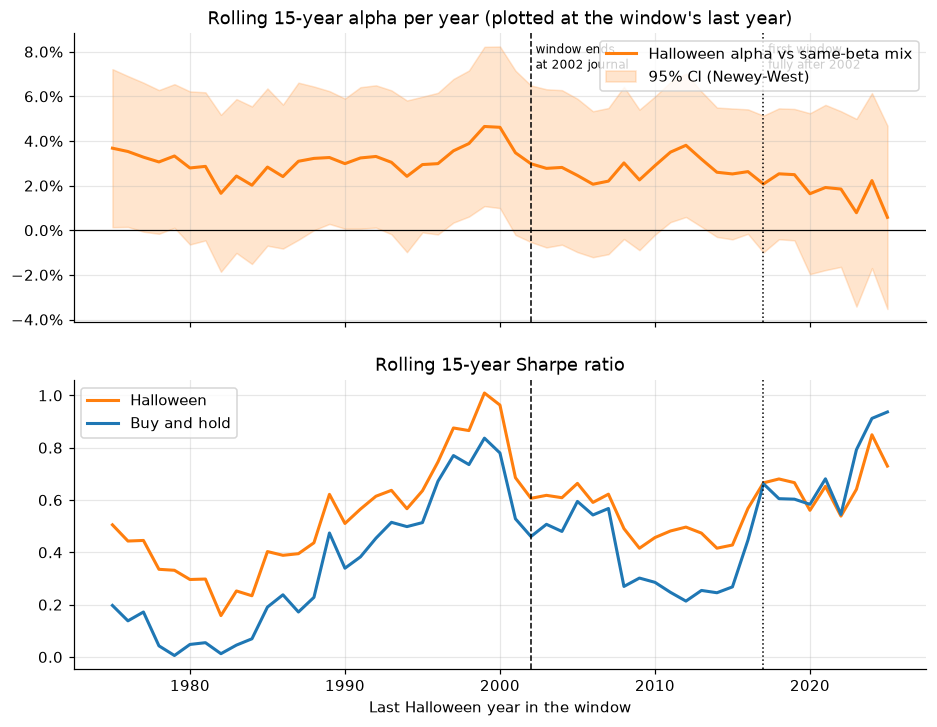

Latest 15-year window (2011-2025): alpha +0.58%/yr [-3.53%, +4.68%]; Sharpe Halloween 0.73 vs buy-and-hold 0.94. Overlapping windows are not independent evidence.


In [21]:
# ---- Sharpe and alpha by decade (10-year samples; descriptive, not tests) ----
dec_rows = []
for d_ in sorted({(int(y) // 10) * 10 for y in YEARS}):
    yrs_ = [int(y) for y in YEARS if d_ <= y < d_ + 10]
    if len(yrs_) < 5:
        continue
    s_ = strat_c[strat_c["hyear"].isin(yrs_)]
    b_, h_, a_ = scorecard_stats(s_["bh"], s_["cash"]), scorecard_stats(s_["hw"], s_["cash"]), alpha_vs_market(s_)
    dec_rows.append({"decade": f"{d_}s", "years": f"{min(yrs_)}-{max(yrs_)}", "n_years": len(yrs_),
                     "BH_sharpe": b_["sharpe"], "HW_sharpe": h_["sharpe"], "sharpe_diff": h_["sharpe"] - b_["sharpe"],
                     "beta": a_["beta"], "alpha_annual": a_["alpha_annual"], "alpha_t": a_["alpha_t"],
                     "BH_maxDD": b_["max_drawdown"], "HW_maxDD": h_["max_drawdown"]})
sc_decades = pd.DataFrame(dec_rows).set_index("decade")
sc_decades.to_csv(OUTPUT_DIR / "quant_scorecard_by_decade.csv")
print("Decades are short (some partial; see n_years). Read the direction, not the t-statistics.")
display(pct_table(sc_decades, ["alpha_annual", "BH_maxDD", "HW_maxDD"]))
print(f"Decades where Halloween's Sharpe beat buy-and-hold's: "
      f"{int((sc_decades['sharpe_diff'] > 0).sum())} of {len(sc_decades)}; "
      f"positive alpha: {int((sc_decades['alpha_annual'] > 0).sum())} of {len(sc_decades)}.")

# ---- Rolling ROLL_YEARS-year alpha and Sharpe (windows of consecutive complete Halloween years) ----
roll_rows = []
for end_ in YEARS:
    yrs_ = [int(y) for y in YEARS if end_ - ROLL_YEARS < y <= end_]
    if len(yrs_) < ROLL_YEARS:
        continue
    s_ = strat_c[strat_c["hyear"].isin(yrs_)]
    a_ = alpha_vs_market(s_)
    roll_rows.append({"end_year": int(end_), "alpha_annual": a_["alpha_annual"],
                      "alpha_lo": a_["alpha_annual"] - 1.96 * a_["alpha_se_annual"],
                      "alpha_hi": a_["alpha_annual"] + 1.96 * a_["alpha_se_annual"],
                      "HW_sharpe": scorecard_stats(s_["hw"], s_["cash"])["sharpe"],
                      "BH_sharpe": scorecard_stats(s_["bh"], s_["cash"])["sharpe"]})

if not roll_rows:
    print(f"Rolling chart skipped: fewer than {ROLL_YEARS} consecutive complete Halloween years.")
else:
    sc_roll = pd.DataFrame(roll_rows).set_index("end_year")
    sc_roll.to_csv(OUTPUT_DIR / f"rolling_{ROLL_YEARS}y_alpha_sharpe.csv")
    first_clean = PUBLICATION_YEAR + ROLL_YEARS   # first window made only of post-journal years

    fig, axes = plt.subplots(2, 1, figsize=(10, 7.5), sharex=True)
    ax = axes[0]
    ax.plot(sc_roll.index, sc_roll["alpha_annual"], color=C_HW, lw=2, label="Halloween alpha vs same-beta mix")
    ax.fill_between(sc_roll.index, sc_roll["alpha_lo"], sc_roll["alpha_hi"], color=C_HW, alpha=0.2,
                    label="95% CI (Newey-West)")
    ax.axhline(0, color="k", lw=0.8)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set_title(f"Rolling {ROLL_YEARS}-year alpha per year (plotted at the window's last year)")
    ax.legend(loc="upper right")
    ax = axes[1]
    ax.plot(sc_roll.index, sc_roll["HW_sharpe"], color=C_HW, lw=2, label="Halloween")
    ax.plot(sc_roll.index, sc_roll["BH_sharpe"], color=C_BH, lw=2, label="Buy and hold")
    ax.set_title(f"Rolling {ROLL_YEARS}-year Sharpe ratio")
    ax.legend(loc="upper left")
    for a in axes:
        a.axvline(PUBLICATION_YEAR, color="k", ls="--", lw=1)
        if first_clean <= sc_roll.index.max():
            a.axvline(first_clean, color="k", ls=":", lw=1)
    axes[0].text(PUBLICATION_YEAR + 0.3, 0.97, "window ends\nat 2002 journal", transform=axes[0].get_xaxis_transform(),
                 va="top", fontsize=8)
    if first_clean <= sc_roll.index.max():
        axes[0].text(first_clean + 0.3, 0.97, f"first window\nfully after {PUBLICATION_YEAR}",
                     transform=axes[0].get_xaxis_transform(), va="top", fontsize=8)
    axes[1].set_xlabel("Last Halloween year in the window")
    savefig(fig, "08d_rolling_alpha_and_sharpe")
    plt.show()
    last_ = sc_roll.iloc[-1]
    print(f"Latest {ROLL_YEARS}-year window ({sc_roll.index.max() - ROLL_YEARS + 1}-{sc_roll.index.max()}): "
          f"alpha {last_['alpha_annual']:+.2%}/yr [{last_['alpha_lo']:+.2%}, {last_['alpha_hi']:+.2%}]; "
          f"Sharpe Halloween {last_['HW_sharpe']:.2f} vs buy-and-hold {last_['BH_sharpe']:.2f}. "
          "Overlapping windows are not independent evidence.")

In [22]:
# ---- Resume bullet and video-description paragraph, generated from this run ----
# The wording follows the tests (significance of alpha, whether the Sharpe-difference CI includes zero).
# Reread both against the tables above before using them.
full_h, full_b = sc_get("Full sample", "Halloween"), sc_get("Full sample", "Buy and hold")
post_h, post_b = sc_get(POST_JOURNAL, "Halloween"), sc_get(POST_JOURNAL, "Buy and hold")
etf_h = sc_get(ETF_PERIOD, "Halloween")


def alpha_phrase(r_):
    return f"alpha {r_['alpha_annual']:+.1%}/yr (Newey-West t = {r_['alpha_t']:.1f})"


resume_line = (
    f"Halloween indicator (S&P 500 total return vs T-bills, {full_h['years']}): beta {full_h['beta']:.2f}, "
    f"{alpha_phrase(full_h)}, Sharpe {full_h['sharpe']:.2f} vs {full_b['sharpe']:.2f} for buy-and-hold "
    f"(difference 95% CI {full_h['sharpe_minus_BH_lo']:+.2f} to {full_h['sharpe_minus_BH_hi']:+.2f}), "
    f"max drawdown {full_h['max_drawdown']:.0%} vs {full_b['max_drawdown']:.0%}"
)
if post_h is not None:
    resume_line += (f"; after the {PUBLICATION_YEAR} publication ({post_h['years']}), {alpha_phrase(post_h)}, "
                    f"{sig_words(post_h['alpha_p'])}")
if etf_h is not None:
    resume_line += f"; observed SPY + {CASH_ETF} ETFs ({etf_h['years']}, after fees): {alpha_phrase(etf_h)}"
resume_line += "."

desc = [
    f"Results ({full_h['years']}, S&P 500 total return; T-bills while out of stocks): holding stocks only "
    f"from November to April returned {full_h['CAGR']:.1%} a year vs {full_b['CAGR']:.1%} for buy-and-hold, "
    f"with about {full_h['beta']:.0%} of the market exposure and a smaller worst drawdown "
    f"({full_h['max_drawdown']:.0%} vs {full_b['max_drawdown']:.0%}).",
    f"Risk-adjusted, that is {full_h['alpha_annual']:+.1%} a year of alpha against a same-risk stock/T-bill mix "
    f"(t = {full_h['alpha_t']:.1f}, {sig_words(full_h['alpha_p'])}); the Sharpe ratio was {full_h['sharpe']:.2f} "
    f"vs {full_b['sharpe']:.2f}, a difference "
    + ("whose 95% CI includes zero." if full_h["sharpe_minus_BH_lo"] <= 0 <= full_h["sharpe_minus_BH_hi"]
       else "whose 95% CI excludes zero."),
]
if post_h is not None:
    desc.append(
        f"Since the research was published ({post_h['years']}): alpha {post_h['alpha_annual']:+.1%} a year "
        f"(t = {post_h['alpha_t']:.1f}, {sig_words(post_h['alpha_p'])}); Sharpe {post_h['sharpe']:.2f} vs "
        f"{post_b['sharpe']:.2f} for buy-and-hold.")
desc.append(f"Net of {SCORECARD_COST_BPS} bps per switch, full-sample alpha is "
            f"{sc_get('Full sample', NET_LABEL)['alpha_annual']:+.1%} a year. Sharpe CIs: {BLOCK_YEARS}-year block "
            "bootstrap; t-statistics: Newey-West. Historical backtest with modeled T-bill returns; not investment advice.")
video_description = " ".join(desc)

(OUTPUT_DIR / "resume_lines.txt").write_text(
    "RESUME BULLET\n" + resume_line + "\n\nVIDEO DESCRIPTION\n" + video_description + "\n", encoding="utf-8")
print("RESUME BULLET\n" + resume_line)
print("\nVIDEO DESCRIPTION\n" + video_description)
print(f"\nsaved {OUTPUT_DIR / 'resume_lines.txt'}")

RESUME BULLET
Halloween indicator (S&P 500 total return vs T-bills, 1961-2025): beta 0.47, alpha +2.5%/yr (Newey-West t = 3.0), Sharpe 0.57 vs 0.47 for buy-and-hold (difference 95% CI -0.04 to +0.24), max drawdown -30% vs -51%; after the 2002 publication (2003-2025), alpha +0.8%/yr (Newey-West t = 0.5), not statistically significant; observed SPY + BIL ETFs (2008-2025, after fees): alpha +1.1%/yr (Newey-West t = 0.6).

VIDEO DESCRIPTION
Results (1961-2025, S&P 500 total return; T-bills while out of stocks): holding stocks only from November to April returned 10.2% a year vs 10.8% for buy-and-hold, with about 47% of the market exposure and a smaller worst drawdown (-30% vs -51%). Risk-adjusted, that is +2.5% a year of alpha against a same-risk stock/T-bill mix (t = 3.0, statistically significant); the Sharpe ratio was 0.57 vs 0.47, a difference whose 95% CI includes zero. Since the research was published (2003-2025): alpha +0.8% a year (t = 0.5, not statistically significant); Sharpe 0.

## 6. Other countries

Bouman & Jacobsen found the pattern in most of the markets they studied. This repeats the H1 test (winter minus summer) on international indices from Yahoo.

**Caveats**

- **These are mostly price-only indices** (except the DAX, typically quoted as a performance/total-return index); there are no local cash returns or FX adjustments. Therefore international results speak **only to the seasonal price pattern (H1)** and are **not comparable evidence about the net strategy (H2)**.
- **Dividend seasons bias price indices toward the effect.** Many European and Japanese companies pay dividends in spring or early summer, so ex-dividend drops land in the summer half and make summer price returns look worse. DAX uses a different return convention and is **not** a clean like-for-like cross-country control.
- **The DAX check.** The DAX is the one total-return index here, so spring dividends can't depress its summer. The cell prints where its gap ranks; if it is as large as the price indices' gaps, dividend timing is not the whole story.
- Yahoo's international histories are shorter and patchier than the S&P 500. Big monthly moves are printed so you can eyeball them (some, like Hong Kong in October 1987, are real).

FDR is applied across the international indices. The US rows are shown for reference and are not part of that family.

^HSI: monthly moves over 35% to eyeball: {'1987-10': '-44%'}


,ticker,type,years,n_years,mean_W %,mean_S %,mean_W_minus_S %,lo %,hi %,p_boot,median_W_minus_S %,share_years_W_beats_S %,p_sign,p_fdr
index,,,,,,,,,,,,,,
US - S&P 500 (price),^GSPC,price,1961-2025,65,6.83,1.83,5.00,2.59,7.48,0.0002,4.12,72.31,0.0004,NaN
US - S&P 500 (total return),^GSPC,total return,1961-2025,65,8.34,3.28,5.06,2.62,7.57,0.0002,4.22,72.31,0.0004,NaN
UK - FTSE 100,^FTSE,price,1985-2025,41,6.34,-0.10,6.44,2.84,10.22,0.0006,5.29,73.17,0.0043,0.0012
Germany - DAX,^GDAXI,total return,1989-2025,37,10.26,-0.13,10.39,4.76,16.12,0.0003,10.26,72.97,0.0076,0.0008
France - CAC 40,^FCHI,price,1991-2025,35,8.23,-1.78,10.01,5.30,15.36,0.0003,11.18,74.29,0.0060,0.0008
Switzerland - SMI,^SSMI,price,1992-2025,34,5.95,1.27,4.68,0.25,9.86,0.0552,6.29,67.65,0.0576,0.0631
Japan - Nikkei 225,^N225,price,1966-2025,60,7.73,0.76,6.98,2.94,11.03,0.0003,7.97,66.67,0.0135,0.0008
Hong Kong - Hang Seng,^HSI,price,1988-2025,38,7.04,2.42,4.61,-2.32,11.42,0.1940,4.71,57.89,0.4177,0.1940
Canada - S&P/TSX,^GSPTSE,price,1980-2025,46,6.54,1.24,5.30,1.97,8.97,0.0027,3.19,56.52,0.4614,0.0043


International indices with winter > summer on average (H1, price pattern only): 8 of 8; significant after FDR (q < 0.05): 6.
These say nothing about whether the Halloween strategy beats buy-and-hold abroad (no dividends except the DAX, no local cash returns).
Germany - DAX (total-return index, so no spring-dividend bias): winter minus summer +10.4% [+4.8%, +16.1%], rank 1 of 8 international indices.
saved halloween_work/outputs_v7/10_international.png


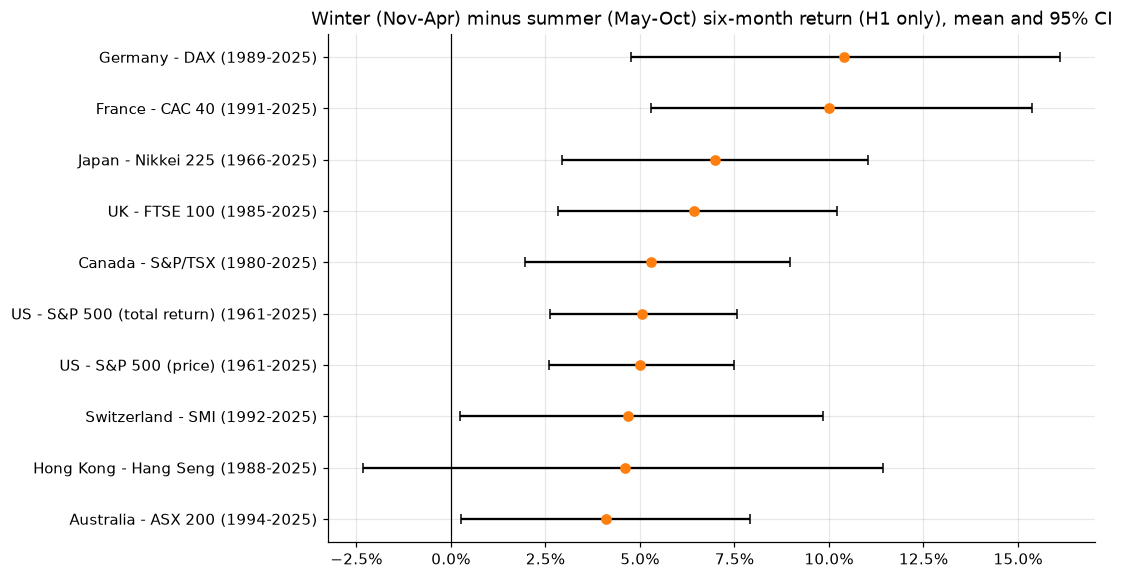

In [23]:
intl_rows = []
for tkr, (name, kind) in INTL_INDICES.items():
    try:
        r_ = monthly_returns(month_end_close(yahoo_daily(tkr)))
    except Exception as e:
        print(f"{tkr}: skipped ({e})")
        continue
    big = r_[r_.abs() > 0.35]
    if len(big):
        print(f"{tkr}: monthly moves over 35% to eyeball:", {str(k): f"{v:+.0%}" for k, v in big.items()})
    t_ = halves_table(r_)
    if len(t_) < MIN_INTL_YEARS:
        print(f"{tkr}: only {len(t_)} complete years; skipped")
        continue
    m_, st_ = boot(t_["W_minus_S"]), sign_test(t_["W_minus_S"])
    intl_rows.append({"index": name, "ticker": tkr, "type": kind, "years": f"{t_.index.min()}-{t_.index.max()}",
                      "n_years": len(t_), "mean_W": t_["W"].mean(), "mean_S": t_["S"].mean(),
                      "mean_W_minus_S": m_["est"], "lo": m_["lo"], "hi": m_["hi"], "p_boot": m_["p"],
                      "median_W_minus_S": t_["W_minus_S"].median(),
                      "share_years_W_beats_S": st_["share_pos"], "p_sign": st_["p"]})
intl = pd.DataFrame(intl_rows).set_index("index")
intl["p_fdr"] = bh_adjust(intl["p_boot"].to_numpy())

ref_rows = []
for col, name, kind in [("r_price", "US - S&P 500 (price)", "price"), ("r_stock", "US - S&P 500 (total return)", "total return")]:
    t_ = halves_table(us[col], FIRST_YEAR)
    t_ = t_[t_.index.isin(YEARS)]
    m_, st_ = boot(t_["W_minus_S"]), sign_test(t_["W_minus_S"])
    ref_rows.append({"index": name, "ticker": "^GSPC", "type": kind, "years": f"{t_.index.min()}-{t_.index.max()}",
                     "n_years": len(t_), "mean_W": t_["W"].mean(), "mean_S": t_["S"].mean(),
                     "mean_W_minus_S": m_["est"], "lo": m_["lo"], "hi": m_["hi"], "p_boot": m_["p"],
                     "median_W_minus_S": t_["W_minus_S"].median(),
                     "share_years_W_beats_S": st_["share_pos"], "p_sign": st_["p"], "p_fdr": np.nan})
intl_all = pd.concat([pd.DataFrame(ref_rows).set_index("index"), intl])
intl_all.to_csv(OUTPUT_DIR / "international.csv")
display(pct_table(intl_all, ["mean_W", "mean_S", "mean_W_minus_S", "lo", "hi", "median_W_minus_S",
                             "share_years_W_beats_S"]))
print(f"International indices with winter > summer on average (H1, price pattern only): "
      f"{int((intl['mean_W_minus_S'] > 0).sum())} of {len(intl)}; "
      f"significant after FDR (q < {FDR_Q}): {int((intl['p_fdr'] < FDR_Q).sum())}.")
print("These say nothing about whether the Halloween strategy beats buy-and-hold abroad "
      "(no dividends except the DAX, no local cash returns).")
_rank = intl["mean_W_minus_S"].rank(ascending=False, method="min")
for _name, _r in intl[intl["type"] == "total return"].iterrows():
    print(f"{_name} (total-return index, so no spring-dividend bias): winter minus summer "
          f"{_r['mean_W_minus_S']:+.1%} [{_r['lo']:+.1%}, {_r['hi']:+.1%}], "
          f"rank {int(_rank[_name])} of {len(intl)} international indices.")

plot_df = intl_all.sort_values("mean_W_minus_S")
fig, ax = plt.subplots(figsize=(9, 0.45 * len(plot_df) + 1.5))
ys = np.arange(len(plot_df))
mv = plot_df["mean_W_minus_S"].to_numpy()
ax.errorbar(mv, ys, xerr=[mv - plot_df["lo"].to_numpy(), plot_df["hi"].to_numpy() - mv], fmt="o",
            color=C_HW, ecolor="k", capsize=3)
ax.set_yticks(ys)
ax.set_yticklabels([f"{i} ({y})" for i, y in zip(plot_df.index, plot_df["years"])])
ax.axvline(0, color="k", lw=0.8)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Winter (Nov-Apr) minus summer (May-Oct) six-month return (H1 only), mean and 95% CI")
savefig(fig, "10_international")
plt.show()

## 7. Real-world drag: trading costs and taxes

**Costs.** Halloween switches stock↔cash twice annually; buy-and-hold has an initial purchase and, if liquidated, a final sale. The simple sensitivity treats each of the calendar strategy's two yearly switches as a fixed percentage cost and omits any initial/terminal buy-and-hold transaction cost, potential spreads, ETF management fees (except in SPY adjusted returns), execution slippage, and taxes. The breakeven cost is therefore **illustrative**, not directly executable. Negative breakeven means Halloween trails even before added costs.

**Taxes (stylized scenario, not historical after-tax evidence or tax advice).** A fixed set of assumed **modern US federal rates** is applied to the full multi-decade backtest even though actual law, investors, instruments, eligibility, and dividend timing changed. The model also approximates dividend reinvestment from the total-return minus price-return gap. It is intended as a directional demonstration of turnover drag, **not an accurate tax return**:

- Each winter position is held about 6 months, so its gain is short-term and taxed at the ordinary rate.
- All modeled dividends are taxed at one qualified-dividend rate, assuming eligibility/holding-period rules are met; actual dividend qualification and ex-dates are unavailable.
- Modeled T-bill carry is taxed at the assumed ordinary federal rate. State/local taxes and all individual circumstances are excluded.
- Net capital losses carry forward against future gains (the $3,000/year offset against ordinary income is ignored).
- Buy-and-hold pays the long-term rate once, if sold at the end; it is also shown never sold.
- No current income/capital-gain tax drag is applied in the tax-deferred account comparison. Actual retirement-account rules differ; transaction costs and fees still matter.

In [24]:
cost_rows = []
for bps in COST_BPS_GRID:
    c = bps / 1e4
    hw_net = (1 + ann["HW"]) * (1 - c) ** 2 - 1
    d_ = hw_net - ann["BH"]
    cost_rows.append({"one_way_cost_bps": bps, "HW_CAGR": geo(hw_net), "BH_CAGR": geo(ann["BH"]),
                      "mean_HW_minus_BH": d_.mean(), "share_years_HW_wins": (d_ > 0).mean()})
costs = pd.DataFrame(cost_rows).set_index("one_way_cost_bps")
costs.to_csv(OUTPUT_DIR / "trading_costs.csv")
display(pct_table(costs, ["HW_CAGR", "BH_CAGR", "mean_HW_minus_BH", "share_years_HW_wins"]))

be_mean = 1 - np.sqrt((1 + ann["BH"]).mean() / (1 + ann["HW"]).mean())
be_cagr = 1 - np.sqrt((1 + geo(ann["BH"])) / (1 + geo(ann["HW"])))
print(f"Illustrative breakeven one-way switch cost: {be_mean * 1e4:,.0f} bps "
      f"(average annual return), {be_cagr * 1e4:,.0f} bps (CAGR), "
      "ignoring initial/final buy-and-hold trading expenses.")
if be_mean < 0:
    print("Negative breakeven: Halloween already trails buy-and-hold on average before any costs.")

,HW_CAGR %,BH_CAGR %,mean_HW_minus_BH %,share_years_HW_wins %
one_way_cost_bps,,,,
0,10.25,10.83,-1.31,33.85
5,10.14,10.83,-1.42,33.85
10,10.03,10.83,-1.53,33.85
25,9.70,10.83,-1.86,33.85
50,9.15,10.83,-2.42,33.85


Illustrative breakeven one-way switch cost: -59 bps (average annual return), -26 bps (CAGR), ignoring initial/final buy-and-hold trading expenses.
Negative breakeven: Halloween already trails buy-and-hold on average before any costs.


In [25]:
def simulate_taxes(monthly, years, tax):
    """Illustrative modern-rate US tax scenario (not a historical investable tax backtest)."""
    d = add_calendar(monthly[["r_price", "r_div", "r_cash"]].dropna())
    d = d[d["hyear"].isin(years)]
    # Buy and hold: dividends taxed each month and reinvested; the gain is taxed only if sold at the end
    X = B = 1.0
    for rp, rd in zip(d["r_price"].to_numpy(), d["r_div"].to_numpy()):
        div = X * rd * (1 - tax["qualified_div"])
        X = X * (1 + rp) + div
        B += div
    bh_unsold, bh_sold = X, X - max(X - B, 0.0) * tax["long_term"]
    # Halloween: buy at the October close, sell at the April close, T-bills in between
    V, loss_cf, value, basis, holding = 1.0, 0.0, 0.0, 0.0, False
    for month, winter, rp, rd, rc in zip(d["month"].to_numpy(), d["winter"].to_numpy(), d["r_price"].to_numpy(),
                                         d["r_div"].to_numpy(), d["r_cash"].to_numpy()):
        if winter:
            if not holding:
                value, basis, holding = V, V, True
            div = value * rd * (1 - tax["qualified_div"])
            value = value * (1 + rp) + div
            basis += div
            if month == 4:   # sell at the April close: short-term gain or loss
                gain = value - basis
                if gain > 0:
                    taxable = max(gain - loss_cf, 0.0)
                    loss_cf = max(loss_cf - gain, 0.0)
                    value -= taxable * tax["ordinary"]
                else:
                    loss_cf += -gain
                V, holding = value, False
        else:
            V *= 1 + rc * (1 - tax["ordinary"])
    n = d["hyear"].nunique()
    return {"years": n, "BH_unsold_final": bh_unsold, "BH_sold_final": bh_sold, "HW_final": V,
            "BH_unsold_CAGR": bh_unsold ** (1 / n) - 1, "BH_sold_CAGR": bh_sold ** (1 / n) - 1,
            "HW_CAGR": V ** (1 / n) - 1, "loss_carryforward_left": loss_cf}


# With zero tax the simulation must reproduce the pre-tax results exactly
pre_tax = simulate_taxes(us, YEARS, dict(ordinary=0.0, long_term=0.0, qualified_div=0.0))
assert np.isclose(pre_tax["BH_unsold_final"], np.prod(1 + ann["BH"]), rtol=1e-9)
assert np.isclose(pre_tax["HW_final"], np.prod(1 + ann["HW"]), rtol=1e-9)

after_tax = simulate_taxes(us, YEARS, TAX)
tax_tbl = pd.DataFrame({
    "Tax-deferred account (IRA/401k)": {"BH_CAGR": pre_tax["BH_unsold_CAGR"], "HW_CAGR": pre_tax["HW_CAGR"],
                                        "BH_final_$1": pre_tax["BH_unsold_final"], "HW_final_$1": pre_tax["HW_final"]},
    "Taxable, buy-and-hold never sold": {"BH_CAGR": after_tax["BH_unsold_CAGR"], "HW_CAGR": after_tax["HW_CAGR"],
                                         "BH_final_$1": after_tax["BH_unsold_final"], "HW_final_$1": after_tax["HW_final"]},
    "Taxable, buy-and-hold sold at the end": {"BH_CAGR": after_tax["BH_sold_CAGR"], "HW_CAGR": after_tax["HW_CAGR"],
                                              "BH_final_$1": after_tax["BH_sold_final"], "HW_final_$1": after_tax["HW_final"]},
}).T
tax_tbl["HW_minus_BH_CAGR"] = tax_tbl["HW_CAGR"] - tax_tbl["BH_CAGR"]
tax_tbl.to_csv(OUTPUT_DIR / "taxes.csv")
print(f"Tax rates used: {TAX}")
display(pct_table(tax_tbl, ["BH_CAGR", "HW_CAGR", "HW_minus_BH_CAGR"]))

Tax rates used: {'ordinary': 0.24, 'long_term': 0.15, 'qualified_div': 0.15}


,BH_CAGR %,HW_CAGR %,BH_final_$1,HW_final_$1,HW_minus_BH_CAGR %
Tax-deferred account (IRA/401k),10.83,10.25,800.7984,567.8838,-0.58
"Taxable, buy-and-hold never sold",10.37,7.90,608.5258,139.8996,-2.47
"Taxable, buy-and-hold sold at the end",10.13,7.90,529.0374,139.8996,-2.23


## 8. Sensitivity and modern investability checks

Re-run H1 (`W_minus_S`), H2 (`HW_minus_BH`) and the supporting summer stock premium (`summer_premium`) under:

- **Historical span:** default versus 1935+ (longer and more dependent on estimated dividends).
- **Dividends:** Shiller estimate for all dates versus observed later total-return index versus price only.
- **Cash quote conversion:** discount-basis modeled carry versus the old annual-yield approximation, and a conservative two-month quote lag.
- **Tradable ETF:** SPY adjusted-close total returns (1994+), **paired with a main-index result on exactly the same 1994+ dates**; also pair main-index and SPY 2003+ periods. SPY includes fund expense drag, but not trading costs/taxes.
- **Modern subperiod:** main series 2003+, when the journal paper was already published.
- **Independent Ken French market/RF series:** OFF by default; only opt in if authorized, especially for a monetized video.

A separate sensitivity checks year-block lengths and whether a few extreme years drive differences. A short sample with a wide CI should not be interpreted as confirming that the effect vanished or survived.

**Added in v3:**

- **All-ETF check:** SPY for stocks and BIL (an actual 1–3 month T-bill ETF, from mid-2007) for cash, so both legs are observed after fund fees rather than modeled. Shown next to the main series over exactly the same years.
- **Outliers:** the last cell in this section tests the Maberly & Pierce (2004) critique directly.

In [26]:
def spec_row(name, a_):
    sp, ws, hb = boot(a_["summer_premium"]), boot(a_["W_minus_S"]), boot(a_["HW_minus_BH"])
    return {"spec": name, "years": f"{a_.index.min()}-{a_.index.max()}", "n": len(a_),
            "summer_premium": sp["est"], "sp_lo": sp["lo"], "sp_hi": sp["hi"], "sp_p": sp["p"],
            "W_minus_S": ws["est"], "ws_lo": ws["lo"], "ws_hi": ws["hi"], "ws_p": ws["p"],
            "HW_minus_BH": hb["est"], "hb_lo": hb["lo"], "hb_hi": hb["hi"], "hb_p": hb["p"],
            "share_HW_wins": (a_["HW_minus_BH"] > 0).mean(), "BH_CAGR": geo(a_["BH"]), "HW_CAGR": geo(a_["HW"])}


specs = [spec_row(f"Main ({TR_METHOD}, {CASH_METHOD}, Yahoo ^IRX)", ann)]
long_ann = annualize(strat, LONG_FIRST_YEAR)
if len(long_ann) > len(ann) and long_ann.index.min() < ann.index.min():
    specs.append(spec_row("Long sample (estimated early dividends)", long_ann))
else:
    print(f"Long {LONG_FIRST_YEAR}+ strategy check skipped: Yahoo ^IRX has no earlier cash "
          "quotes to extend the main backtest. Full-history price-only H1 is separately saved.")
post_2002 = ann[ann.index > PUBLICATION_YEAR]
if len(post_2002) >= 3:
    specs.append(spec_row("Main, 2003+ (post-2002 journal)", post_2002))
if "r_tr_shiller" in us:
    specs.append(spec_row("Shiller dividends throughout", annualize(strategy_returns(us, "r_tr_shiller", "r_cash"), FIRST_YEAR)))
specs.append(spec_row("Price only (no dividends)", annualize(strategy_returns(us, "r_price", "r_cash"), FIRST_YEAR)))
# Always compare the investable SPY era with the SAME sample window of the S&P total-return series.
spy_ann = annualize(strategy_returns(us, "r_spy", "r_cash"), 1994)
spy_common = ann.index.intersection(spy_ann.index)
if len(spy_common) < 3:
    raise RuntimeError("Not enough matching complete SPY years for the practical ETF check")
specs.append(spec_row("Main matched to SPY sample", ann.loc[spy_common]))
specs.append(spec_row("SPY adjusted-close with fund fees", spy_ann.loc[spy_common]))
spy_post = spy_common[spy_common > PUBLICATION_YEAR]
if len(spy_post) >= 3:
    specs.append(spec_row("Main matched to SPY 2003+", ann.loc[spy_post]))
    specs.append(spec_row("SPY adjusted-close 2003+", spy_ann.loc[spy_post]))
# All-ETF check: SPY for stocks and BIL (an actual T-bill ETF) for cash; both legs observed after fees.
if "r_bil" in us and us["r_bil"].notna().any():
    etf_ann = annualize(strategy_returns(us, "r_spy", "r_bil"), 1994)
    etf_common = ann.index.intersection(etf_ann.index)
    if len(etf_common) >= 3:
        specs.append(spec_row("Main matched to SPY+BIL sample", ann.loc[etf_common]))
        specs.append(spec_row(f"SPY + {CASH_ETF} (observed ETF returns, both legs)", etf_ann.loc[etf_common]))
# Cash conversion sensitivity: same stock series, alternate discount-yield conversion.
specs.append(spec_row("Legacy v1 cash conversion", annualize(
    strategy_returns(us, "r_stock", "r_cash_legacy"), FIRST_YEAR).loc[YEARS]))
specs.append(spec_row("Two-month cash quote lag", annualize(
    strategy_returns(us, "r_stock", "r_cash_two_month_lag"), FIRST_YEAR).loc[YEARS]))
if RUN_FRENCH_CHECK:
    try:
        fr = french_monthly()
        specs.append(spec_row("Ken French market (CRSP VW)", annualize(strategy_returns(fr), FIRST_YEAR)))
        specs.append(spec_row("Ken French market, long sample", annualize(strategy_returns(fr), LONG_FIRST_YEAR)))
    except Exception as e:
        print(f"Ken French check skipped: {e}")
robust = pd.DataFrame(specs).set_index("spec")
robust.to_csv(OUTPUT_DIR / "robustness.csv")
display(pct_table(robust, ["summer_premium", "sp_lo", "sp_hi", "W_minus_S", "ws_lo", "ws_hi",
                           "HW_minus_BH", "hb_lo", "hb_hi", "share_HW_wins", "BH_CAGR", "HW_CAGR"]))

Long 1935+ strategy check skipped: Yahoo ^IRX has no earlier cash quotes to extend the main backtest. Full-history price-only H1 is separately saved.


,years,n,summer_premium %,sp_lo %,sp_hi %,sp_p,W_minus_S %,ws_lo %,ws_hi %,ws_p,HW_minus_BH %,hb_lo %,hb_hi %,hb_p,share_HW_wins %,BH_CAGR %,HW_CAGR %
spec,,,,,,,,,,,,,,,,,
"Main (hybrid, discount_carry, Yahoo ^IRX)",1961-2025,65,1.00,-1.08,3.14,0.3554,5.06,2.62,7.57,1.9998e-04,-1.31,-3.55,0.82,0.2359,33.85,10.83,10.25
"Main, 2003+ (post-2002 journal)",2003-2025,23,4.39,0.67,7.98,0.0196,1.60,-2.60,5.94,4.6015e-01,-4.87,-8.51,-1.17,0.0096,17.39,11.41,7.33
Shiller dividends throughout,1961-2023,63,0.48,-1.54,2.47,0.6376,5.52,3.02,8.02,9.9990e-05,-0.77,-2.82,1.26,0.4641,34.92,10.24,10.19
Price only (no dividends),1961-2025,65,-0.45,-2.55,1.77,0.6710,5.00,2.59,7.48,1.9998e-04,0.25,-2.03,2.39,0.8182,46.15,7.75,8.71
Main matched to SPY sample,1994-2025,32,2.97,-0.58,6.37,0.0964,3.15,-0.88,7.17,1.2229e-01,-3.46,-6.90,0.14,0.0538,25.00,10.82,8.27
SPY adjusted-close with fund fees,1994-2025,32,2.90,-0.72,6.36,0.1108,3.16,-0.87,7.12,1.1909e-01,-3.39,-6.90,0.27,0.0644,25.00,10.70,8.23
Main matched to SPY 2003+,2003-2025,23,4.39,0.67,7.98,0.0196,1.60,-2.60,5.94,4.6015e-01,-4.87,-8.51,-1.17,0.0096,17.39,11.41,7.33
SPY adjusted-close 2003+,2003-2025,23,4.29,0.57,7.89,0.0233,1.71,-2.48,6.02,4.2386e-01,-4.77,-8.42,-1.04,0.0116,17.39,11.32,7.35
Main matched to SPY+BIL sample,2008-2025,18,4.05,1.29,6.67,0.0031,2.22,-2.48,7.23,3.4597e-01,-4.59,-7.29,-1.78,0.0012,22.22,10.73,7.14


In [27]:
# Bootstrap block length
blk_rows = []
for L in [1, 2, 3, 5, 8]:
    row = {"block_years": L}
    for col in ["summer_premium", "W_minus_S", "HW_minus_BH"]:
        bb = boot(ann[col], block=L)
        row[f"{col} CI"] = f"[{bb['lo']:+.1%}, {bb['hi']:+.1%}]"
        row[f"{col} p"] = round(bb["p"], 4)
    blk_rows.append(row)
blk = pd.DataFrame(blk_rows).set_index("block_years")
blk.to_csv(OUTPUT_DIR / "block_length_sensitivity.csv")
display(blk)

# Drop the years that most favoured each side
tail_rows = []
for side, col_order in [("Halloween", False), ("buy-and-hold", True)]:
    order = ann["HW_minus_BH"].sort_values(ascending=col_order)
    for k_ in [0, 1, 2, 3, 5]:
        if side == "buy-and-hold" and k_ == 0:
            continue
        keep = ann.drop(order.index[:k_])
        tail_rows.append({"drop_best_years_for": side if k_ else "(none)", "k": k_,
                          "years_dropped": ", ".join(map(str, order.index[:k_])),
                          "mean_HW_minus_BH": keep["HW_minus_BH"].mean(),
                          "mean_summer_premium": keep["summer_premium"].mean(),
                          "mean_W_minus_S": keep["W_minus_S"].mean(),
                          "BH_CAGR": geo(keep["BH"]), "HW_CAGR": geo(keep["HW"])})
tails = pd.DataFrame(tail_rows)
tails.to_csv(OUTPUT_DIR / "tail_year_sensitivity.csv", index=False)
display(pct_table(tails, ["mean_HW_minus_BH", "mean_summer_premium", "mean_W_minus_S", "BH_CAGR", "HW_CAGR"]))

,summer_premium CI,summer_premium p,W_minus_S CI,W_minus_S p,HW_minus_BH CI,HW_minus_BH p
block_years,,,,,,
1,"[-1.4%, +3.4%]",0.4103,"[+1.9%, +8.0%]",0.0015,"[-3.7%, +1.1%]",0.2884
2,"[-1.3%, +3.2%]",0.3753,"[+2.5%, +7.7%]",0.0003,"[-3.6%, +1.0%]",0.2535
3,"[-1.1%, +3.1%]",0.3554,"[+2.6%, +7.6%]",0.0002,"[-3.5%, +0.8%]",0.2359
5,"[-1.2%, +3.2%]",0.3815,"[+2.9%, +7.2%]",0.0001,"[-3.6%, +1.0%]",0.2699
8,"[-1.2%, +3.2%]",0.3869,"[+3.2%, +6.9%]",0.0001,"[-3.7%, +1.0%]",0.2783


,drop_best_years_for,k,years_dropped,mean_HW_minus_BH %,mean_summer_premium %,mean_W_minus_S %,BH_CAGR %,HW_CAGR %
0,(none),0,,-1.31,1.00,5.06,10.83,10.25
1,Halloween,1,2008,-1.76,1.48,4.83,11.79,10.58
2,Halloween,2,"2008, 2002",-2.07,1.79,4.60,12.28,10.70
3,Halloween,3,"2008, 2002, 1987",-2.39,2.05,4.17,12.38,10.50
4,Halloween,5,"2008, 2002, 1987, 1974, 1981",-3.00,2.69,4.08,13.45,10.84
5,buy-and-hold,1,2025,-1.00,0.68,5.54,10.67,10.41
6,buy-and-hold,2,"2025, 1980",-0.71,0.40,5.87,10.37,10.38
7,buy-and-hold,3,"2025, 1980, 2009",-0.43,0.09,6.43,10.38,10.71
8,buy-and-hold,5,"2025, 1980, 2009, 2003, 1997",0.06,-0.37,6.84,9.88,10.70


### Outliers: is it just a few crashes?

The best-known critique, Maberly & Pierce (2004), argues the US Halloween result is driven by two summer-half crashes, **October 1987** and **August 1998** (the LTCM collapse), and is no longer significant once those months are dummied out. Witte (2010) disputes this using outlier-robust methods. Three checks:

1. **Maberly–Pierce:** both monthly regressions with those two months removed (equivalent to a dummy for each).
2. **Season-blind:** remove the `N_EXTREME_MONTHS` largest absolute monthly price moves, whichever half they fall in. Also reports how many of the worst months fell in May–Oct.
3. **Winsorized:** clip every monthly return at the 1st/99th percentile, then rerun the annual endpoints.

Read these as "does the result *depend* on a handful of months?", not "should crashes be ignored?" A buy-and-hold investor lived through October 1987, so the main results stay the headline.

In [28]:
def monthly_seasonal_regressions(frame):
    """H1: log price return on a winter dummy. Supporting H2: summer mean of stock excess over cash (intercept)."""
    X = np.column_stack([np.ones(len(frame)), frame["winter"].astype(float).to_numpy()])
    b1, _, _, p1 = ols_nw(frame["logp"].to_numpy(), X, NW_LAGS)
    b2, _, _, p2 = ols_nw(frame["ex"].to_numpy(), X, NW_LAGS)
    return {"months": len(frame), "H1_gap_6m_log": b1[1] * 6, "H1_p": p1[1],
            "summer_excess_6m": b2[0] * 6, "summer_excess_p": p2[0]}


mreg = strat_c[["winter", "stock", "cash"]].copy()
mreg["r_price"] = us["r_price"].reindex(mreg.index)
mreg["logp"] = np.log1p(mreg["r_price"])
mreg["ex"] = mreg["stock"] - mreg["cash"]

mp_months = pd.PeriodIndex([pd.Period(m, "M") for m in MP_OUTLIER_MONTHS]).intersection(mreg.index)
extreme = mreg["r_price"].abs().nlargest(N_EXTREME_MONTHS).index
wins = mreg.copy()
for c in ["logp", "ex"]:
    wins[c] = wins[c].clip(wins[c].quantile(WINSOR_Q), wins[c].quantile(1 - WINSOR_Q))

outlier_variants = [
    ("All months", mreg),
    ("Without Oct 1987 and Aug 1998 (Maberly-Pierce)", mreg.drop(mp_months)),
    (f"Without the {N_EXTREME_MONTHS} largest monthly moves (either half)", mreg.drop(extreme)),
    (f"Winsorized at {WINSOR_Q:.0%}/{1 - WINSOR_Q:.0%}", wins),
]
outlier_reg = pd.DataFrame([{"sample": n_, **monthly_seasonal_regressions(f_)} for n_, f_ in outlier_variants]
                           ).set_index("sample")
outlier_reg.to_csv(OUTPUT_DIR / "outliers_monthly_regressions.csv")
print("Monthly regressions with and without outliers (Newey-West p-values)")
display(pct_table(outlier_reg, ["H1_gap_6m_log", "summer_excess_6m"]))

ext_tbl = pd.DataFrame({"S&P 500 price move": mreg.loc[extreme, "r_price"],
                        "half": np.where(mreg.loc[extreme, "winter"], "Nov-Apr", "May-Oct")}
                       ).sort_values("S&P 500 price move")
ext_tbl.to_csv(OUTPUT_DIR / "outliers_extreme_months.csv")
display(pct_table(ext_tbl, ["S&P 500 price move"]))
worst = mreg["r_price"].nsmallest(N_EXTREME_MONTHS).index
n_worst_summer = int((~mreg.loc[worst, "winter"]).sum())
n_ext_summer = int((~mreg.loc[extreme, "winter"]).sum())
print(f"{n_worst_summer} of the {N_EXTREME_MONTHS} worst months, and {n_ext_summer} of the "
      f"{N_EXTREME_MONTHS} largest moves either way, fell in May-Oct (half the months are May-Oct).")

# Annual endpoints with winsorized monthly stock returns (cutoffs from the main-sample months)
w_lo, w_hi = us.loc[strat_c.index, "r_stock"].quantile([WINSOR_Q, 1 - WINSOR_Q]).to_numpy()
us["r_stock_wins"] = us["r_stock"].clip(w_lo, w_hi)
ann_wins = annualize(strategy_returns(us, "r_stock_wins", "r_cash"), FIRST_YEAR).reindex(YEARS)
outlier_annual = pd.DataFrame([spec_row("Main", ann),
                               spec_row(f"Winsorized monthly stock returns ({WINSOR_Q:.0%}/{1 - WINSOR_Q:.0%})",
                                        ann_wins)]).set_index("spec")
outlier_annual.to_csv(OUTPUT_DIR / "outliers_annual_endpoints.csv")
display(pct_table(outlier_annual, ["summer_premium", "sp_lo", "sp_hi", "W_minus_S", "ws_lo", "ws_hi",
                                   "HW_minus_BH", "hb_lo", "hb_hi", "share_HW_wins", "BH_CAGR", "HW_CAGR"]))

Monthly regressions with and without outliers (Newey-West p-values)


,months,H1_gap_6m_log %,H1_p,summer_excess_6m %,summer_excess_p
sample,,,,,
All months,780,4.76,0.0014,1.12,0.3361
Without Oct 1987 and Aug 1998 (Maberly-Pierce),778,4.13,0.0041,1.70,0.1440
Without the 10 largest monthly moves (either half),770,3.42,0.0155,1.91,0.0855
Winsorized at 1%/99%,780,4.38,0.0023,1.40,0.2140


,S&P 500 price move %,half
1987-10,-21.76,May-Oct
2008-10,-16.94,May-Oct
1998-08,-14.58,May-Oct
2020-03,-12.51,Nov-Apr
1974-09,-11.93,May-Oct
1976-01,11.83,Nov-Apr
1975-01,12.28,Nov-Apr
2020-04,12.68,Nov-Apr
1987-01,13.18,Nov-Apr
1974-10,16.30,May-Oct


6 of the 10 worst months, and 5 of the 10 largest moves either way, fell in May-Oct (half the months are May-Oct).


,years,n,summer_premium %,sp_lo %,sp_hi %,sp_p,W_minus_S %,ws_lo %,ws_hi %,ws_p,HW_minus_BH %,hb_lo %,hb_hi %,hb_p,share_HW_wins %,BH_CAGR %,HW_CAGR %
spec,,,,,,,,,,,,,,,,,
Main,1961-2025,65,1.00,-1.08,3.14,0.3554,5.06,2.62,7.57,0.0002,-1.31,-3.55,0.82,0.2359,33.85,10.83,10.25
Winsorized monthly stock returns (1%/99%),1961-2025,65,1.32,-0.75,3.44,0.2184,4.70,2.43,6.97,0.0002,-1.69,-3.90,0.42,0.1223,32.31,11.21,10.22


## 9. This year so far (descriptive only)

For an October upload, show where the current **incomplete** May–October stretch stands, explicitly labeled *through the latest available trading date*. It is not included in hypothesis tests and is not a forecast. The synthetic T-bill carry in this section is calculated using available month-lagged quoted rates and prorated accrual days, not one overall ex-post averaged yield. Price and total-return endpoints are aligned to the same ending trade date. Do not suggest the seasonal effect forecasts next month's market.

**Settings at the top of the cell.** `SEASON_VIEW = "auto"` shows the half-year in progress today; `"summer"` shows the latest May–October, complete or not (use it if you rerun in November). `SECTION9_FRESH = True` downloads recent prices for this section only, without touching the cache, so you can rerun just this cell right before upload and the locked tables stay as they are. After a kernel restart, Run All with `REFRESH_DOWNLOADS = False` first; the cache keeps the other numbers unchanged. The 2026 summer half ends with the **October 30, 2026** close.

In [29]:
# ---- Settings for this section ----
SEASON_VIEW = "auto"    # "auto" = the half-year in progress today; "summer" = the latest May-Oct, complete or not
                        # (use "summer" if you rerun in November to show the summer that just ended)
SECTION9_FRESH = True   # download recent daily prices for this section only (not cached; locked tables untouched)
NOW = pd.Timestamp.today().normalize()   # re-read the clock: this cell may be rerun days after the rest


def yahoo_recent(ticker, start):
    """Uncached daily download, used only in this section."""
    df = _flatten_yf(yf.download(ticker, start=start, auto_adjust=False, actions=False,
                                 progress=False, threads=False))
    if df.empty:
        raise RuntimeError(f"Yahoo returned no recent data for {ticker}")
    df.index = pd.to_datetime(df.index)
    if df.index.tz is not None:
        df.index = df.index.tz_localize(None)
    return df[~df.index.duplicated(keep="last")].sort_index()


def last_close_on_or_before(daily, ts, col="Close"):
    s = pd.to_numeric(daily[col], errors="coerce").dropna()
    s = s[s.index <= ts]
    if s.empty:
        raise RuntimeError(f"No {col} close before {ts}")
    return float(s.iloc[-1]), s.index[-1]


def cash_carry_between(d0, d1, monthly_discount_quotes, lag=1):
    """Approximate accrued carry between two trading closes from lagged monthly quotes.

    Date fractions are used for an in-progress month; no later-period yield averages.
    Quote availability and execution dates remain modeled, not realized cash flows.
    """
    months = pd.period_range(d0.to_period("M"), d1.to_period("M"), freq="M")
    money = 1.0
    used = []
    for m in months:
        # Consider the share of each month elapsed after the purchase/sale date.
        m_end = m.end_time.normalize()
        prior_end = m.start_time - pd.Timedelta(days=1)
        a = max(d0, prior_end)
        b = min(d1, m_end)
        days = max((b - a).days, 0)
        if days == 0:
            continue
        q = monthly_discount_quotes.get(m - lag, np.nan)
        if not np.isfinite(q):
            return np.nan, used
        if CASH_METHOD == "discount_carry":
            rc = tbill_monthly_carry(q, accrual_days=days)
        else:
            rc = (1 + tbill_monthly_legacy(q)) ** (days / (365.25 / 12)) - 1
        money *= (1 + rc)
        used.append((str(m), days, float(q)))
    return money - 1, used


if SEASON_VIEW not in ("auto", "summer"):
    raise ValueError(f"SEASON_VIEW must be 'auto' or 'summer', not {SEASON_VIEW!r}")
show_summer = SEASON_VIEW == "summer" or 5 <= NOW.month <= 10
if show_summer:
    season_year = NOW.year if NOW.month >= 5 else NOW.year - 1
    start_ts, stop_ts = pd.Timestamp(season_year, 4, 30), pd.Timestamp(season_year, 10, 31)
    season_name, start_desc = f"May-Oct {season_year}", "April's final trading close"
else:
    season_year = NOW.year + int(NOW.month >= 11)
    start_ts, stop_ts = pd.Timestamp(season_year - 1, 10, 31), pd.Timestamp(season_year, 4, 30)
    season_name, start_desc = f"Nov-Apr {season_year - 1}/{season_year}", "October's final trading close"
season_done = NOW > stop_ts

px_d, tr_d, quotes_now = gspc_daily, tr_daily, tb
if SECTION9_FRESH:
    try:
        _from = (start_ts - pd.Timedelta(days=45)).strftime("%Y-%m-%d")
        px_d, tr_d = yahoo_recent("^GSPC", _from), yahoo_recent("^SP500TR", _from)
        quotes_now = monthly_discount_quotes_from_daily(yahoo_recent(CASH_TICKER, _from)).combine_first(tb)
    except Exception as e:
        print(f"Fresh Section 9 download failed ({e}); using the cached data instead.")
        px_d, tr_d, quotes_now = gspc_daily, tr_daily, tb

if show_summer:
    w_months = pd.period_range(f"{season_year - 1}-11", f"{season_year}-04", freq="M")
    w_ret = us["r_stock"].reindex(w_months)
    if w_ret.notna().all():
        print(f"Previous Nov-Apr: estimated/observed stock TR {comp(w_ret):+.1%}, "
              f"vs main-sample mean {ann['W'].mean():+.1%}")

# Both stock indices must be observed at the same endpoint for an apples-to-apples as-of date.
as_of = min(NOW, stop_ts)
shared_dates = px_d.index.intersection(tr_d.index)
end_date = shared_dates[shared_dates <= as_of].max()
if (as_of - end_date).days > 4:
    print(f"WARNING: price data end {end_date.date()}. Set SECTION9_FRESH = True (or refresh downloads) "
          "for current numbers.")
p0, d0 = last_close_on_or_before(px_d, start_ts)
t0, dt0 = last_close_on_or_before(tr_d, start_ts)
p1, _ = last_close_on_or_before(px_d, end_date)
t1, _ = last_close_on_or_before(tr_d, end_date)
if d0 != dt0:
    print(f"CHECK: starting trading date differs: price {d0.date()} versus total return {dt0.date()}")
cash_so_far, monthly_quotes_used = cash_carry_between(d0, end_date, quotes_now, TBILL_LAG_MONTHS)
status = "COMPLETE" if season_done else "PARTIAL PERIOD"
print(f"{season_name}, from {start_desc}: {d0.date()} to {end_date.date()} ({status})")
print(f"  S&P 500 price {p1 / p0 - 1:+.1%}; total-return index {t1 / t0 - 1:+.1%}; "
      f"modeled T-bill carry {cash_so_far:+.1%}")
if not np.isfinite(cash_so_far):
    print("  CHECK: a lagged ^IRX quote is missing for part of this period.")
print("  Cash proxy quotes used: previous-month Yahoo ^IRX;", len(monthly_quotes_used), "calendar segments")
season_now = {"season": season_name, "status": status, "start": d0.date(), "end": end_date.date(),
              "price": p1 / p0 - 1, "total_return": t1 / t0 - 1, "cash": cash_so_far}

Previous Nov-Apr: estimated/observed stock TR +6.0%, vs main-sample mean +8.3%
May-Oct 2026, from April's final trading close: 2026-04-30 to 2026-10-13 (PARTIAL PERIOD)
  S&P 500 price +8.4%; total-return index +8.9%; modeled T-bill carry +1.7%
  Cash proxy quotes used: previous-month Yahoo ^IRX; 6 calendar segments


## 10. Video numbers and publication checklist

`video_numbers.csv` is generated directly from the run and includes both 1998/2002 splits, the post-publication risk check (5b), the two distinct regressions, the SPY-era comparison, the section 5c quant scorecard with the generated resume bullet, and the Section 9 season-to-date numbers. Avoid reporting results from the present file until it has actually executed with your real downloaded data.

**Before recording:**

1. **Clean run:** `REFRESH_DOWNLOADS = True`, then Kernel → Restart & Run All; set the flag back to `False`. Quote numbers only from that one top-to-bottom run. If you run in November or later, set `LAST_HALLOWEEN_YEAR = 2025` first so the sample matches the script.
2. Complete self-tests and investigate all data/source warnings (including the stale-cache warning in Section 1); verify 1987 monthly return, 1981 yield conversion, Shiller total-return overlap, full-month coverage, latest ticker availability, and source-switch warnings.
3. Confirm whether your audience-facing historical performance uses **approximated dividends and T-bill carry** or **observed total-return/ETF dates**. Label charts accordingly.
4. **Cutoffs:** look at 1999+ and 2003+ side by side (section 5b) before choosing the title/conclusion. If they disagree, say so; if you lead with 2003+, say why and give the 1999+ answer too. Don't label 2003+ the first genuinely out-of-sample test.
5. **Risk claims:** "lower risk, and historically better than a same-risk mix" is a full-sample statement. Check the 2003+ row in section 5b before saying it still holds today. Say "higher Sharpe" only if the Sharpe-difference CI excludes zero. The 50/50 mix has the same Sharpe as buy-and-hold by construction, so it is not a second Sharpe finding.
6. **Primary endpoints:** lead with them, and call them "the two standard tests from the literature", not pre-registered. Describe everything else as supporting.
7. Use the post-period verdicts as worded. If one says **TOO SHORT TO TELL**, say exactly that on camera instead of "it stopped working" or "it still works."
8. If the Maberly–Pierce or season-blind rows change the conclusion, say so: "the result depends on a few crash months" is itself a finding.
9. Treat international results as **price-pattern (H1) evidence only**; they say nothing about whether the strategy pays abroad. Treat the 924 rankings as descriptive. Review flagged large international moves.
10. Distinguish turnover and the **stylized modern-tax-rate simulation** from real executable historical returns; no precise tax savings claim.
11. **Section 9:** rerun that cell right before upload (it downloads fresh prices on its own). The summer half ends with the October 30, 2026 close; in November use `SEASON_VIEW = "summer"`.
12. Do **not** upload vendors' raw cached data as part of a public GitHub repo.
13. **Resume and video description:** take numbers from `quant_scorecard_headline.csv` or `resume_lines.txt` (section 5c). Quote the Sharpe ratio with its CI, alpha with its Newey–West t-statistic, the years, and whether returns are modeled (S&P total return + modeled T-bills) or observed (SPY + BIL). Reread the generated wording against the tables before using it.

In [30]:
T = tests
key = []


def add(name, value, section):
    key.append({"number": name, "value": value, "section": section})


add("Historical main sample", f"Halloween years {YEARS.min()}-{YEARS.max()} ({len(YEARS)} complete years)", "1")
add("Cash quote source and coverage",
    f"{CASH_SOURCE}; {raw_tb.index.min()}-{raw_tb.index.max()}", "1")
if len(h1_full):
    add("S&P seasonality, independent FULL price-only sample",
        f"{h1_full.index.min()}-{h1_full.index.max()} ({len(h1_full)} years); "
        f"winter-minus-summer mean {h1_full['W_minus_S'].mean():+.2%}", "1")
add("Stock total return construction", f"{TR_METHOD}; observed ^SP500TR when available; Shiller-interpolated proxy earlier", "1")
add("Monthly cash model", f"{CASH_METHOD}; {CASH_TICKER} quote lag {TBILL_LAG_MONTHS} month(s); modeled not observed", "1")
for c, lab in [("bh", "Buy-and-hold"), ("hw", "Halloween"), ("mix", "50/50")]:
    add(f"{lab}: historical CAGR", f"{summary.loc[c, 'CAGR']:.2%}", "2")
    add(f"{lab}: $1 grows to", f"${summary.loc[c, 'final_$1']:,.0f}", "2")
    add(f"{lab}: worst observed drawdown", f"{summary.loc[c, 'max_drawdown']:.1%}", "2")
    add(f"{lab}: Sharpe" + (" (= buy-and-hold by construction)" if c == "mix" else ""),
        f"{summary.loc[c, 'sharpe']:.2f}", "2")
add("Average Nov-Apr stock return", f"{ann['W'].mean():+.1%}", "2")
add("Average May-Oct stock return", f"{ann['S'].mean():+.1%}", "2")
add("Average May-Oct modeled T-bill carry", f"{ann['Cs'].mean():+.1%}", "2")
add("Years with Nov-Apr stocks > May-Oct stocks", f"{int((ann['W_minus_S'] > 0).sum())} of {len(ann)}", "2")
add("Years Halloween beats buy-and-hold", f"{int((ann['HW_minus_BH'] > 0).sum())} of {len(ann)}", "2")
for k_, lab in [("W_minus_S", "PRIMARY H1: Nov-Apr minus May-Oct stock returns"),
                ("HW_minus_BH", "PRIMARY H2: Halloween minus buy-and-hold per year"),
                ("summer_premium", "Supports H2: May-Oct stocks minus cash proxy (cost of going away)"),
                ("HW_minus_MIX", "Halloween minus 50/50 per year")]:
    add(lab, fmt_ci(T.loc[k_, "mean"], T.loc[k_, "mean_lo"], T.loc[k_, "mean_hi"], T.loc[k_, "p_boot"]), "2")
add("H1 price-log regression seasonal dummy (approx 6-month log-return difference)",
    f"{reg_price.iloc[1]['approx_6month_log_gap']:+.2%}; HAC p={reg_price.iloc[1]['p']:.3f}", "2")
add("Summer excess regression, supports H2 (approx six simple months)",
    f"{reg.iloc[0]['coef_per_6_months_approx']:+.2%}; HAC p={reg.iloc[0]['p']:.3f}", "2")
add("November-April rank among 924 selections (premium gap; descriptive only)", f"#{rank_gap}", "4")
add("November-April rank among 924 selections (against buy-and-hold; descriptive only)", f"#{rank_adv}", "4")
add("Six-month month-sets that beat buy-and-hold historically", f"{n_beat_bh} of {len(combos)} (dependent selections)", "4")
for (split, metric), row in prepost.iterrows():
    add(f"{metric}, {split}: {row['period_pre']} vs {row['period_post']}",
        f"{row['mean_pre']:+.1%} vs {row['mean_post']:+.1%} (bootstrap change p={row['p_change']:.3f})", "5")
add("International indices with winter > summer PRICE return (H1 only; not a strategy test)", f"{int((intl['mean_W_minus_S'] > 0).sum())} of {len(intl)}", "6")
add("International indices significant after exploratory FDR", f"{int((intl['p_fdr'] < FDR_Q).sum())} of {len(intl)}", "6")
add("Illustrative breakeven one-way switch cost", f"{be_mean * 1e4:,.0f} bps", "7")
for idx_, row_ in tax_tbl.iterrows():
    add(f"{idx_}: Halloween vs buy-and-hold CAGR (stylized)", f"{row_['HW_CAGR']:.2%} vs {row_['BH_CAGR']:.2%}", "7")
for label in ["Main matched to SPY sample", "SPY adjusted-close with fund fees",
              "Main matched to SPY 2003+", "SPY adjusted-close 2003+", "Main, 2003+ (post-2002 journal)",
              "Main matched to SPY+BIL sample", f"SPY + {CASH_ETF} (observed ETF returns, both legs)"]:
    if label in robust.index:
        rr = robust.loc[label]
        add(f"{label}: BH CAGR / Halloween CAGR / summer stock premium",
            f"{rr['BH_CAGR']:.2%} / {rr['HW_CAGR']:.2%} / {rr['summer_premium']:+.2%}", "8")

# v3 additions
for k_ in ["W_minus_S", "HW_minus_BH"]:
    add(f"PRIMARY endpoint {k_}: share of years positive (exact sign-test p)",
        f"{T.loc[k_, 'share_positive']:.0%} (p={T.loc[k_, 'p_sign']:.3f})", "2")
add("Beta-matched alpha vs same-beta passive mix, full sample (per year, simple)",
    f"{timing.iloc[0]['annualized_simple']:+.2%}; HAC p={timing.iloc[0]['p']:.3f}; beta={timing.iloc[1]['coef']:.2f}", "2")
for name_, r_ in leger.iterrows():
    add(f"{name_}: CAGR; mean vs buy-and-hold per year",
        f"{r_['CAGR']:.2%}; {fmt_ci(r_['mean_vs_BH'], r_['lo'], r_['hi'], r_['p_boot'])}", "4b")
for (split_, metric_), r_ in prepost.iterrows():
    add(f"Post-period verdict: {metric_}, {split_}", f"{r_['verdict_post']} (MDE80 {r_['mde80_post']:.1%})", "5")
add(f"Worst {N_EXTREME_MONTHS} S&P months that fell in May-Oct", f"{n_worst_summer} of {N_EXTREME_MONTHS}", "8")
for name_, r_ in outlier_reg.iterrows():
    add(f"Outliers, {name_}: H1 6-mo log gap; summer stock excess over cash (supports H2)",
        f"{r_['H1_gap_6m_log']:+.2%} (p={r_['H1_p']:.3f}); "
        f"{r_['summer_excess_6m']:+.2%} (p={r_['summer_excess_p']:.3f})", "8")

# v6 additions
add("Sharpe difference, Halloween minus buy-and-hold [95% CI] (50/50 Sharpe = buy-and-hold by construction)",
    f"{sharpe_tbl.iloc[0]['Sharpe difference']:+.2f} "
    f"[{sharpe_tbl.iloc[0]['lo']:+.2f}, {sharpe_tbl.iloc[0]['hi']:+.2f}]", "2")
for name_, r_ in risk_tbl.iterrows():
    add(f"{name_} ({r_['years']}): Halloween minus same-beta mix per year (beta {r_['beta']:.2f})",
        fmt_ci(r_["HW_minus_same_beta"], r_["sb_lo"], r_["sb_hi"], r_["sb_p"]), "5b")
    add(f"{name_}: monthly alpha regression", f"{r_['alpha_annual']:+.2%}/yr; HAC p={r_['alpha_p']:.3f}", "5b")
    add(f"{name_}: Sharpe Halloween vs buy-and-hold (difference, 95% CI)",
        f"{r_['HW_sharpe']:.2f} vs {r_['BH_sharpe']:.2f}; "
        f"{r_['sharpe_diff']:+.2f} [{r_['sharpe_lo']:+.2f}, {r_['sharpe_hi']:+.2f}]", "5b")
    add(f"{name_}: max drawdown Halloween vs buy-and-hold", f"{r_['HW_maxDD']:.0%} vs {r_['BH_maxDD']:.0%}", "5b")
for fy_, w_ in growth_post.items():
    add(f"Growth of $1 from the Oct {fy_ - 1} close: buy-and-hold / Halloween / 50/50",
        f"${w_['bh'].iloc[-1]:.2f} / ${w_['hw'].iloc[-1]:.2f} / ${w_['mix'].iloc[-1]:.2f}", "5b")
if "season_now" in globals():
    add(f"Section 9: {season_now['season']} ({season_now['status']}), {season_now['start']} to {season_now['end']}",
        f"S&P total return {season_now['total_return']:+.1%}; price {season_now['price']:+.1%}; "
        f"modeled T-bills {season_now['cash']:+.1%}", "9")

# v7 additions (section 5c quant scorecard)
if "sc_headline" in globals():
    for period_, r_ in sc_headline.iterrows():
        add(f"Scorecard, {period_} ({r_['years']}): Sharpe Halloween [95% CI] / buy-and-hold [95% CI]",
            f"{r_['HW_sharpe']} / {r_['BH_sharpe']}; difference {r_['HW_minus_BH_sharpe']}", "5c")
        add(f"Scorecard, {period_}: alpha per year (Newey-West t); information ratio; beta",
            f"{r_['alpha_per_yr']}; IR {r_['info_ratio']:.2f}; beta {r_['beta']:.2f}", "5c")
        add(f"Scorecard, {period_}: alpha net of {SCORECARD_COST_BPS} bps per switch",
            r_[f"alpha_net_{SCORECARD_COST_BPS}bps"], "5c")
if "resume_line" in globals():
    add("Resume bullet (generated; reread before using)", resume_line, "5c")

video_numbers = pd.DataFrame(key)
video_numbers.to_csv(OUTPUT_DIR / "video_numbers.csv", index=False)
with pd.option_context("display.max_colwidth", 120, "display.max_rows", 200):
    display(video_numbers)
print(f"\nAll output tables and charts are in {OUTPUT_DIR.resolve()}")


,number,value,section
0,Historical main sample,Halloween years 1961-2025 (65 complete years),1
1,Cash quote source and coverage,Yahoo Finance ^IRX: month-end Cboe 13-week discount yield; 1960-01-2026-10,1
2,"S&P seasonality, independent FULL price-only sample",1951-2025 (75 years); winter-minus-summer mean +4.98%,1
3,Stock total return construction,hybrid; observed ^SP500TR when available; Shiller-interpolated proxy earlier,1
4,Monthly cash model,discount_carry; ^IRX quote lag 1 month(s); modeled not observed,1
5,Buy-and-hold: historical CAGR,10.83%,2
6,Buy-and-hold: $1 grows to,$801,2
7,Buy-and-hold: worst observed drawdown,-50.9%,2
8,Buy-and-hold: Sharpe,0.47,2
9,Halloween: historical CAGR,10.25%,2



All output tables and charts are in halloween_work/outputs_v7
